<div style="text-align: center; background: #000; padding: 20px 10px; border-radius: 15px; box-shadow: 0 10px 25px rgba(0,0,0,0.7); font-family: 'Segoe UI', sans-serif; color: white;">

  <div style="position: relative; width: 100%; margin: 0 auto 10px auto;">

<img src="https://i.postimg.cc/QtK78P7J/images.jpg" 
     alt="Metro Interstate Traffic Volume Prediction"
     style="
     display: block;
     width: 100%;
     height: auto;
     border-radius: 10px;
     box-shadow: 0 0 10px #666;
     ">


  </div>

</div>

[1. Metadata](#1)<br>
[2. Exploratory Data Analysis](#2)<br>
[3. Data Visualization](#3)<br>
[4. Data Cleaning & Feature Engineering](#4)<br>
[5. Linear Regression](#5)<br>
[6. Weather Groups — Does Removing the Weather Labels Matter?](#6)<br>
[7. Random Forest](#7)<br>
[8. XGBoost & LightGBM](#8)<br>
[9. Hyperparameter Tuning + Model Evaluation](#9)<br>
[10. Final Model & Final Analysis](#10)<br>

In [1]:
pip install shap optuna seaborn logging



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import pandas as pd
import numpy as np
from pandas.tseries.holiday import USFederalHolidayCalendar
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PathCollection
import seaborn as sns
from dataclasses import dataclass, field
from typing import Any, Dict , Tuple
import logging
import optuna
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score 
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from IPython.display import display
import optuna.visualization.matplotlib as vis


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:

print("Current folder:", os.getcwd())
print("Files here:", os.listdir())

Current folder: /Users/fateme/Downloads/files_last
Files here: ['data_cleaning.csv', 'traffic_volume_prediction_final_v2.ipynb', 'Metro_Interstate_Traffic_Volume.csv', 'traffic_volume_prediction_final.ipynb']


In [4]:
Traffic = pd.read_csv("Metro_Interstate_Traffic_Volume.csv")
Traffic = pd.DataFrame(Traffic)
Traffic.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [5]:
Traffic.shape

(48204, 9)

In [6]:
Traffic.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 3.3 MB


In [7]:
Traffic.duplicated().sum()

np.int64(17)

In [8]:
Traffic = Traffic.drop_duplicates()
Traffic.shape

(48187, 9)

<a id="1"></a>
<div style="
    text-align: center;
    background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F);
    padding: 15px;
    border-radius: 10px;
    box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35);
    font-family: 'Segoe UI', sans-serif;
">

  <h2 style="
      color: #D8D6FF;
      font-family: 'Georgia', serif;
      font-weight: bold;
      margin: 0;
      letter-spacing: 1px;
  ">
      Metadata
  </h2>

</div>

In [9]:
#profile_Traffic = ProfileReport(
 #   Traffic, title = "Metro Interstate Traffic Volume"
  #  )

#profile_Traffic.to_file("Metro Interstate Traffic Volume.html")

#profile_Traffic

<div style="
    background: #eef2f7;
    padding: 25px;
    border-radius: 15px;
    box-shadow: 0 6px 18px rgba(0,0,0,0.18);
    font-family: 'Segoe UI', sans-serif;
    color: #1f2937;
">

<h2 style="
    text-align: center;
    color: #1e3a5f;
    margin: 0 0 22px 0;
    font-family: Georgia, 'Times New Roman', serif;
    text-shadow: 1px 1px 2px rgba(0,0,0,0.12);
">
    Metro Interstate Traffic Volume — Feature Metadata
</h2>

<div style="
    display: grid;
    grid-template-columns: repeat(2, 1fr);
    gap: 14px;
">

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">holiday</div>
    <div style="color:#374151;">Indicates whether the observation occurred on a U.S. national holiday or during the Minnesota State Fair.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">temp</div>
    <div style="color:#374151;">Average temperature recorded at the time of observation, measured in Kelvin.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">rain_1h</div>
    <div style="color:#374151;">Amount of rainfall recorded during the previous hour, measured in millimeters.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">snow_1h</div>
    <div style="color:#374151;">Amount of snowfall recorded during the previous hour, measured in millimeters.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">clouds_all</div>
    <div style="color:#374151;">Percentage of cloud cover recorded at the time of observation.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">weather_main</div>
    <div style="color:#374151;">Short textual description of the prevailing weather condition.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">weather_description</div>
    <div style="color:#374151;">Detailed textual description of the prevailing weather condition.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">date_time</div>
    <div style="color:#374151;">Date and hour when the observation was recorded in local Central Standard Time (CST).</div>
</div>

<div style="
    background:#f4f7fb;
    border:1px solid #aebdce;
    border-left:5px solid #1e3a5f;
    border-radius:8px;
    padding:14px 18px;
    box-shadow:0 2px 6px rgba(0,0,0,0.08);
">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">traffic_volume</div>
    <div style="color:#374151;">Hourly westbound traffic volume on Interstate 94 (I-94), recorded by ATR Station 301.</div>
</div>

</div>
</div>

<a id="2"></a>
<div style="
    text-align: center;
    background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F);
    padding: 15px;
    border-radius: 10px;
    box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35);
    font-family: 'Segoe UI', sans-serif;
">

  <h2 style="
      color: #D8D6FF;
      font-family: 'Georgia', serif;
      font-weight: bold;
      margin: 0;
      letter-spacing: 1px;
  ">
      Exploratory Data Analysis
  </h2>

</div>

In [10]:
Traffic['date_time'] = pd.to_datetime(Traffic['date_time'])


# ============================================================
# 1. Replace NaN values with U.S. federal holidays
# ============================================================

cal = USFederalHolidayCalendar()

holiday_mapping = {}

for rule in cal.rules:
    dates = rule.dates(
        Traffic['date_time'].min(),
        Traffic['date_time'].max()
    )

    for date in dates:
        holiday_mapping[date.normalize()] = rule.name


# Standardize holiday names
name_mapping = {
    "New Year's Day": "New Years Day",
    "Birthday of Martin Luther King, Jr.": "Martin Luther King Jr Day",
    "Washington's Birthday": "Washingtons Birthday"
}

holiday_mapping = {
    date: name_mapping.get(name, name)
    for date, name in holiday_mapping.items()
}


# Replace only NaN values that fall on federal holidays
mask_h = Traffic['holiday'].isna()

holiday_names = (
    Traffic.loc[mask_h, 'date_time']
    .dt.normalize()
    .map(holiday_mapping)
)

Traffic.loc[mask_h & holiday_names.notna(), 'holiday'] = (
    holiday_names.dropna().values
)

In [11]:
# ============================================================
# 2. Replace remaining NaN values with Minnesota State Fair
# ============================================================

state_fair_dates = pd.to_datetime([
    '2013-08-22',
    '2015-08-27',
    '2016-08-25',
    '2017-08-24',
    '2018-08-23'
])


mask_s = (
    Traffic['holiday'].isna() &
    Traffic['date_time'].dt.normalize().isin(state_fair_dates)
)

Traffic.loc[mask_s, 'holiday'] = 'State Fair'

In [12]:
# ============================================================
# 3. Label remaining NaN values
# ============================================================

Traffic.loc[
    Traffic['holiday'].isna(),
    'holiday'
] = 'Not Holiday'

In [13]:
Traffic['date_time'] = pd.to_datetime(Traffic['date_time'])

Traffic['year'] =Traffic['date_time'].dt.year
Traffic['month'] = Traffic['date_time'].dt.month
Traffic['day'] = Traffic['date_time'].dt.day
Traffic['hour'] = Traffic['date_time'].dt.hour
Traffic = Traffic.drop(columns=['date_time'])

Traffic.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,traffic_volume,year,month,day,hour
0,Not Holiday,288.28,0.0,0.0,40,Clouds,scattered clouds,5545,2012,10,2,9
1,Not Holiday,289.36,0.0,0.0,75,Clouds,broken clouds,4516,2012,10,2,10
2,Not Holiday,289.58,0.0,0.0,90,Clouds,overcast clouds,4767,2012,10,2,11
3,Not Holiday,290.13,0.0,0.0,90,Clouds,overcast clouds,5026,2012,10,2,12
4,Not Holiday,291.14,0.0,0.0,75,Clouds,broken clouds,4918,2012,10,2,13


In [14]:
summary = pd.DataFrame({
    "Description": [
        "Number of variables",
        "Number of observations",
        "Number of categorical variables",
        "Number of continuous variables"
    ],
    "Value": [
        Traffic.shape[1],
        Traffic.shape[0],
        Traffic.select_dtypes(include="object").shape[1],
        Traffic.select_dtypes(include=["int", "float64"]).shape[1]
    ]
})

summary

/var/folders/9y/z7zzyr8960nfn6nq_ts_thw80000gn/T/ipykernel_12154/3792786768.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Traffic.select_dtypes(include="object").shape[1],


,Description,Value
0,Number of variables,12
1,Number of observations,48187
2,Number of categorical variables,3
3,Number of continuous variables,9


In [15]:
cat_vars = ['holiday','weather_main','weather_description']
con_vars = ['temp','rain_1h','snow_1h','clouds_all','year','month','day','hour','traffic_volume']

In [16]:
for col in cat_vars:
    print(
        f"Feature: {col} \n"
        f"Number of unique values: {Traffic[col].nunique()}\n"
        f"Unique values: {Traffic[col].unique()}"
)
    
    print("-"*120)

Feature: holiday 
Number of unique values: 12
Unique values: <StringArray>
[              'Not Holiday',              'Columbus Day',
              'Veterans Day',          'Thanksgiving Day',
             'Christmas Day',             'New Years Day',
 'Martin Luther King Jr Day',      'Washingtons Birthday',
              'Memorial Day',          'Independence Day',
                'State Fair',                 'Labor Day']
Length: 12, dtype: str
------------------------------------------------------------------------------------------------------------------------
Feature: weather_main 
Number of unique values: 11
Unique values: <StringArray>
[      'Clouds',        'Clear',         'Rain',      'Drizzle',
         'Mist',         'Haze',          'Fog', 'Thunderstorm',
         'Snow',       'Squall',        'Smoke']
Length: 11, dtype: str
------------------------------------------------------------------------------------------------------------------------
Feature: weather_descrip

In [17]:
for var in cat_vars:
    print(f"\n{var}")
    print(Traffic[var].value_counts())
    print("-"*80)


holiday
holiday
Not Holiday                  46723
Labor Day                      157
Independence Day               146
Martin Luther King Jr Day      142
Washingtons Birthday           136
Thanksgiving Day               135
Memorial Day                   134
Christmas Day                  131
New Years Day                  131
Veterans Day                   120
State Fair                     120
Columbus Day                   112
Name: count, dtype: int64
--------------------------------------------------------------------------------

weather_main
weather_main
Clouds          15158
Clear           13384
Mist             5949
Rain             5672
Snow             2875
Drizzle          1820
Haze             1360
Thunderstorm     1033
Fog               912
Smoke              20
Squall              4
Name: count, dtype: int64
--------------------------------------------------------------------------------

weather_description
weather_description
sky is clear                           

In [18]:
Traffic[con_vars].describe()

,temp,rain_1h,snow_1h,clouds_all,year,month,day,hour,traffic_volume
count,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000
mean,281.204995,0.334382,0.000222,49.365451,2015.512047,6.505240,15.736402,11.397742,3259.618134
std,13.338738,44.797033,0.008169,39.015213,1.893393,3.400285,8.721687,6.940373,1986.954465
min,0.000000,0.000000,0.000000,0.000000,2012.000000,1.000000,1.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,2014.000000,4.000000,8.000000,5.000000,1192.500000
50%,282.450000,0.000000,0.000000,64.000000,2016.000000,7.000000,16.000000,11.000000,3379.000000
75%,291.806000,0.000000,0.000000,90.000000,2017.000000,9.000000,23.000000,17.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,2018.000000,12.000000,31.000000,23.000000,7280.000000


<a id="3"></a>
<div style="
    text-align: center;
    background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F);
    padding: 15px;
    border-radius: 10px;
    box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35);
    font-family: 'Segoe UI', sans-serif;
">

  <h2 style="
      color: #D8D6FF;
      font-family: 'Georgia', serif;
      font-weight: bold;
      margin: 0;
      letter-spacing: 1px;
  ">
      Data Visualization
  </h2>

</div>

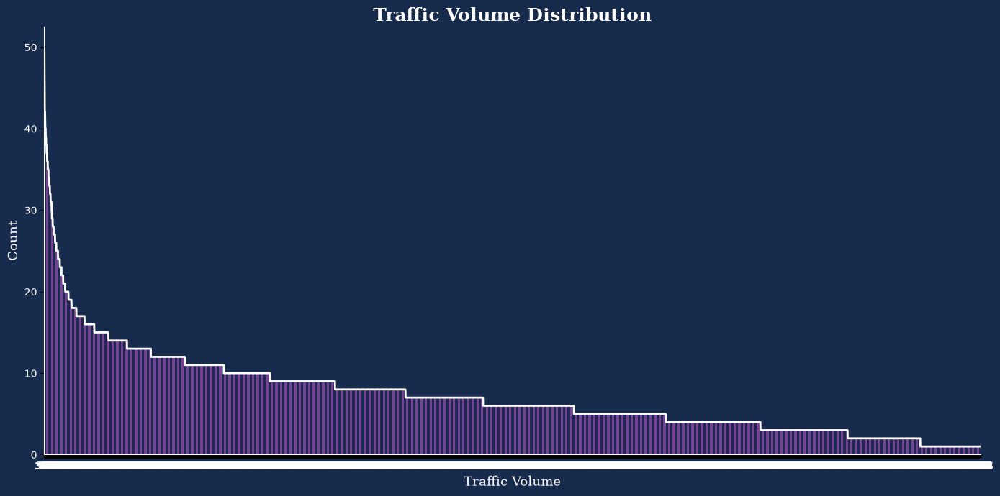

In [19]:
counts = Traffic['traffic_volume'].value_counts()

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#172B4D')
ax.set_facecolor('#172B4D')

counts.plot(
    kind='bar',
    ax=ax,
    color="#7B3F98"
)

plt.plot(
    range(len(counts)),
    counts.values,
    color='white',
    linewidth=2
)

plt.xlabel(
    'Traffic Volume',
    fontsize=13,
    fontfamily='serif',
    color='white'
)

plt.ylabel(
    'Count',
    fontsize=13,
    fontfamily='serif',
    color='white'
)

plt.title(
    'Traffic Volume Distribution',
    fontsize=18,
    fontweight='bold',
    fontfamily='serif',
    color='white'
)

plt.xticks(rotation=0, color='white')
plt.yticks(color='white')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('white')
ax.spines['bottom'].set_color('white')

plt.tight_layout()
plt.show()

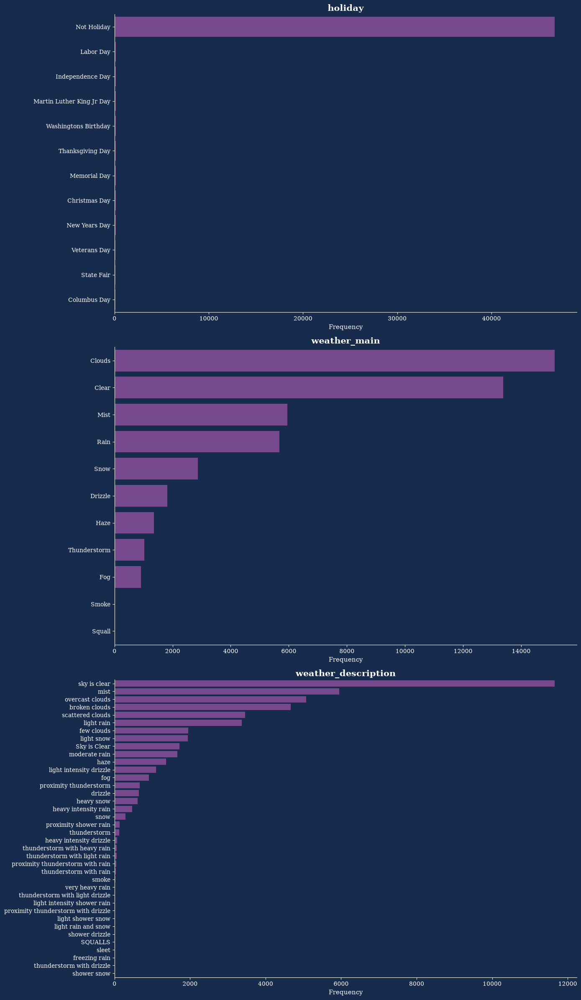

In [20]:
fig, axes = plt.subplots(
    nrows=len(cat_vars),
    ncols=1,
    figsize=(14, 8 * len(cat_vars)),
    facecolor="#172B4D"
)

axes = np.atleast_1d(axes)

for i, var in enumerate(cat_vars):

    counts = Traffic[var].value_counts()

    axes[i].set_facecolor("#172B4D")

    sns.barplot(
        x=counts.values,
        y=counts.index,
        ax=axes[i],
        color="#7B3F98"
    )

    axes[i].set_title(
        var,
        fontsize=15,
        fontweight='bold',
        fontfamily='serif',
        color='white'
    )

    axes[i].set_xlabel(
        'Frequency',
        fontsize=11,
        fontfamily='serif',
        color='white'
    )

    axes[i].set_ylabel('')

    axes[i].tick_params(
        axis='both',
        colors='white'
    )

    # Serif font for tick labels
    for label in axes[i].get_xticklabels():
        label.set_fontfamily('serif')

    for label in axes[i].get_yticklabels():
        label.set_fontfamily('serif')

    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].spines['left'].set_color('white')
    axes[i].spines['bottom'].set_color('white')


plt.tight_layout()
plt.show()

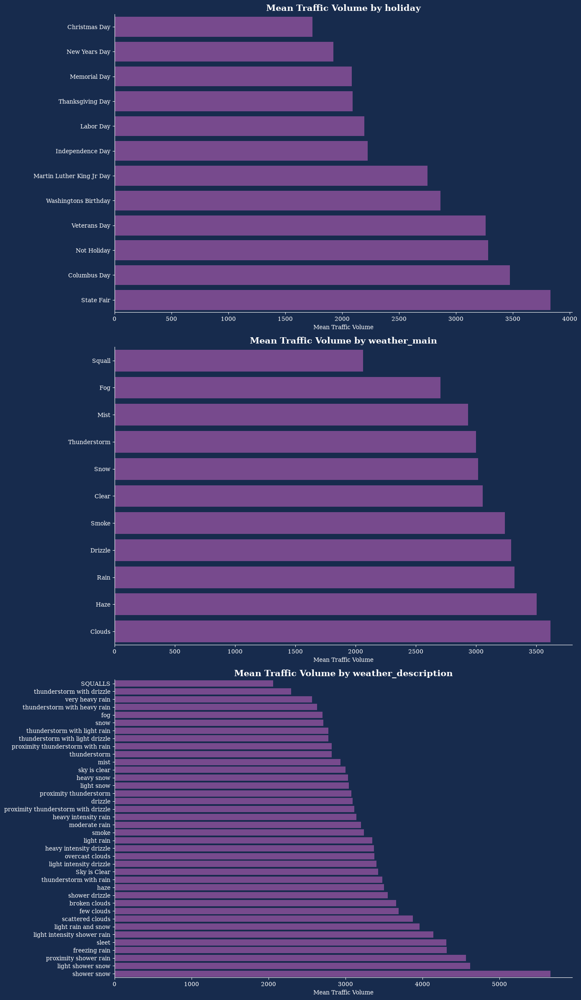

In [21]:
fig, axes = plt.subplots(
    nrows=len(cat_vars),
    ncols=1,
    figsize=(14, 8 * len(cat_vars)),
    facecolor="#172B4D"
)

axes = np.atleast_1d(axes)

for i, var in enumerate(cat_vars):

    mean_traffic = Traffic.groupby(var)['traffic_volume'].mean().sort_values()

    axes[i].set_facecolor("#172B4D")

    sns.barplot(
        x=mean_traffic.values,
        y=mean_traffic.index,
        ax=axes[i],
        color="#7B3F98"
    )

    axes[i].set_title(
        f'Mean Traffic Volume by {var}',
        fontsize=15,
        fontweight='bold',
        fontfamily='serif',
        color='white'
    )

    axes[i].set_xlabel(
        'Mean Traffic Volume',
        fontsize=10,
        fontfamily='serif',
        color='white'
    )

    axes[i].set_ylabel('')

    axes[i].tick_params(
        axis='both',
        colors='white'
    )

    for label in axes[i].get_xticklabels():
        label.set_fontfamily('serif')

    for label in axes[i].get_yticklabels():
        label.set_fontfamily('serif')

    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].spines['left'].set_color('white')
    axes[i].spines['bottom'].set_color('white')


plt.tight_layout()
plt.show()

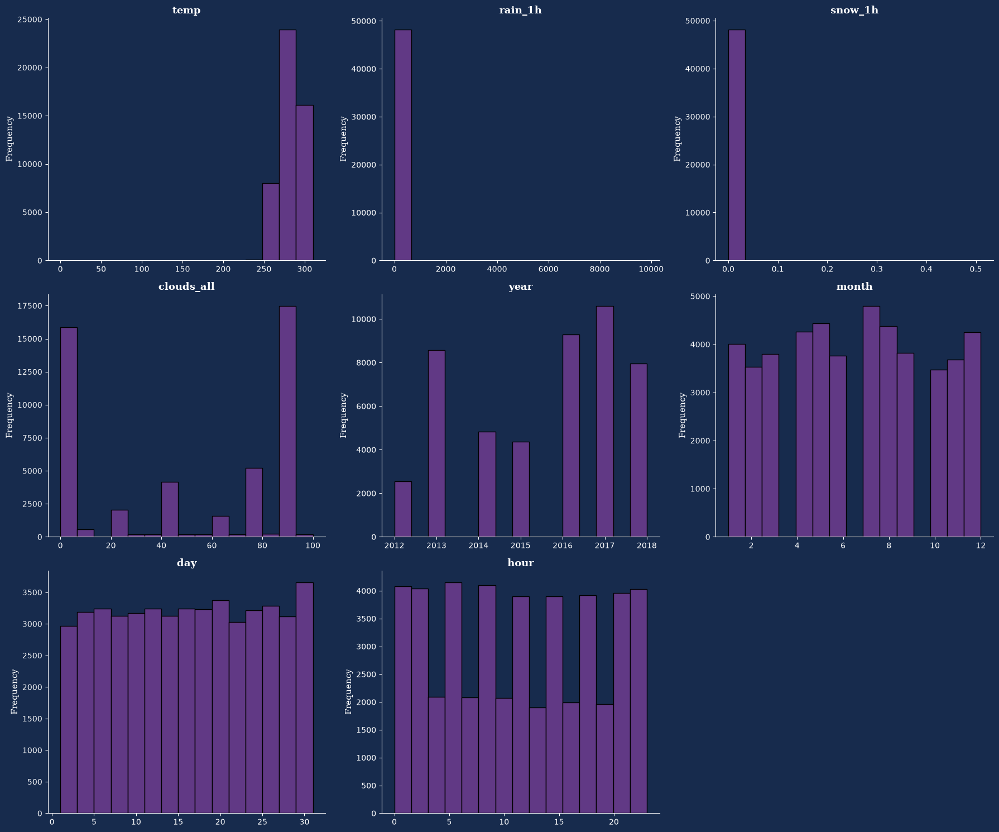

In [22]:
con_vars_ = [var for var in con_vars if var != 'traffic_volume']

n = len(con_vars_)
ncols = 3
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(18, 5 * nrows),
    facecolor="#172B4D"
)

axes = np.atleast_1d(axes).flatten()

for i, var in enumerate(con_vars_):

    ax = axes[i]
    ax.set_facecolor("#172B4D")

    sns.histplot(
        data=Traffic,
        x=var,
        bins=15,
        ax=ax,
        color="#7B3F98"
    )

    # Set x-axis according to the actual range of each variable
    xmin = Traffic[var].min()
    xmax = Traffic[var].max()
    padding = (xmax - xmin) * 0.05

    ax.set_xlim(xmin - padding, xmax + padding)

    ax.set_title(
        var,
        fontsize=13,
        fontweight='bold',
        fontfamily='serif',
        color='white'
    )

    ax.set_xlabel('')
    ax.set_ylabel(
        'Frequency',
        fontsize=11,
        fontfamily='serif',
        color='white'
    )

    ax.tick_params(axis='both', colors='white')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('white')
    ax.spines['bottom'].set_color('white')

for j in range(n, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()

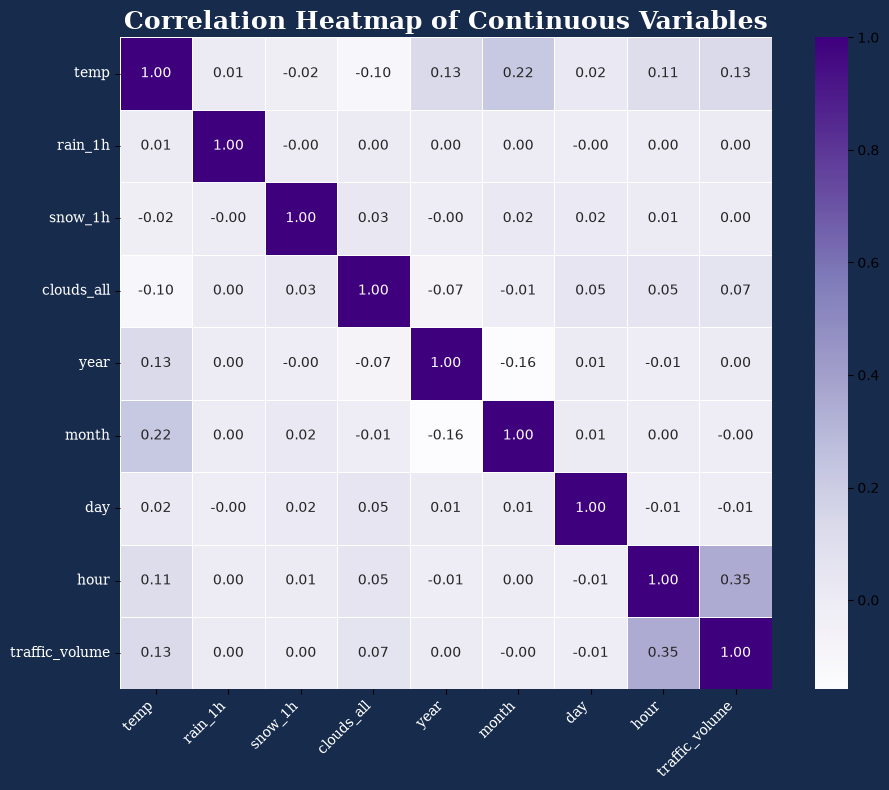

In [23]:
corr = Traffic[con_vars].corr()

plt.figure(figsize=(10, 8), facecolor="#172B4D")

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='Purples',
    linewidths=0.5,
    square=True
)

plt.title(
    'Correlation Heatmap of Continuous Variables',
    fontsize=18,
    fontweight='bold',
    fontfamily='serif',
    color='white'
)

plt.xticks(
    fontfamily='serif',
    color='white',
    rotation=45,
    ha='right'
)

plt.yticks(
    fontfamily='serif',
    color='white',
    rotation=0
)

plt.tight_layout()
plt.show()

<a id="4"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 0 0 14px 0;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">Data Cleaning &amp; Feature Engineering</h2></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.1 — Getting Started</h3></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">This section continues from the <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Traffic</code> DataFrame built in the EDA section above, so nothing the EDA already did is repeated here:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Exact duplicate rows</b> were already removed there (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">drop_duplicates()</code>); an assertion in 4.3.1 confirms the count.</li><li style="margin-bottom:4px;"><b>Date parts</b>: <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">date_time</code> was already split into <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code>; those columns are reused instead of being extracted again.</li><li style="margin-bottom:4px;"><b>Holiday labels</b> were rebuilt there for exploration only. Holiday/event information is not part of the features in this section.</li></ul><p style="margin:0 0 8px 0;">A second, untouched read of the CSV (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">raw</code>) is loaded for one purpose only: the audit in 4.2 must describe the data <b>before any change</b>, and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Traffic</code> no longer qualifies (rows were dropped, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">holiday</code> was overwritten and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">date_time</code> was removed). No cleaning is ever applied to <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">raw</code>.</p><p style="margin:0 0 8px 0;"><b>Team decisions applied in this section:</b> the weather label columns (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_main</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code>) and all holiday/event features are excluded from the features, and temperature is converted from Kelvin to °C.</p></div>

In [24]:
RAIN_MAX_PLAUSIBLE = 100.0     # mm/h; next-highest real value in the data is ~55 mm/h
LOW_VOLUME_THRESHOLD = 100     # vehicles/h
RUSH_HOURS = [6, 7, 8, 15, 16, 17]
INTERP_MAX_HOURS = 48          # max span (between valid neighbours) temperature interpolation may bridge
TEMP_SENTINELS = [276.793, 297.888]   # stuck / placeholder temperatures, in raw Kelvin (found in audit 4.2.4)
KELVIN_OFFSET = 273.15         # degrees C = K - 273.15

# Read-only baseline for the audit in 4.2 ("before any changes"); never cleaned.
raw = pd.read_csv("Metro_Interstate_Traffic_Volume.csv", parse_dates=['date_time'])
print('raw shape:', raw.shape)

raw shape: (48204, 9)


In [25]:
# Chart theme: same palette and fonts as the EDA charts above
# (dark navy background, purple, white serif text, no top/right spines)
THEME_BG = '#172B4D'
THEME_PURPLE = '#7B3F98'
THEME_LAVENDER = '#D8D6FF'
THEME_ACCENT = '#F5B841'     # highlight colour for raw values / anomalies


def style_axes(ax, title=None, xlabel=None, ylabel=None, title_size=13):
    """Apply the notebook's dark theme to one axes."""
    ax.set_facecolor(THEME_BG)
    if title is not None:
        ax.set_title(title, fontsize=title_size, fontweight='bold', fontfamily='serif', color='white')
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=11, fontfamily='serif', color='white')
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=11, fontfamily='serif', color='white')
    ax.tick_params(axis='both', colors='white', labelfontfamily='serif')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('white')
    ax.spines['bottom'].set_color('white')


def style_legend(ax, **kwargs):
    """Legend that matches the dark theme."""
    return ax.legend(frameon=False, labelcolor='white', prop={'family': 'serif', 'size': 9}, **kwargs)

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.2 — Data Quality Audit (Before Any Changes)</h3></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.1 — Missing Values</h4></div>

In [26]:
audit = pd.DataFrame({'dtype': raw.dtypes.astype(str),
                      'n_missing': raw.isna().sum(),
                      'missing_%': (raw.isna().mean() * 100).round(2),
                      'n_unique': raw.nunique()})
audit

,dtype,n_missing,missing_%,n_unique
holiday,str,48143,99.87,11
temp,float64,0,0.00,5843
rain_1h,float64,0,0.00,372
snow_1h,float64,0,0.00,12
clouds_all,int64,0,0.00,60
weather_main,str,0,0.00,11
weather_description,str,0,0.00,38
date_time,datetime64[us],0,0.00,40575
traffic_volume,int64,0,0.00,6704


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Only <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">holiday</code> has missing values (48,143 rows, 99.87 %). This is a <b>structural</b> absence meaning "no holiday/event on that day", not a lost measurement, so it must not be imputed with a mean/median. Holiday/event information is excluded from the features in this section (team decision), so the column is simply not carried forward.</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.2 — Duplicate Rows: Two Distinct Types</h4></div>

In [27]:
n_exact = int(raw.duplicated().sum())
tmp = raw.drop_duplicates()
grp = tmp.groupby('date_time')
sizes = grp.size()

dup_report = pd.Series({
    'exact duplicate rows': n_exact,
    'rows after exact-dedup': len(tmp),
    'unique timestamps': sizes.size,
    'timestamps with >1 row': int((sizes > 1).sum()),
    'groups where traffic_volume differs': int((grp.traffic_volume.nunique() > 1).sum()),
    'groups where temp differs': int((grp.temp.nunique() > 1).sum()),
    'groups where rain_1h differs': int((grp.rain_1h.nunique() > 1).sum()),
    'groups where snow_1h differs': int((grp.snow_1h.nunique() > 1).sum()),
    'groups where clouds_all differs': int((grp.clouds_all.nunique() > 1).sum()),
    'groups where weather_main differs': int((grp.weather_main.nunique() > 1).sum()),
    'groups where weather_description differs': int((grp.weather_description.nunique() > 1).sum()),
})
print(dup_report.to_string())
print('\nlargest group example:')
tmp[tmp.date_time == sizes.idxmax()]

exact duplicate rows                           17
rows after exact-dedup                      48187
unique timestamps                           40575
timestamps with >1 row                       5430
groups where traffic_volume differs             0
groups where temp differs                      78
groups where rain_1h differs                    9
groups where snow_1h differs                    0
groups where clouds_all differs                32
groups where weather_main differs            5349
groups where weather_description differs     5386

largest group example:


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
5249,NaN,274.79,0.0,0.0,90,Mist,mist,2013-04-18 22:00:00,1532
5250,NaN,274.79,0.0,0.0,90,Drizzle,light intensity drizzle,2013-04-18 22:00:00,1532
5251,NaN,274.79,0.0,0.0,90,Rain,light rain,2013-04-18 22:00:00,1532
5252,NaN,274.79,0.0,0.0,90,Rain,moderate rain,2013-04-18 22:00:00,1532
5253,NaN,274.79,0.0,0.0,90,Snow,heavy snow,2013-04-18 22:00:00,1532
5254,NaN,274.79,0.0,0.0,90,Snow,snow,2013-04-18 22:00:00,1532


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><b>Result:</b> there are 17 completely duplicate rows (already dropped in the EDA section), but more importantly <b>thousands of timestamps still have more than one row</b> (5,430). Within these groups <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">traffic_volume</code> never varies and the numeric weather values are almost always identical; what varies are the <b>textual weather labels</b> (several weather reports recorded for a single hour). The correct treatment is therefore to aggregate into a single row per hour, and <b>the main challenge is selecting the weather label</b>, not the numeric values.</p><p style="margin:0 0 8px 0;"><b>Note:</b> <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">drop_duplicates()</code> alone (as done in the EDA section) is not enough: every hour with several reports is still counted several times, which skews EDA means and correlations toward high-frequency hours.</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.3 — Physically Impossible Values</h4></div>

In [28]:
zero_k = raw[raw.temp <= 0]
print('rows with temp <= 0 K:', len(zero_k))
valid_c = raw.loc[raw.temp > 0, 'temp'] - KELVIN_OFFSET
print('valid temp range (°C): %.2f -> %.2f' % (valid_c.min(), valid_c.max()))
print(zero_k.groupby(zero_k.date_time.dt.date).agg(n=('temp', 'size'), first=('date_time', 'min'), last=('date_time', 'max')))

print('\ntop-5 rain_1h:', raw.rain_1h.nlargest(5).tolist())
print('snow_1h max:', raw.snow_1h.max(), '| clouds_all range:', raw.clouds_all.min(), '-', raw.clouds_all.max())
print('negative values:', int((raw[['rain_1h', 'snow_1h', 'clouds_all']] < 0).sum().sum()))
(raw[raw.rain_1h > RAIN_MAX_PLAUSIBLE]
    .assign(temp_c=lambda x: (x.temp - KELVIN_OFFSET).round(2))
    [['date_time', 'temp_c', 'rain_1h', 'weather_main', 'weather_description', 'traffic_volume']])

rows with temp <= 0 K: 10
valid temp range (°C): -29.76 -> 36.92
            n               first                last
date_time                                            
2014-01-31  4 2014-01-31 03:00:00 2014-01-31 06:00:00
2014-02-02  6 2014-02-02 03:00:00 2014-02-02 08:00:00

top-5 rain_1h: [9831.3, 55.63, 44.45, 31.75, 28.7]
snow_1h max: 0.51 | clouds_all range: 0 - 100
negative values: 0


,date_time,temp_c,rain_1h,weather_main,weather_description,traffic_volume
24872,2016-07-11 17:00:00,28.96,9831.3,Rain,very heavy rain,5535


In [29]:
# context of the rain anomaly: neighbouring hours
w = raw[(raw.date_time >= '2016-07-11 14:00') & (raw.date_time <= '2016-07-11 21:00')]
w[['date_time', 'rain_1h', 'weather_description', 'traffic_volume']]

,date_time,rain_1h,weather_description,traffic_volume
24869,2016-07-11 14:00:00,0.0,overcast clouds,4456
24870,2016-07-11 15:00:00,0.0,proximity thunderstorm,4858
24871,2016-07-11 16:00:00,0.0,proximity thunderstorm,5934
24872,2016-07-11 17:00:00,9831.3,very heavy rain,5535
24873,2016-07-11 18:00:00,0.0,proximity thunderstorm,3900
24874,2016-07-11 19:00:00,0.0,broken clouds,2856
24875,2016-07-11 20:00:00,0.0,thunderstorm,2506
24876,2016-07-11 21:00:00,0.0,thunderstorm with light rain,2062


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Temperature of 0 Kelvin</b> (−273.15 °C, absolute zero) = sensor failure, not actual weather. Two continuous multi-hour windows (2014-01-31 and 2014-02-02) during the coldest hours of the night.</li><li style="margin-bottom:4px;"><b>Precipitation of 9,831.3 mm/h</b>: the next highest value in the dataset is ≈ 55.6, and its neighbouring hours record 0 precipitation. This is a logging/unit error.</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">snow_1h</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">clouds_all</code>: normal and within a plausible range.</li></ul></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.4 — "Stuck" / Placeholder Temperatures: A More Subtle Issue</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Temperature is typically recorded on a 0.01 Kelvin grid; however, a small number of values have <b>three decimal places</b>. Among these, two values appear repeatedly:</p></div>

In [30]:
off_grid = raw[(raw.temp * 100).round(4) % 1 != 0]
vc = off_grid.temp.value_counts()
print('off-grid temp values:', len(off_grid), '| most repeated (K):')
print(vc.head(4).to_string())

for v in TEMP_SENTINELS:
    r_ = raw[raw.temp == v]
    ts_ = pd.Series(sorted(r_.date_time.unique()))
    runs = (ts_.diff() != pd.Timedelta(hours=1)).cumsum()
    print(f'\ntemp == {v} K ({v - KELVIN_OFFSET:.1f} °C): {len(r_)} rows, {r_.date_time.min()} -> {r_.date_time.max()}, '
          f'longest consecutive run = {int(ts_.groupby(runs).size().max())} hours')

off-grid temp values: 1124 | most repeated (K):
temp
276.793    78
297.888    43
281.372     6
281.469     6

temp == 276.793 K (3.6 °C): 78 rows, 2013-10-22 05:00:00 -> 2014-01-23 08:00:00, longest consecutive run = 33 hours

temp == 297.888 K (24.7 °C): 43 rows, 2016-07-18 18:00:00 -> 2016-07-20 12:00:00, longest consecutive run = 43 hours


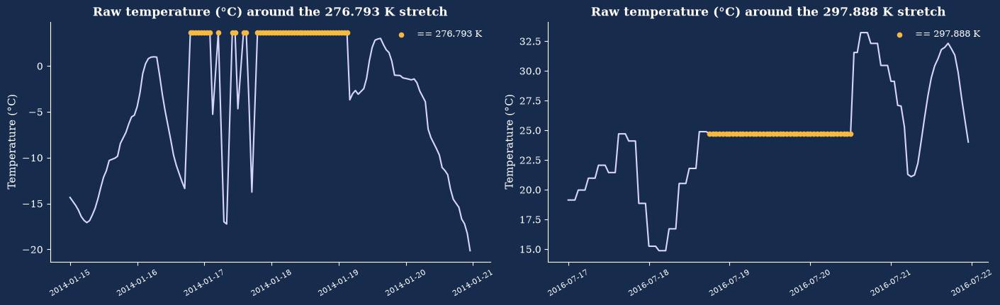

In [31]:
raw_med = raw.groupby('date_time').temp.median().sort_index()     # hourly median of the raw reports (K)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), facecolor=THEME_BG, constrained_layout=True)
for ax, (a, b), v in zip(axes, [('2014-01-15', '2014-01-20'), ('2016-07-17', '2016-07-21')], TEMP_SENTINELS):
    w = raw_med[a:b] - KELVIN_OFFSET
    ax.plot(w.index, w.values, color=THEME_LAVENDER, lw=1.5)
    hit = w[raw_med[a:b] == v]
    ax.scatter(hit.index, hit.values, color=THEME_ACCENT, s=20, zorder=3, label=f'== {v} K')
    style_axes(ax, title=f'Raw temperature (°C) around the {v} K stretch', ylabel='Temperature (°C)', title_size=12)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    style_legend(ax)
plt.show()

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">276.793 K</code> (= <b>+3.6 °C</b>) appears across 78 rows (between October 2013 and January 2014; 70 of these rows are in January 2014 alone). The left plot shows that in the middle of a severe cold wave, where adjacent true temperatures range from −10 °C down to −26 °C, the reading abruptly jumps to +3.6 °C and sometimes stays flat for 33 consecutive hours.</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">297.888 K</code> (= +24.7 °C) repeats across 43 <b>consecutive</b> hours (2016-07-18 to 2016-07-20) with no diurnal cycle whatsoever, which is physically impossible in midsummer.</li></ul><p style="margin:0 0 8px 0;">These are "stuck" or placeholder values produced by the sensor or upstream data, <b>not real-world weather</b>. Unlike 0 K, they cannot be caught by a simple physical range check and are only exposed by examining repetition patterns. Left uncorrected, temperatures in these windows stay off by up to ~30 °C. Moreover, when several hourly readings are aggregated with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">median</code>, mixing stuck values with true values produces artificial intermediate figures.</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.5 — Remaining Temperature Jumps (After Discarding Stuck Values)</h4></div>

In [32]:
t_chk = raw[(raw.temp > 0) & (~raw.temp.isin(TEMP_SENTINELS))].groupby('date_time').temp.median().sort_index()
adj = t_chk.index.to_series().diff() == pd.Timedelta(hours=1)
jump = t_chk.diff().abs()[adj]
print('adjacent-hour temp jumps > 10 °C (after masking sentinels):', int((jump > 10).sum()))
jump[jump > 10].rename('abs jump (°C)').to_frame()

adjacent-hour temp jumps > 10 °C (after masking sentinels): 1


,abs jump (°C)
date_time,
2013-02-03 18:00:00,14.14


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Removing the stuck values drops the number of severe hour-over-hour temperature spikes (&gt; 10 °C) from 8 down to 1, confirming that the other seven were purely artificial. The sole remaining incident is an isolated point on 2013-02-03 at 18:00, which reverts to baseline within two hours. While suspect, it is <b>unprovable</b> (a rapid weather front cannot be ruled out), so we leave it untouched. The governing rule: only modify what the evidence definitively supports.</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.6 — Categorical Text: Casing Inconsistencies and Pair Alignment (main, description)</h4></div>

In [33]:
print('weather_description unique (raw):', raw.weather_description.nunique())
print('after lower/strip              :', raw.weather_description.str.lower().str.strip().nunique())
print(raw.weather_description[raw.weather_description.str.contains('clear|squall', case=False)].value_counts().to_dict())

pairs = raw.assign(d=raw.weather_description.str.lower().str.strip()).groupby('d').weather_main.nunique()
print('descriptions linked to >1 weather_main:', int((pairs > 1).sum()))

weather_description unique (raw): 38
after lower/strip              : 37
{'sky is clear': 11665, 'Sky is Clear': 1726, 'SQUALLS': 4}
descriptions linked to >1 weather_main: 0


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Sky is Clear</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">sky is clear</code> represent the same category and are merged via lowercasing. <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">SQUALLS</code> exists only in uppercase (with no lowercase counterpart); it does not merge with another entry, but is lowercased for consistency.</li><li style="margin-bottom:4px;">Every <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code> maps to exactly one <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_main</code>; in other words, <b>the pair (main, description) is a single semantic unit.</b> This becomes essential for the aggregation step:</li></ul></div>

In [34]:
tmp2 = raw.drop_duplicates().assign(weather_description=lambda x: x.weather_description.str.lower().str.strip())

def det_mode(s):
    vc = s.value_counts()
    return sorted(vc[vc == vc.max()].index)[0]

naive = tmp2.groupby('date_time').agg(m=('weather_main', det_mode), d=('weather_description', det_mode))
valid_pairs = set(map(tuple, tmp2[['weather_main', 'weather_description']].drop_duplicates().values))
incoherent = [(m, d) for m, d in zip(naive.m, naive.d) if (m, d) not in valid_pairs]
print('timestamps that would get an IMPOSSIBLE (main, description) pair:', len(incoherent))
print(pd.Series(incoherent).value_counts().head(5).to_string())

timestamps that would get an IMPOSSIBLE (main, description) pair: 1542
(Mist, light snow)                 468
(Mist, light rain)                 400
(Mist, heavy snow)                 217
(Mist, heavy intensity rain)       195
(Drizzle, heavy intensity rain)     57


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">If the <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">mode</code> of each column is computed independently, it creates combinations such as <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Mist</code> + <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">light snow</code> across more than 1,500 hours: combinations that never existed in the original dataset. <b>Solution:</b> the <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">mode</code> must be computed on the *pair* (main, description) as a single entity.</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.7 — Temporal Coverage, Gaps, and Time Zone</h4></div>

expected hourly slots: 52,551 | present: 40,575 | absent: 11,976 (22.8%)

gaps longer than 48h:
  2014-08-08 01:00:00 -> 2015-06-11 20:00:00   (307 days 19 h)
  2013-10-27 01:00:00 -> 2013-11-06 04:00:00   (10 days 3 h)
  2015-06-14 20:00:00 -> 2015-06-19 18:00:00   (4 days 22 h)
  2014-04-29 08:00:00 -> 2014-05-04 05:00:00   (4 days 21 h)
  2015-10-23 11:00:00 -> 2015-10-27 08:00:00   (3 days 21 h)
  2014-07-27 16:00:00 -> 2014-07-30 09:00:00   (2 days 17 h)


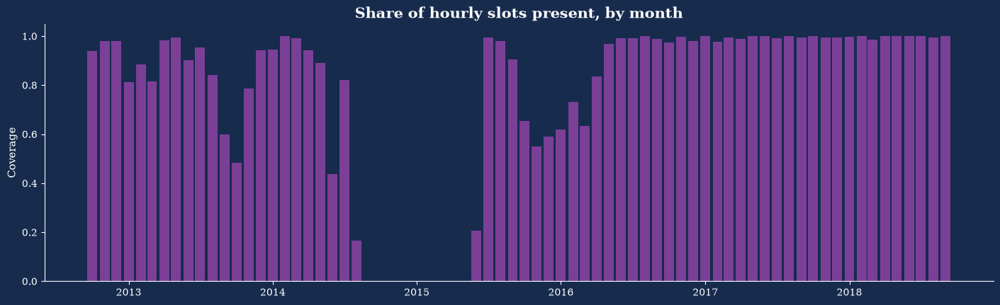

In [35]:
ts = pd.DatetimeIndex(sorted(raw.date_time.unique()))
full = pd.date_range(ts.min(), ts.max(), freq='h')
print(f'expected hourly slots: {len(full):,} | present: {len(ts):,} | absent: {len(full)-len(ts):,} ({100*(len(full)-len(ts))/len(full):.1f}%)')

gaps = pd.Series(ts[1:] - ts[:-1], index=ts[1:])
big = gaps[gaps > pd.Timedelta(hours=48)].sort_values(ascending=False)
print('\ngaps longer than 48h:')
for end, g in big.head(6).items():
    print(f'  {end - g} -> {end}   ({g.days} days {g.seconds//3600} h)')

cov = pd.Series(1, index=ts).resample('MS').sum() / (pd.Series(1, index=full).resample('MS').sum())
fig, ax = plt.subplots(figsize=(14, 4.2), facecolor=THEME_BG, constrained_layout=True)
ax.bar(cov.index, cov.values, width=25, color=THEME_PURPLE)
style_axes(ax, title='Share of hourly slots present, by month', ylabel='Coverage', title_size=15)
ax.set_ylim(0, 1.05)
plt.show()

In [36]:
t0 = raw.drop_duplicates('date_time').set_index('date_time').traffic_volume
wd0 = t0[t0.index.dayofweek < 5]
for m, name in [(1, 'January'), (7, 'July')]:
    s = wd0[wd0.index.month == m]
    print(name, 'top-3 weekday hours:', s.groupby(s.index.hour).mean().nlargest(3).index.tolist())
print('hours present on 2014-03-09 (US spring-forward day):', [int(h) for h in sorted(raw[raw.date_time.dt.strftime('%Y-%m-%d') == '2014-03-09'].date_time.dt.hour.unique())[:5]], '...')

January top-3 weekday hours: [16, 17, 7]
July top-3 weekday hours: [16, 7, 17]
hours present on 2014-03-09 (US spring-forward day): [0, 1, 3, 4, 5] ...


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;">About <b>23 % of all hourly slots are missing</b> from the dataset (11,976 of 52,551), with the largest gap spanning ≈ 10 months (2014-08 to 2015-06). The "previous row" can therefore be months in the past: a naive <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">shift()</code> would build invalid lag features, and missing target values <b>must never be interpolated/imputed</b>.</li><li style="margin-bottom:4px;">Morning and evening peak hours are identical across winter and summer, and 02:00 is omitted on the spring-forward day; this confirms that <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">date_time</code> is effectively <b>local wall-clock time (observing DST)</b>, despite the dataset documentation specifying CST. Consequently <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code> and peak-hour features need no DST adjustment.</li></ul></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.8 — Target Variable: Near-Zero Clusters</h4></div>

In [37]:
tv = raw.drop_duplicates('date_time').set_index('date_time').sort_index().traffic_volume
print('1st percentile of traffic by hour (min over hours):', int(tv.groupby(tv.index.hour).quantile(0.01).min()))

low = tv[tv < LOW_VOLUME_THRESHOLD]
cl = (low.index.to_series().diff() > pd.Timedelta(hours=3)).cumsum()
low_clusters = low.groupby(cl).agg(start=lambda s: s.index.min(), end=lambda s: s.index.max(), n='size', median_tv='median')
print(f'timestamps with traffic_volume < {LOW_VOLUME_THRESHOLD}: {len(low)} in {len(low_clusters)} contiguous clusters')
low_clusters

1st percentile of traffic by hour (min over hours): 209
timestamps with traffic_volume < 100: 46 in 9 contiguous clusters


,start,end,n,median_tv
date_time,,,,
0,2015-07-24 22:00:00,2015-07-24 22:00:00,1,65.0
1,2015-07-25 08:00:00,2015-07-25 09:00:00,2,1.0
2,2016-07-09 20:00:00,2016-07-09 23:00:00,4,10.5
3,2016-07-22 22:00:00,2016-07-23 04:00:00,7,7.0
4,2016-07-23 09:00:00,2016-07-24 04:00:00,20,4.0
5,2016-07-24 09:00:00,2016-07-24 11:00:00,2,19.5
6,2016-07-24 16:00:00,2016-07-24 16:00:00,1,44.0
7,2016-08-31 23:00:00,2016-09-01 02:00:00,4,7.0
8,2016-09-07 23:00:00,2016-09-08 03:00:00,5,3.0


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Even in the dead of night, the lowest 1 % of traffic volume still registers several hundred vehicles; counts between 1 and 15 are therefore <b>never typical for any hour</b>. These values are not scattered randomly; they appear in several <b>continuous clusters</b> (sometimes persisting for ~20 consecutive hours) during the summers of 2015 and 2016. This suggests either a hardware/sensor failure or an actual highway closure. Because the data itself does not provide enough information to determine the root cause, we <b>leave the target untouched</b> and simply set a <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_low_volume</code> flag so the modeling team can decide how to handle it (e.g., segmenting it in error analysis).</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.9 — Audit Summary</h4></div>

In [38]:
pd.DataFrame([
    ('exact duplicate rows', n_exact, 'already dropped in the EDA section (verified in 4.3.1)'),
    ('timestamps with >1 report', int((sizes > 1).sum()), 'collapse to 1 row/hour (median numerics, joint-mode weather pair)'),
    ('temp <= 0 K', int((raw.temp <= 0).sum()), 'NaN -> time interpolation + flag'),
    ('temp stuck at 276.793 / 297.888 K', int(raw.temp.isin(TEMP_SENTINELS).sum()), 'NaN (before collapse) -> time interpolation + flag'),
    ('rain_1h > 100', int((raw.rain_1h > RAIN_MAX_PLAUSIBLE).sum()), 'NaN -> same-label median + flag'),
    ('"Sky is Clear" casing', int((raw.weather_description == 'Sky is Clear').sum()), 'lower/strip BEFORE collapsing'),
    ('holiday NaN (structural)', int(raw.holiday.isna().sum()), 'column excluded from the features (team decision); no imputation'),
    ('weather label columns', 2, 'helper only inside 4.3 (merge hours, impute rain), then dropped from the features'),
    ('absent hourly slots', len(full) - len(ts), 'document; never fill target'),
    (f'traffic_volume < {LOW_VOLUME_THRESHOLD} (unique ts)', len(low), 'keep, flag only'),
], columns=['finding', 'count', 'action'])

,finding,count,action
0,exact duplicate rows,17,already dropped in the EDA section (verified i...
1,timestamps with >1 report,5430,"collapse to 1 row/hour (median numerics, joint..."
2,temp <= 0 K,10,NaN -> time interpolation + flag
3,temp stuck at 276.793 / 297.888 K,121,NaN (before collapse) -> time interpolation + ...
4,rain_1h > 100,1,NaN -> same-label median + flag
5,"""Sky is Clear"" casing",1726,lower/strip BEFORE collapsing
6,holiday NaN (structural),48143,column excluded from the features (team decisi...
7,weather label columns,2,"helper only inside 4.3 (merge hours, impute ra..."
8,absent hourly slots,11976,document; never fill target
9,traffic_volume < 100 (unique ts),46,"keep, flag only"


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.3 — Data Cleaning (Step-by-Step)</h3></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The order is deliberate: <b>EDA frame → text normalization → impossible values to <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">NaN</code> (before aggregation) → hourly aggregation → imputation → Kelvin to °C → weather labels dropped → target flagging.</b></p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.1 — Starting Point: the EDA Frame</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Traffic</code> from the EDA section is the starting point. It already has the exact duplicates removed and the <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code> columns, but <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">date_time</code> was dropped there. So:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">date_time</code> is rebuilt from those four columns and verified against the raw timestamps (no second parse or extraction).</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">holiday</code> is dropped: holiday/event information is excluded from the features (team decision).</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day</code> (day of the month) is dropped: it carries no meaningful traffic signal.</li><li style="margin-bottom:4px;">Nothing is deduplicated again: assertions confirm the row count equals <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">raw</code> minus the exact duplicates. <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Traffic</code> itself is copied and never modified.</li></ul></div>

In [39]:
df = Traffic.copy()
df['date_time'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
df = df.drop(columns=['holiday', 'day']).sort_values('date_time').reset_index(drop=True)

# the EDA section already removed the exact duplicates, so there is nothing left to drop here
assert len(df) == len(raw) - n_exact
assert set(df.date_time) == set(raw.date_time)
print('rows:', len(raw), '->', len(df), f'(the EDA section already dropped {n_exact} exact duplicates)')

rows: 48204 -> 48187 (the EDA section already dropped 17 exact duplicates)


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.2 — Text Normalization (Before Aggregation, so <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Sky is Clear</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">sky is clear</code> Group Together)</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The weather label columns are <b>helper columns only</b> in this section: they are needed to merge duplicate hourly reports and to impute the single rain outlier (4.3.7), and they are dropped from the features in 4.3.8.</p></div>

In [40]:
for c in ['weather_main', 'weather_description']:
    df[c] = df[c].str.strip()
df['weather_description'] = df['weather_description'].str.lower()
assert 'SQUALLS' not in set(df.weather_description)
print('unique weather_description:', df.weather_description.nunique())

unique weather_description: 37


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.3 — Impossible/Stuck Values → NaN (Before Aggregation) + Flagging</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">If aggregated beforehand, the <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">median</code> across several reports would blend faulty values with valid readings, making them undetectable later; they are therefore converted to <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">NaN</code> first. Invalid temperature = "≤ 0 K" or "one of the two stuck values". Temperatures are still in Kelvin at this point because the stuck values are matched on the raw Kelvin numbers; the conversion to °C happens in 4.3.6.</p></div>

In [41]:
bad_temp = (df.temp <= 0) | df.temp.isin(TEMP_SENTINELS)
df.loc[bad_temp, 'temp'] = np.nan
df['qa_rain_invalid'] = (df.rain_1h > RAIN_MAX_PLAUSIBLE).astype('int8')
df.loc[df.qa_rain_invalid == 1, 'rain_1h'] = np.nan
print('temp reports -> NaN:', int(bad_temp.sum()), '| rain -> NaN:', int(df.qa_rain_invalid.sum()))

assert (df.groupby('date_time').traffic_volume.nunique() == 1).all()
print('target constant within every timestamp group: OK')

temp reports -> NaN: 131 | rain -> NaN: 1
target constant within every timestamp group: OK


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.4 — Aggregating into "One Row Per Hour"</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;">Numeric measurements (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">temp</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">snow_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">clouds_all</code>): <b>median</b> (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">NaN</code> values are ignored).</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">traffic_volume</code>: <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">first</code> (its constancy was verified above).</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code>: <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">first</code> (constant inside an hour; the EDA section's columns are reused, not re-extracted).</li><li style="margin-bottom:4px;">Weather labels (helper only): <b>mode on the pair (main, description)</b>; ties are broken alphabetically to guarantee deterministic, reproducible results.</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">clouds_all</code> may end up with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">.5</code> after the median; it is rounded to keep integer values.</li></ul></div>

In [42]:
num = df.groupby('date_time').agg(
    temp=('temp', 'median'), rain_1h=('rain_1h', 'median'), snow_1h=('snow_1h', 'median'),
    clouds_all=('clouds_all', 'median'), traffic_volume=('traffic_volume', 'first'),
    year=('year', 'first'), month=('month', 'first'), hour=('hour', 'first'),
    qa_rain_invalid=('qa_rain_invalid', 'max'),
    qa_n_reports=('traffic_volume', 'size'))

pc = (df.groupby(['date_time', 'weather_main', 'weather_description']).size().rename('n').reset_index()
        .sort_values(['date_time', 'n', 'weather_main', 'weather_description'], ascending=[True, False, True, True])
        .drop_duplicates('date_time').set_index('date_time')[['weather_main', 'weather_description']])

df = num.join(pc).sort_index()
df['clouds_all'] = np.rint(df['clouds_all']).astype('int16')

assert df.index.is_unique
# valid_pairs comes from the audit in 4.2.6
assert all((m, d) in valid_pairs for m, d in zip(df.weather_main, df.weather_description))
print('shape:', df.shape, '| every (main, description) pair exists in the raw data: OK')
print('remaining NaN:'); print(df.isna().sum()[lambda s: s > 0].to_string())

shape: (40575, 12) | every (main, description) pair exists in the raw data: OK
remaining NaN:
temp       127
rain_1h      1


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.5 — Invalid Temperatures (0 K and Stuck Values): Time-Based Interpolation</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Temperature is a continuous time-series signal; interpolating between the two valid hours directly before and after the anomaly window is far more accurate than a global mean/median imputation. Safety constraint: interpolation is applied only if the gap between the two valid neighbours is <b>at most 48 hours</b>. Longer windows (gaps between valid neighbours of up to ~44 hours in this data) carry lower confidence and cannot capture the diurnal cycle, which is why <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_temp_imputed</code> tracks them so they can be isolated during error analysis. (Alternative: keep <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">NaN</code> for <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">temp</code> across these hours and use a model that handles missing values natively.)</p></div>

In [43]:
df['qa_temp_imputed'] = df.temp.isna().astype('int8')
bad_idx = df.index[df.temp.isna()]
valid_idx = df.index[df.temp.notna()]
rows = []
for ts_ in bad_idx:
    pos = valid_idx.searchsorted(ts_)
    prev_, next_ = valid_idx[pos - 1], valid_idx[pos]
    span = (next_ - prev_) / pd.Timedelta(hours=1)
    assert span <= INTERP_MAX_HOURS, f'gap too wide around {ts_}: {span} h'
    rows.append((ts_, span))

df['temp'] = df['temp'].interpolate(method='time', limit=INTERP_MAX_HOURS, limit_area='inside')
assert df.temp.isna().sum() == 0
assert not df.loc[df.qa_temp_imputed == 0, 'temp'].isin(TEMP_SENTINELS).any(), 'sentinel temp still present'
print('timestamps imputed:', len(bad_idx), '| max bridged span (h):', max(r[1] for r in rows))

timestamps imputed: 127 | max bridged span (h): 44.0


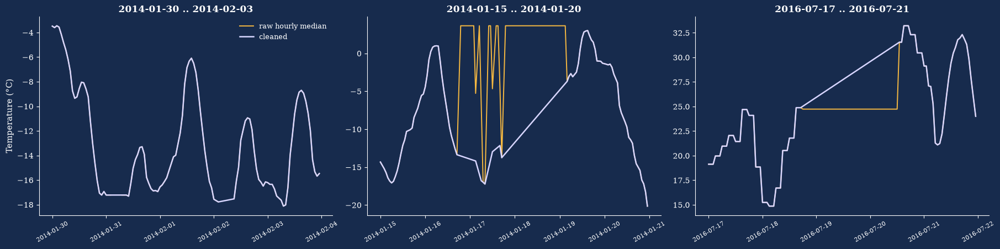

In [44]:
# before / after: raw hourly median (raw_med, from 4.2.4) vs the cleaned series
wins = [('2014-01-30', '2014-02-03'), ('2014-01-15', '2014-01-20'), ('2016-07-17', '2016-07-21')]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4), facecolor=THEME_BG, constrained_layout=True)
for i, (ax, (a, b)) in enumerate(zip(axes, wins)):
    before = raw_med[a:b].where(raw_med[a:b] > 0) - KELVIN_OFFSET      # 0 K shown as a gap
    ax.plot(before.index, before.values, color=THEME_ACCENT, lw=1.4, label='raw hourly median')
    after = df.loc[a:b, 'temp'] - KELVIN_OFFSET
    ax.plot(after.index, after.values, color=THEME_LAVENDER, lw=1.8, label='cleaned')
    style_axes(ax, title=f'{a} .. {b}', ylabel='Temperature (°C)' if i == 0 else None, title_size=12)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
style_legend(axes[0])
plt.show()

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.6 — Kelvin → Celsius</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Cleaning and interpolation above work on the raw Kelvin values. From here on the project uses <b>°C</b>: <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">temp_c = temp − 273.15</code>, rounded to the sensor's 0.01 resolution, and the Kelvin column is dropped so that no Kelvin value reaches the feature set.</p></div>

In [45]:
df['temp_c'] = (df['temp'] - KELVIN_OFFSET).round(2)
df = df.drop(columns=['temp'])
print('temp_c range: %.1f .. %.1f °C' % (df.temp_c.min(), df.temp_c.max()))

temp_c range: -29.8 .. 36.9 °C


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.7 — Rain Outlier 9,831.3: Imputation via Label-Matched Median</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The value is imputed with the <b>median</b> of the records sharing the exact same <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code> (this row itself holds "very heavy rain"). Rationale: it stays consistent with the row's label while remaining well within the empirical range of the dataset. <b>Capping at 100</b> would create an artificial value larger than any other reading in the data, which <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">log1p</code> then amplifies. The overall impact on the model is negligible (a single row out of more than 40,000), and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_rain_invalid</code> keeps track of it; should the team prefer an alternative (e.g., setting it to 0 like the adjacent hours), only this individual cell needs modification.</p></div>

In [46]:
bad = df.rain_1h.isna()
ref = df[~bad].groupby('weather_description').rain_1h.median()
print('rows to impute:', int(bad.sum()), '| label:', df.loc[bad, 'weather_description'].tolist())
df.loc[bad, 'rain_1h'] = df.loc[bad, 'weather_description'].map(ref)
assert df.rain_1h.isna().sum() == 0
print('imputed rain_1h (mm/h):', df.loc[df.qa_rain_invalid == 1, 'rain_1h'].round(2).tolist(),
      '| max rain now:', df.rain_1h.max())

rows to impute: 1 | label: ['very heavy rain']
imputed rain_1h (mm/h): [23.75] | max rain now: 55.63


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.8 — Weather Label Columns Removed from the Features</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_main</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code> have now served their purpose (merging duplicate hourly reports and imputing the rain outlier), so they are dropped: weather labels are <b>not</b> features. The numeric weather measurements (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">temp_c</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">snow_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">clouds_all</code>) are kept.</p></div>

In [47]:
df = df.drop(columns=['weather_main', 'weather_description'])
print('columns now:', list(df.columns))

columns now: ['rain_1h', 'snow_1h', 'clouds_all', 'traffic_volume', 'year', 'month', 'hour', 'qa_rain_invalid', 'qa_n_reports', 'qa_temp_imputed', 'temp_c']


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.9 — Flagging Suspect Target Values (Without Modifying the Target)</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The target <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">traffic_volume</code> is never modified. Hours below 100 vehicles/h are only flagged with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_low_volume</code> (see 4.2.8).</p></div>

In [48]:
df['qa_low_volume'] = (df.traffic_volume < LOW_VOLUME_THRESHOLD).astype('int8')
print('flagged:', int(df.qa_low_volume.sum()), f'({100*df.qa_low_volume.mean():.2f}% of rows)')

flagged: 46 (0.11% of rows)


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.4 — Feature Engineering</h3></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.4.1 — Calendar and Cyclical Features</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Retained: <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code> (long-term trend), <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_of_week</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_weekend</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">season</code>. <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code> come straight from the EDA section; only <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_of_week</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_weekend</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">season</code> and the sin/cos encodings are new here. <b>Deliberately omitted:</b> <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_name</code> (redundant with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_of_week</code>), <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">week_of_year</code>/<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_of_year</code> (high collinearity with month) and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day</code> (day of the month; carries no meaningful traffic signal).</p><p style="margin:0 0 8px 0;">Hour, day of the week and month are cyclical: 23 and 0 differ by 23 units numerically, yet they are adjacent in time. A <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">sin/cos</code> transformation resolves this for linear models and neural networks (tree-based models do not need it).</p></div>

In [49]:
idx = df.index
df['day_of_week'] = idx.dayofweek          # 0 = Monday
df['is_weekend'] = (df.day_of_week >= 5).astype('int8')
df['season'] = pd.Categorical(df.month.map({12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
                                            6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Fall', 10: 'Fall', 11: 'Fall'}),
                              categories=['Winter', 'Spring', 'Summer', 'Fall'])
for name, val, period in [('hour', df.hour, 24), ('dow', df.day_of_week, 7), ('month', df.month - 1, 12)]:
    df[f'{name}_sin'] = np.sin(2 * np.pi * val / period)
    df[f'{name}_cos'] = np.cos(2 * np.pi * val / period)
df[['year', 'month', 'hour', 'day_of_week', 'season', 'hour_sin', 'hour_cos']].head(3)

,year,month,hour,day_of_week,season,hour_sin,hour_cos
date_time,,,,,,,
2012-10-02 09:00:00,2012,10,9,1,Fall,0.707107,-0.707107
2012-10-02 10:00:00,2012,10,10,1,Fall,0.500000,-0.866025
2012-10-02 11:00:00,2012,10,11,1,Fall,0.258819,-0.965926


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.4.2 — Rush Hour</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Rush hours are established from domain knowledge (business commuting patterns); the data only <b>validates</b> them. Key takeaway: weekends show an entirely different pattern (no morning peak), so <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_rush_hour</code> is active on <b>workdays</b> only.</p></div>

hours >= 85% of weekday peak: [6, 7, 8, 15, 16, 17] | chosen a priori: [6, 7, 8, 15, 16, 17]


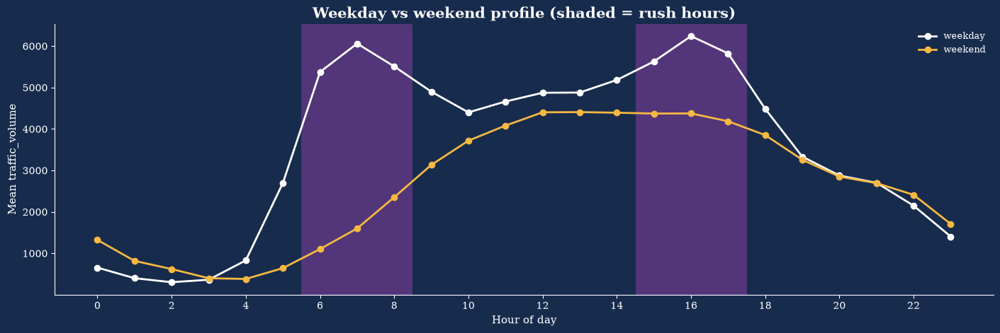

mean traffic: rush 5773 | non-rush 2756


In [50]:
prof = df.groupby(['hour', 'is_weekend']).traffic_volume.mean().unstack('is_weekend')
prof.columns = ['weekday', 'weekend']

data_rush = prof.index[prof.weekday >= 0.85 * prof.weekday.max()].tolist()
print('hours >= 85% of weekday peak:', data_rush, '| chosen a priori:', RUSH_HOURS)
assert data_rush == RUSH_HOURS

fig, ax = plt.subplots(figsize=(14, 4.6), facecolor=THEME_BG, constrained_layout=True)
for h in RUSH_HOURS:
    ax.axvspan(h - .5, h + .5, color=THEME_PURPLE, alpha=.6, linewidth=0)
ax.plot(prof.index, prof.weekday, marker='o', color='white', lw=2, label='weekday')
ax.plot(prof.index, prof.weekend, marker='o', color=THEME_ACCENT, lw=2, label='weekend')
ax.set_xticks(range(0, 24, 2))
style_axes(ax, title='Weekday vs weekend profile (shaded = rush hours)', xlabel='Hour of day',
           ylabel='Mean traffic_volume', title_size=15)
style_legend(ax)
plt.show()

df['is_rush_hour'] = ((df.day_of_week < 5) & df.hour.isin(RUSH_HOURS)).astype('int8')
print('mean traffic: rush %.0f | non-rush %.0f' % (df.loc[df.is_rush_hour == 1, 'traffic_volume'].mean(),
                                                  df.loc[df.is_rush_hour == 0, 'traffic_volume'].mean()))

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.4.3 — Weather Features (Numeric)</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">temp_c</code>: temperature in °C (cleaned in 4.3.5 and converted from Kelvin in 4.3.6).</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_freezing</code>: binary flag for temperatures below 0 °C.</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_raining</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_snowing</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">precipitation_flag</code>: about 95 % of rows record zero precipitation; a binary presence/absence flag provides a discrete signal that gets drowned out in the raw continuous values.</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h_log1p</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">snow_1h_log1p</code>: highly right-skewed distributions, log-transformed with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">log1p</code> for scale-sensitive models.</li></ul><p style="margin:0 0 8px 0;">The weather <b>labels</b> (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_main</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code>) are intentionally not features (see 4.3.8).</p></div>

In [51]:
df['is_freezing'] = (df.temp_c < 0).astype('int8')
df['is_raining'] = (df.rain_1h > 0).astype('int8')
df['is_snowing'] = (df.snow_1h > 0).astype('int8')
df['precipitation_flag'] = ((df.rain_1h > 0) | (df.snow_1h > 0)).astype('int8')
df['rain_1h_log1p'] = np.log1p(df.rain_1h)
df['snow_1h_log1p'] = np.log1p(df.snow_1h)
print('share with rain: %.3f | snow: %.4f' % (df.is_raining.mean(), df.is_snowing.mean()))

share with rain: 0.051 | snow: 0.0008


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.5 — Final Validation (Explicit Asserts) and Export</h3></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The next cell puts the columns in their final order (target, features, then <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_*</code> columns) and runs explicit <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">assert</code> checks, so the notebook fails loudly if any step is broken or reordered. The clean dataset is then saved to <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">../data/data_cleaning.csv</code>.</p></div>

In [52]:
# ---- final column layout ----
TARGET = 'traffic_volume'
QA_COLS = [c for c in df.columns if c.startswith('qa_')]      # all audit/trace columns carry the qa_ prefix
FEATURES = [c for c in df.columns if c != TARGET and c not in QA_COLS]
df = df[[TARGET] + FEATURES + QA_COLS].sort_index()

# ---- assertions: the notebook fails loudly if anything is violated ----
raw_tv = raw.drop_duplicates('date_time').set_index('date_time').traffic_volume
assert df.index.is_unique and df.index.is_monotonic_increasing
assert len(df) == raw.date_time.nunique()
assert df.isna().sum().sum() == 0, 'unexpected missing values'
assert df[TARGET].equals(raw_tv.reindex(df.index)), 'target was modified!'
assert 'temp' not in df.columns and df.temp_c.between(-50, 50).all(), 'temperature must be in degrees C'
assert df.rain_1h.between(0, 60).all() and df.snow_1h.between(0, 1).all() and df.clouds_all.between(0, 100).all()
assert df.loc[df.is_weekend == 1, 'is_rush_hour'].sum() == 0
assert not df.columns.str.contains('holiday|state_fair|weather').any(), 'weather/holiday columns must not be in the output'
assert all(not c.startswith('qa_') for c in FEATURES) and TARGET not in FEATURES
print('ALL ASSERTIONS PASSED')
print('rows x cols:', df.shape, '| features:', len(FEATURES), '| qa columns:', QA_COLS)

ALL ASSERTIONS PASSED
rows x cols: (40575, 28) | features: 23 | qa columns: ['qa_rain_invalid', 'qa_n_reports', 'qa_temp_imputed', 'qa_low_volume']


In [53]:
dictionary = pd.DataFrame({'dtype': df[FEATURES + QA_COLS].dtypes.astype(str),
                           'n_unique': df[FEATURES + QA_COLS].nunique(),
                           'role': ['feature'] * len(FEATURES) + ['QA / do NOT train on'] * len(QA_COLS)})
dictionary

,dtype,n_unique,role
rain_1h,float64,375,feature
snow_1h,float64,12,feature
clouds_all,int16,64,feature
year,int32,7,feature
month,int32,12,feature
hour,int32,24,feature
temp_c,float64,5460,feature
day_of_week,int32,7,feature
is_weekend,int8,2,feature
season,category,4,feature


In [54]:
OUTPUT_PATH = 'data_cleaning.csv'
out = df.reset_index()
out.to_csv(OUTPUT_PATH, index=False)
print('saved:', OUTPUT_PATH, '| shape:', out.shape)

saved: data_cleaning.csv | shape: (40575, 29)


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.6 — Summary Report</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<p style="margin:0 0 8px 0;">Starting from the EDA frame, we <b>audited the raw CSV before changing anything</b>, cleaned it in a deliberate order, engineered features, and validated everything with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px;">assert</code> checks.</p>
<p style="margin:0;"><b>Result:</b> 48,204 raw rows → <b>40,575 rows (one per hour)</b>, 0 missing values, 23 features + the target + 4 <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px;">qa_*</code> columns. The target <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px;">traffic_volume</code> was never modified (asserted against the raw data).</p>
</div>

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">Problems found and how we solved them</h4></div>

<table style="width:100%; border-collapse:collapse; font-family:'Segoe UI', sans-serif; font-size:0.95em; color:#1f2937; direction:ltr; text-align:left;">
<thead><tr style="background:#1e3a5f; color:#ffffff;">
<th style="padding:8px 10px; border:1px solid #b8c2cc;">Problem (evidence)</th>
<th style="padding:8px 10px; border:1px solid #b8c2cc;">Solution</th>
</tr></thead>
<tbody>
<tr><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Duplicates</b>: 17 exact rows, plus 5,430 hours with 2–6 reports (the target is identical inside each hour; only the weather report differs)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Exact duplicates dropped in the EDA. Merged to <b>one row per hour</b>: median for numeric columns, mode on the <b>(main, description) pair</b> for labels, so no impossible pairs such as <i>Mist + light snow</i>.</td></tr>
<tr style="background:#f4f7fb;"><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Invalid temperatures</b>: 0 K (10 rows) and stuck values 276.793 K / 297.888 K (121 rows, up to 43 consecutive hours, off by up to ~30 °C)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Set to <code>NaN</code> <b>before</b> merging, time-interpolated (max 48 h between valid neighbours), converted to °C, flagged with <code>qa_temp_imputed</code> (127 hours).</td></tr>
<tr><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Rain = 9,831.3 mm/h</b> (next highest real value: 55.6; neighbouring hours: 0)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Imputed with the median of rows sharing the same label (≈ 23.75 mm) instead of an arbitrary cap; flagged with <code>qa_rain_invalid</code>.</td></tr>
<tr style="background:#f4f7fb;"><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Label casing</b>: <i>Sky is Clear</i> vs <i>sky is clear</i></td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Lower-cased and stripped before merging.</td></tr>
<tr><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b><code>holiday</code> is 99.87 % empty</b> (structural absence)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Not imputed. Holiday/event information and the weather labels are excluded from the features (team decision); the labels are used only as helpers, then dropped.</td></tr>
<tr style="background:#f4f7fb;"><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Missing hours</b>: 22.8 % of hourly slots, with a 307-day gap (Aug 2014 → Jun 2015)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Documented only. The target is never filled and no lag features are built.</td></tr>
<tr><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Suspicious target values</b>: 46 hours below 100 vehicles/h in 9 clusters (sensor outage or road closure, which cannot be told apart)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Kept unchanged and flagged with <code>qa_low_volume</code>.</td></tr>
</tbody>
</table>

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">Features, limitations and next steps</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<ul style="margin:4px 0 8px 22px; padding:0;">
<li><b>Features:</b> calendar (<code>year</code>, <code>month</code>, <code>day_of_week</code>, <code>hour</code>, <code>is_weekend</code>, <code>season</code>), sin/cos encodings of hour, day of week and month, weekday-only <code>is_rush_hour</code> (hours 6–8 and 15–17), and numeric weather (<code>temp_c</code>, freezing/rain/snow/precipitation flags, <code>log1p</code> of rain and snow, plus raw <code>rain_1h</code>, <code>snow_1h</code>, <code>clouds_all</code>).</li>
<li><b>Limitations:</b> 127 interpolated temperature hours lose their daily cycle; one suspicious but unprovable temperature jump (2013-02-03 18:00) was left as is; the 307-day gap splits the series in two.</li>
<li><b>For modeling:</b> use a time-based train/test split, never train on <code>qa_*</code> columns (<code>qa_low_volume</code> would leak the target), fit scalers and encoders on the training set only, and re-run the EDA statistics on the cleaned file.</li>
</ul>
<p style="margin:0;"><b>Output:</b> <code>../data/data_cleaning.csv</code> (40,575 × 29, including <code>date_time</code>).</p>
</div>

<a id="5"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">Linear Regression</h2></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.1 — Setup and Carried-Over Assumptions</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">This notebook starts from the clean file written by section 4.5 of the cleaning notebook (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">../data/data_cleaning.csv</code>, one row per hour). <b>Every decision made there is kept</b>:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Target</b> <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">traffic_volume</code> is never modified, filled or imputed.</li><li style="margin-bottom:4px;"><b>Features</b> = the 23 columns built in 4.4 (calendar, sin/cos encodings, rush hour, numeric weather). Columns with the prefix <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_</code> are audit columns and are <b>never used as features</b> (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_low_volume</code> would leak the target).</li><li style="margin-bottom:4px;"><b>No</b> holiday/event columns and <b>no</b> weather label columns in the baseline (team decision). Section 6 tests that decision explicitly.</li><li style="margin-bottom:4px;"><b>Temperature</b> is in &deg;C (cleaned and interpolated in 4.3.5/4.3.6).</li><li style="margin-bottom:4px;"><b>Time-based split</b>: the oldest 80&nbsp;% of the hours train the model, the newest 20&nbsp;% test it. No random shuffling, because neighbouring hours are strongly correlated and shuffling would leak.</li><li style="margin-bottom:4px;"><b>Scaler and encoder are fitted on the training set only</b> (inside a scikit-learn <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Pipeline</code>).</li><li style="margin-bottom:4px;"><b>No lag features</b>: 22.8&nbsp;% of the hourly slots are missing, so a &ldquo;previous row&rdquo; can be months away.</li></ul></div>

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">5.1.1 — Imports, Paths and Chart Theme</h4></div>

In [55]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

CLEAN_PATH = '../data/data_cleaning.csv'                      # written by section 4.5
RAW_PATH = '../data/Metro_Interstate_Traffic_Volume.csv'      # only needed in section 6 (weather labels)
TARGET = 'traffic_volume'
TEST_FRACTION = 0.20

# Chart theme: identical to the cleaning notebook (dark navy background, purple, white serif text)
THEME_BG = '#172B4D'
THEME_PURPLE = '#7B3F98'
THEME_LAVENDER = '#D8D6FF'
THEME_ACCENT = '#F5B841'


def style_axes(ax, title=None, xlabel=None, ylabel=None, title_size=13):
    # Apply the notebook's dark theme to one axes.
    ax.set_facecolor(THEME_BG)
    if title is not None:
        ax.set_title(title, fontsize=title_size, fontweight='bold', fontfamily='serif', color='white')
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=11, fontfamily='serif', color='white')
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=11, fontfamily='serif', color='white')
    ax.tick_params(axis='both', colors='white', labelfontfamily='serif')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('white')
    ax.spines['bottom'].set_color('white')


def style_legend(ax, **kwargs):
    return ax.legend(frameon=False, labelcolor='white', prop={'family': 'serif', 'size': 9}, **kwargs)

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.2 — Load the Clean Data and Split by Time</h3></div>

In [56]:
df = (pd.read_csv("data_cleaning.csv", parse_dates=['date_time'])
        .sort_values('date_time').set_index('date_time'))

QA_COLS = [c for c in df.columns if c.startswith('qa_')]
FEATURES = [c for c in df.columns if c != TARGET and c not in QA_COLS]
CAT_COLS = ['season']
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

assert df.index.is_unique and df.index.is_monotonic_increasing
assert df.isna().sum().sum() == 0
assert len(FEATURES) == 23, 'the cleaning notebook defines 23 features'
assert not any(c.startswith('qa_') for c in FEATURES)
print('rows:', len(df), '| features:', len(FEATURES), '| qa columns (never features):', QA_COLS)

# ---- chronological split ----
split_idx = int(len(df) * (1 - TEST_FRACTION))
train, test = df.iloc[:split_idx], df.iloc[split_idx:]
print(f'train: {len(train):,} rows  {train.index.min()} -> {train.index.max()}')
print(f'test : {len(test):,} rows  {test.index.min()} -> {test.index.max()}')
print('years in train:', sorted(train.year.unique().tolist()), '| years in test:', sorted(test.year.unique().tolist()))

rows: 40575 | features: 23 | qa columns (never features): ['qa_rain_invalid', 'qa_n_reports', 'qa_temp_imputed', 'qa_low_volume']
train: 32,460 rows  2012-10-02 09:00:00 -> 2017-10-26 17:00:00
test : 8,115 rows  2017-10-26 18:00:00 -> 2018-09-30 23:00:00
years in train: [2012, 2013, 2014, 2015, 2016, 2017] | years in test: [2017, 2018]


In [57]:
print("Unique timestamps:", df.index.is_unique)
print("Sorted timestamps:", df.index.is_monotonic_increasing)
print("Duplicate timestamps:", df.index.duplicated().sum())
print(df.index[df.index.duplicated(keep=False)].unique()[:10])

Unique timestamps: True
Sorted timestamps: True
Duplicate timestamps: 0
DatetimeIndex([], dtype='datetime64[us]', name='date_time', freq=None)


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><b>Note on <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code>:</b> with a time-based split, the test period can contain a <b>year value that never appears in training</b>. A linear model then extrapolates the year trend linearly. This is realistic for forecasting but can inflate test error; compare the models below with and without <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code> if the test error looks odd.</p></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.3 — Helper Functions (Pipeline, Metrics, Diagnostics)</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Everything below is reusable: each model in this notebook is fitted by the single function <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">run_model()</code> and stored in the dictionary <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">RESULTS</code>. <b>Because of that, any optional section can be deleted without breaking the rest.</b></p></div>

In [58]:
RESULTS = {}


def adj_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


def score(y, yhat, n_params):
    r2 = r2_score(y, yhat)
    return {'R2': r2,
            'Adj_R2': adj_r2(r2, len(y), n_params),
            'MAE': mean_absolute_error(y, yhat),
            'RMSE': float(np.sqrt(mean_squared_error(y, yhat)))}


def build_pipeline(num_cols, cat_cols=()):
    # numeric columns -> StandardScaler, categorical -> one-hot (first level dropped as reference)
    steps = [('num', StandardScaler(), list(num_cols))]
    if len(cat_cols):
        steps.append(('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), list(cat_cols)))
    prep = ColumnTransformer(steps, verbose_feature_names_out=False)
    prep.set_output(transform='pandas')
    return Pipeline([('prep', prep), ('lr', LinearRegression())])


def run_model(name, data, num_cols, cat_cols=(), train_filter=None, log_target=False, note=''):
    # Fit one linear regression on the chronological train part and score it on the test part.
    # train_filter: optional boolean Series (same index as data) that removes rows from TRAINING only.
    # log_target:   fit on log1p(traffic_volume), then back-transform; all metrics stay in vehicles/hour.
    cat_cols = list(cat_cols)
    cols = list(num_cols) + cat_cols
    tr, te = data.iloc[:split_idx], data.iloc[split_idx:]
    if train_filter is not None:
        tr = tr[train_filter.loc[tr.index].values]

    y_tr, y_te = tr[TARGET], te[TARGET]
    y_fit = np.log1p(y_tr) if log_target else y_tr
    pipe = build_pipeline(num_cols, cat_cols).fit(tr[cols], y_fit)

    def predict(d):
        raw_pred = pipe.predict(d[cols])
        return np.clip(np.expm1(raw_pred), 0, None) if log_target else raw_pred

    yhat_tr, yhat_te = predict(tr), predict(te)
    prep = pipe.named_steps['prep']
    n_params = len(prep.get_feature_names_out())
    X_tr = prep.transform(tr[cols])
    res = dict(name=name, note=note, n_train=len(tr), n_features=n_params, log_target=log_target,
               train=score(y_tr, yhat_tr, n_params), test=score(y_te, yhat_te, n_params),
               pipe=pipe, X_tr=X_tr, resid_fit=pd.Series(np.asarray(y_fit) - pipe.predict(tr[cols]), index=tr.index),
               idx_te=te.index, y_te=y_te, yhat_te=pd.Series(yhat_te, index=te.index))
    RESULTS[name] = res
    return res


def metrics_table(results):
    rows = []
    for r in results:
        rows.append({'model': r['name'], 'n_features': r['n_features'], 'n_train': r['n_train'],
                     'train R2': r['train']['R2'], 'test R2': r['test']['R2'], 'test adj R2': r['test']['Adj_R2'],
                     'train RMSE': r['train']['RMSE'], 'test RMSE': r['test']['RMSE'], 'test MAE': r['test']['MAE']})
    return pd.DataFrame(rows).set_index('model').round(3)


def cv_report(num_cols, cat_cols=(), n_splits=5):
    # Expanding-window cross-validation inside the TRAIN part only (the test part is never touched).
    cols = list(num_cols) + list(cat_cols)
    tr = df.iloc[:split_idx]
    rows = []
    for k, (a, b) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(tr), 1):
        pipe = build_pipeline(num_cols, cat_cols).fit(tr.iloc[a][cols], tr.iloc[a][TARGET])
        yh, y = pipe.predict(tr.iloc[b][cols]), tr.iloc[b][TARGET]
        rows.append({'fold': k, 'train rows': len(a), 'validation rows': len(b),
                     'R2': r2_score(y, yh), 'RMSE': np.sqrt(mean_squared_error(y, yh))})
    out = pd.DataFrame(rows).set_index('fold')
    out.loc['mean'] = out.mean()
    return out.round(3)


def diagnostics(res):
    # Six standard evaluation plots for one fitted model (test part).
    y, yh = res['y_te'], res['yhat_te']
    resid = y - yh
    fig, axes = plt.subplots(2, 3, figsize=(19, 10), facecolor=THEME_BG, constrained_layout=True)

    ax = axes[0, 0]
    ax.scatter(yh, y, s=6, alpha=0.35, color=THEME_PURPLE)
    lim = [min(y.min(), yh.min()), max(y.max(), yh.max())]
    ax.plot(lim, lim, color=THEME_ACCENT, lw=1.6, label='perfect prediction')
    style_axes(ax, 'Actual vs Predicted', 'Predicted traffic_volume', 'Actual traffic_volume')
    style_legend(ax)

    ax = axes[0, 1]
    ax.scatter(yh, resid, s=6, alpha=0.35, color=THEME_PURPLE)
    ax.axhline(0, color=THEME_ACCENT, lw=1.6)
    style_axes(ax, 'Residuals vs Predicted', 'Predicted traffic_volume', 'Residual (actual - predicted)')

    ax = axes[0, 2]
    sns.histplot(resid, bins=50, ax=ax, color=THEME_PURPLE)
    ax.axvline(0, color=THEME_ACCENT, lw=1.6)
    style_axes(ax, 'Residual Distribution', 'Residual', 'Frequency')

    ax = axes[1, 0]
    (osm, osr), (slope, intercept, _) = stats.probplot(resid, dist='norm')
    ax.scatter(osm, osr, s=6, alpha=0.5, color=THEME_PURPLE)
    ax.plot(osm, slope * np.asarray(osm) + intercept, color=THEME_ACCENT, lw=1.6)
    style_axes(ax, 'Normal Q-Q Plot of Residuals', 'Theoretical quantiles', 'Sample quantiles')

    ax = axes[1, 1]
    by_hour = resid.groupby(resid.index.hour).agg(['mean', 'std'])
    ax.plot(by_hour.index, by_hour['mean'], color='white', marker='o', lw=2, label='mean residual')
    ax.fill_between(by_hour.index, by_hour['mean'] - by_hour['std'], by_hour['mean'] + by_hour['std'],
                    color=THEME_PURPLE, alpha=0.55, label='+/- 1 std')
    ax.axhline(0, color=THEME_ACCENT, lw=1.4)
    ax.set_xticks(range(0, 24, 2))
    style_axes(ax, 'Residuals by Hour of Day', 'Hour', 'Residual')
    style_legend(ax)

    ax = axes[1, 2]
    last = y.index.max() - pd.Timedelta(days=7)
    w = y.index >= last
    ax.plot(y.index[w], y[w], color='white', lw=1.6, label='actual')
    ax.plot(yh.index[w], yh[w], color=THEME_ACCENT, lw=1.6, label='predicted')
    ax.tick_params(axis='x', rotation=30)
    style_axes(ax, 'Last 7 Days of the Test Period', None, 'traffic_volume')
    style_legend(ax)

    fig.suptitle(res['name'], fontsize=16, fontweight='bold', fontfamily='serif', color='white')
    plt.show()


def plot_coefficients(res, top=None):
    # Coefficients of the standardized model: effect on traffic_volume of +1 std (one-hot dummies: vs the reference level).
    names = res['pipe'].named_steps['prep'].get_feature_names_out()
    coef = pd.Series(res['pipe'].named_steps['lr'].coef_, index=names).sort_values(key=np.abs)
    if top:
        coef = coef.iloc[-top:]
    fig, ax = plt.subplots(figsize=(11, 0.38 * len(coef) + 2), facecolor=THEME_BG, constrained_layout=True)
    ax.barh(coef.index, coef.values, color=[THEME_PURPLE if v >= 0 else THEME_ACCENT for v in coef.values])
    ax.axvline(0, color='white', lw=0.8)
    style_axes(ax, 'Coefficients: ' + res['name'], 'Change in traffic_volume (vehicles/hour)')
    plt.show()


def vif_table(X):
    # Variance inflation factor of every column, from first principles (no extra library).
    M = X.values.astype(float)
    out = {}
    for j, name in enumerate(X.columns):
        y = M[:, j]
        A = np.column_stack([np.ones(len(M)), np.delete(M, j, axis=1)])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        r2 = 1 - ((y - A @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out[name] = np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2)
    return pd.Series(out, name='VIF').sort_values(ascending=False)


def assumption_report(res):
    # Residual checks on the TRAINING fit: autocorrelation, heteroscedasticity, normality, multicollinearity.
    e = res['resid_fit'].values
    X = res['X_tr'].values
    dw = np.sum(np.diff(e) ** 2) / np.sum(e ** 2)
    A = np.column_stack([np.ones(len(X)), X])
    e2 = e ** 2
    beta, *_ = np.linalg.lstsq(A, e2, rcond=None)
    r2_bp = 1 - ((e2 - A @ beta) ** 2).sum() / ((e2 - e2.mean()) ** 2).sum()
    lm = len(e) * r2_bp
    p_bp = stats.chi2.sf(lm, X.shape[1])
    summary = pd.Series({'Durbin-Watson (2 = no autocorrelation)': dw,
                         'Breusch-Pagan LM p-value (< 0.05 = heteroscedastic)': p_bp,
                         'residual skewness': stats.skew(e),
                         'residual excess kurtosis': stats.kurtosis(e)}).round(4)
    return summary, vif_table(res['X_tr'])

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.4 — Model A: Baseline Linear Regression (All 23 Features)</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The baseline uses <b>exactly the final feature set of the cleaning notebook</b>: the numeric columns are standardized, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">season</code> is one-hot encoded (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Fall</code> is the reference level). Ordinary least squares, no regularisation.</p><p style="margin:0 0 8px 0;">Variants that change the features, the target or the training rows come later in 5.7, each in its own section.</p></div>

In [59]:
res_a = run_model('A  Baseline (23 features)', df, NUM_COLS, CAT_COLS,
                  note='final feature set of section 4.4, OLS, no transformation of the target')
print('number of model inputs after encoding:', res_a['n_features'])
metrics_table([res_a])

number of model inputs after encoding: 25


,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">5.4.1 — Time-Series Cross-Validation (Inside the Training Part)</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Five expanding windows, each validated on the block that follows it. A large spread between folds means the relationship is <b>not stable over time</b>; a mean much worse than the single test score would hint at an unlucky test split.</p></div>

In [60]:
cv_report(NUM_COLS, CAT_COLS)

,train rows,validation rows,R2,RMSE
fold,,,,
1,5410.0,5410.0,0.395,1554.976
2,10820.0,5410.0,0.871,717.445
3,16230.0,5410.0,0.837,811.881
4,21640.0,5410.0,0.849,738.993
5,27050.0,5410.0,0.867,724.985
mean,16230.0,5410.0,0.764,909.656


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">5.4.2 — Evaluation Plots</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">What to look for:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Actual vs Predicted</b>: points should hug the line. Horizontal bands mean the model cannot separate rush hours from quiet hours.</li><li style="margin-bottom:4px;"><b>Residuals by Hour</b>: a smooth wave here means the model misses the daily double peak (a linear model cannot bend). This is the main reason for the variants in 5.7.</li><li style="margin-bottom:4px;"><b>Q-Q plot and histogram</b>: heavy tails or a bimodal histogram show that one equation is trying to describe two regimes (weekday vs weekend, day vs night).</li><li style="margin-bottom:4px;"><b>Residuals vs Predicted</b>: a funnel shape means the error grows with the traffic level (heteroscedasticity).</li></ul></div>

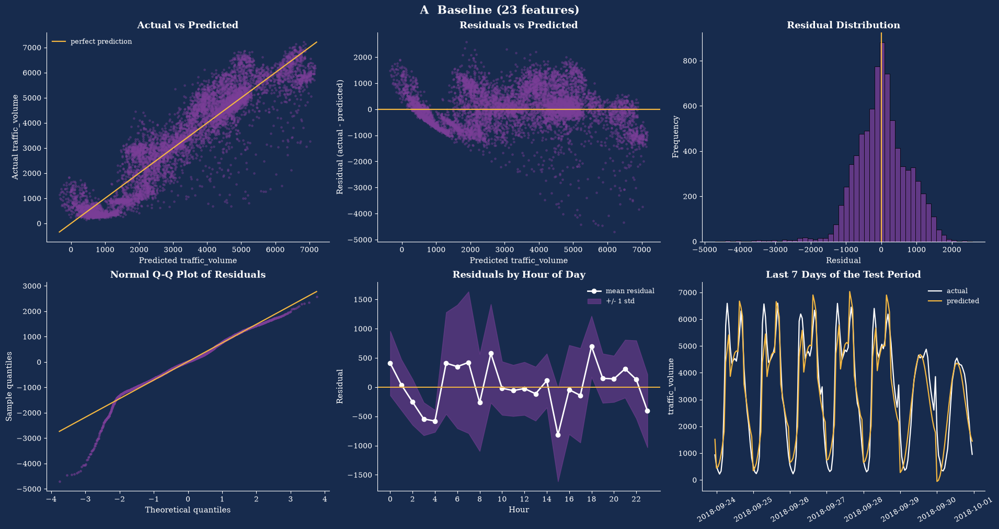

In [61]:
diagnostics(res_a)

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">5.4.3 — Coefficients</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Numeric inputs are standardized, so every bar reads &ldquo;change in vehicles/hour for a +1 standard deviation move of that input, all else equal&rdquo;; the one-hot <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">season</code> bars are differences versus the reference season. Several inputs describe the <b>same</b> thing in different forms (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour_sin</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour_cos</code>; <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h_log1p</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_raining</code>), so their individual coefficients are not interpretable on their own; see the VIF table below.</p></div>

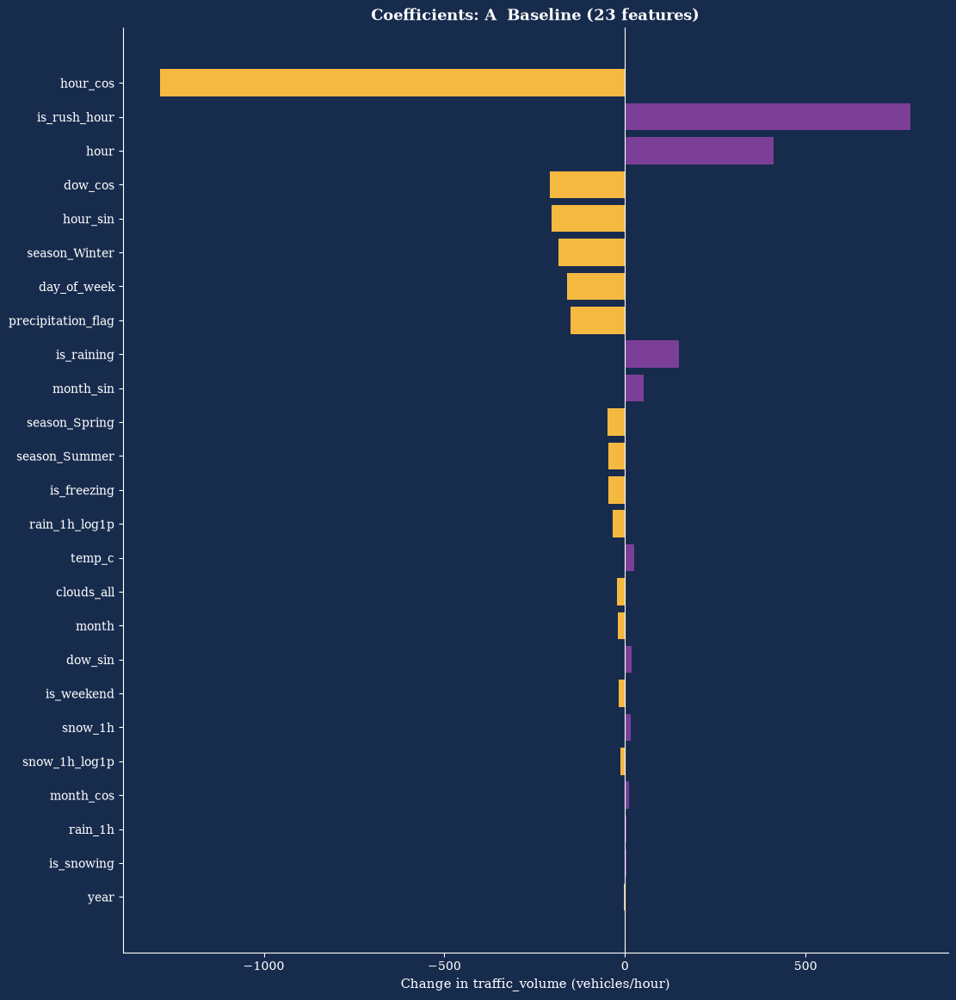

In [62]:
plot_coefficients(res_a)

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.5 — Checking the Linear-Regression Assumptions</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">OLS predictions are still usable when assumptions are violated, but <b>standard errors, p-values and coefficient signs are not</b>. Four checks on the training residuals:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Durbin-Watson</b>: values far below 2 mean consecutive hours have correlated errors (expected for hourly traffic). The hourly series has gaps, so treat it as approximate.</li><li style="margin-bottom:4px;"><b>Breusch-Pagan</b>: a small p-value means the error variance is not constant.</li><li style="margin-bottom:4px;"><b>Skewness / kurtosis</b>: departures from normality of the residuals.</li><li style="margin-bottom:4px;"><b>VIF</b>: above ~10 means an input is largely explained by the others (multicollinearity). Perfect linear redundancy shows as <i>inf</i>.</li></ul></div>

In [63]:
summary_a, vif_a = assumption_report(res_a)
print(summary_a.to_string())
print()
vif_a.round(2).to_frame()

Durbin-Watson (2 = no autocorrelation)                 0.8457
Breusch-Pagan LM p-value (< 0.05 = heteroscedastic)    0.0000
residual skewness                                     -0.4596
residual excess kurtosis                               2.4478



,VIF
precipitation_flag,2662.15
is_raining,2618.94
snow_1h_log1p,1175.26
snow_1h,1079.32
is_snowing,50.00
month_sin,10.56
season_Spring,10.25
month_cos,9.86
day_of_week,8.55
is_weekend,8.27


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.6 — Fixing the Model: Why the Optional Variants Follow</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">A single straight line over <b>standardized, raw-coded inputs</b> has three structural weaknesses for this data:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;">Traffic follows a <b>double-peak daily curve</b> that differs between weekdays and weekends; a model that is linear in <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code> cannot draw it.</li><li style="margin-bottom:4px;">The target is <b>right-skewed</b> and its spread grows with the level.</li><li style="margin-bottom:4px;">The set of inputs is <b>redundant</b> (raw and cyclical encodings of the same variable).</li></ul><p style="margin:0 0 8px 0;">Each variant below attacks one of these problems. Every variant is a <b>separate section that writes only to <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">RESULTS</code></b>: delete any section you do not want and the comparison in 5.8 simply skips it.</p></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.7 — Optional Variants</h3></div>

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">V1 — Cyclical Encoding Only (Remove the Redundant Raw Columns)</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Condition: drop <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_of_week</code> and keep only their sin/cos pairs, as recommended in 4.4.1 for linear models. This removes the most obvious collinearity.</p></div>

In [64]:
V1_DROP = ['hour', 'month', 'day_of_week']
res_v1 = run_model('V1  Cyclical encoding only', df, [c for c in NUM_COLS if c not in V1_DROP], CAT_COLS,
                   note='drops raw hour / month / day_of_week')
metrics_table([res_a, res_v1])

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V1 Cyclical encoding only,22,32460,0.840,0.838,0.838,794.848,792.542,605.463


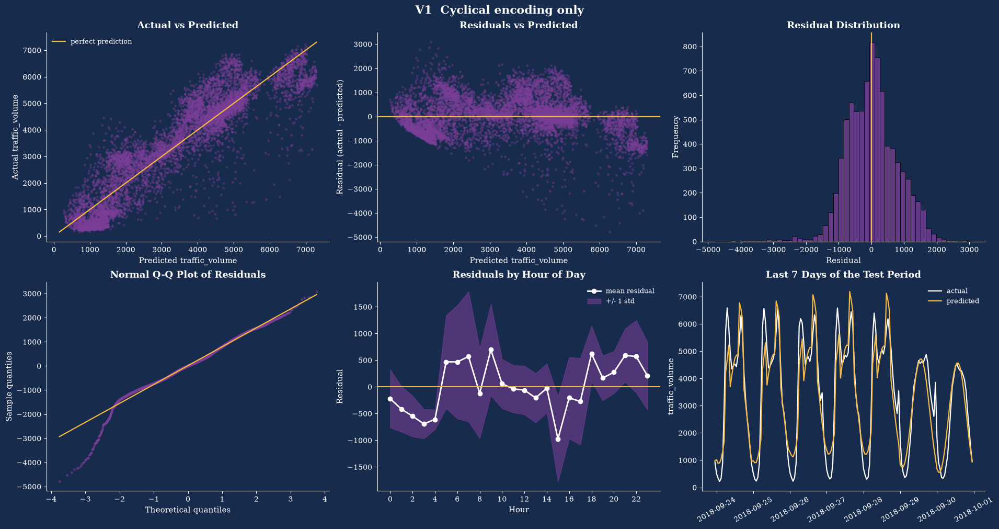

In [65]:
diagnostics(res_v1)

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">V2 — Log-Transformed Target</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Transformation: fit on <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">log1p(traffic_volume)</code> and back-transform with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">expm1</code>. All metrics below are computed back on the <b>original vehicles/hour scale</b>, so they are directly comparable with Model A. A log target turns additive effects into multiplicative ones (&ldquo;rain reduces traffic by x&nbsp;%&rdquo;) and tames the growing spread, but it can hurt when the main error comes from near-zero hours.</p></div>

In [66]:
res_v2 = run_model('V2  Log-transformed target', df, NUM_COLS, CAT_COLS, log_target=True,
                   note='fit on log1p(traffic_volume), metrics on the original scale')
metrics_table([res_a, res_v2])

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V2 Log-transformed target,25,32460,0.631,0.620,0.619,1207.313,1213.726,832.054


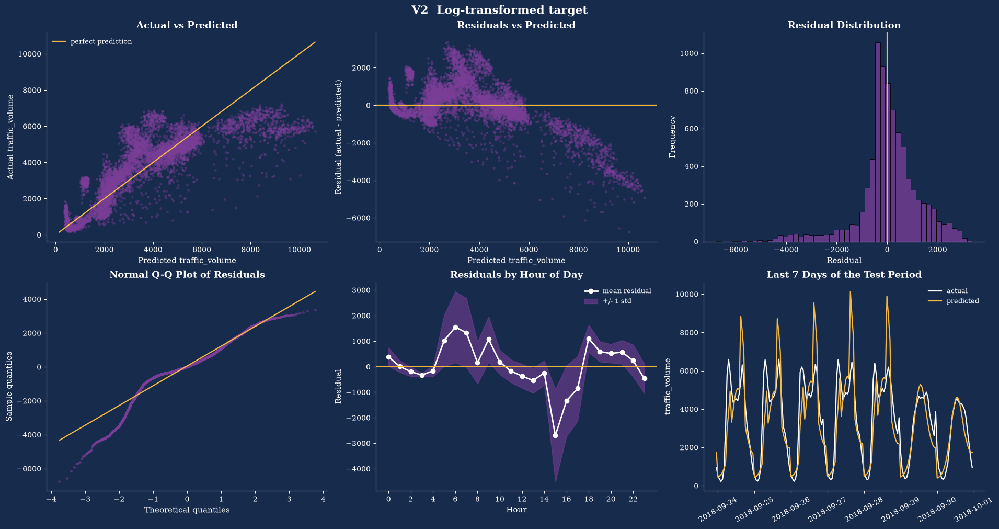

In [67]:
diagnostics(res_v2)

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">V3 — Train Without the Flagged Low-Volume Hours</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Condition: rows with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_low_volume == 1</code> (fewer than 100 vehicles/h in 9 clusters: sensor outage or closure, cause unknown, see 4.2.8) are <b>removed from the training rows only</b>. The flag is used as a row filter, <b>never as an input feature</b>, and Rows with `qa_low_volume == 1` are removed from the training data only; the flag is used as a row filter, never as an input feature. The test rows remain unchanged by this filtering step. However, test-set metrics are also used later to compare multiple models, so the test period should not be described as completely untouched by the overall evaluation process., so the score is still honest and comparable.</p></div>

In [68]:
res_v3 = run_model('V3  Train without low-volume hours', df, NUM_COLS, CAT_COLS,
                   train_filter=(df.qa_low_volume == 0),
                   note='qa_low_volume used only to drop training rows')
print('training rows removed:', len(train) - res_v3['n_train'])
metrics_table([res_a, res_v3])

training rows removed: 46


,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V3 Train without low-volume hours,25,32414,0.860,0.857,0.857,743.740,744.576,558.860


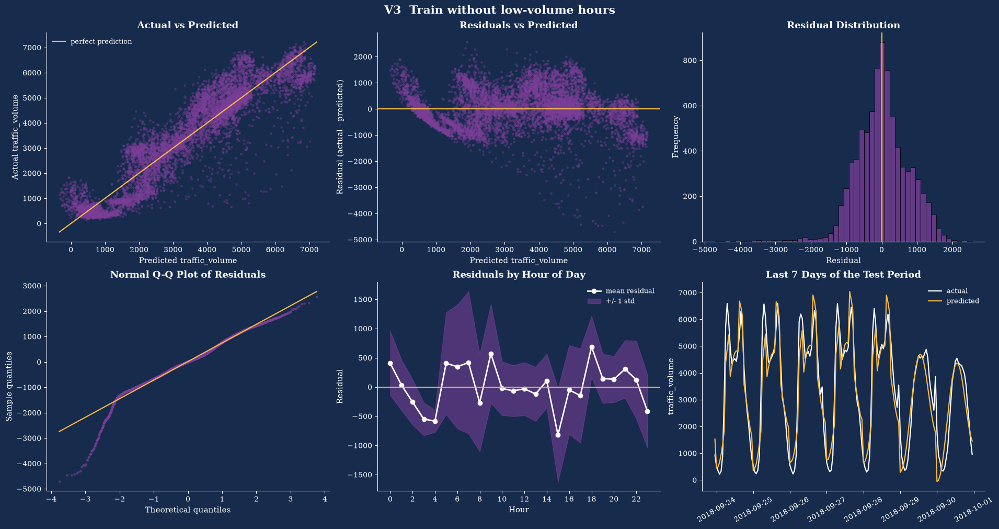

In [69]:
diagnostics(res_v3)

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">V4 — Weekday / Weekend x Hour Harmonics (Interactions)</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Transformation: add the <b>second daily harmonic</b> (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour_sin2</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour_cos2</code>), which lets the fitted curve have two peaks per day, and multiply the first and second harmonics by <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_weekend</code> so weekends get their own daily shape. This keeps the model linear in its coefficients while fixing the biggest structural error.</p></div>

In [70]:
df_v4 = df.copy()
df_v4['hour_sin2'] = np.sin(4 * np.pi * df_v4.hour / 24)
df_v4['hour_cos2'] = np.cos(4 * np.pi * df_v4.hour / 24)
V4_NEW = ['hour_sin2', 'hour_cos2']
for base in ['hour_sin', 'hour_cos', 'hour_sin2', 'hour_cos2']:
    df_v4[base + '_x_weekend'] = df_v4[base] * df_v4.is_weekend
    V4_NEW.append(base + '_x_weekend')

res_v4 = run_model('V4  Hour harmonics x weekend', df_v4, NUM_COLS + V4_NEW, CAT_COLS,
                   note='2nd harmonic + weekend interactions')
metrics_table([res_a, res_v4])

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V4 Hour harmonics x weekend,31,32460,0.907,0.906,0.906,607.562,603.882,425.975


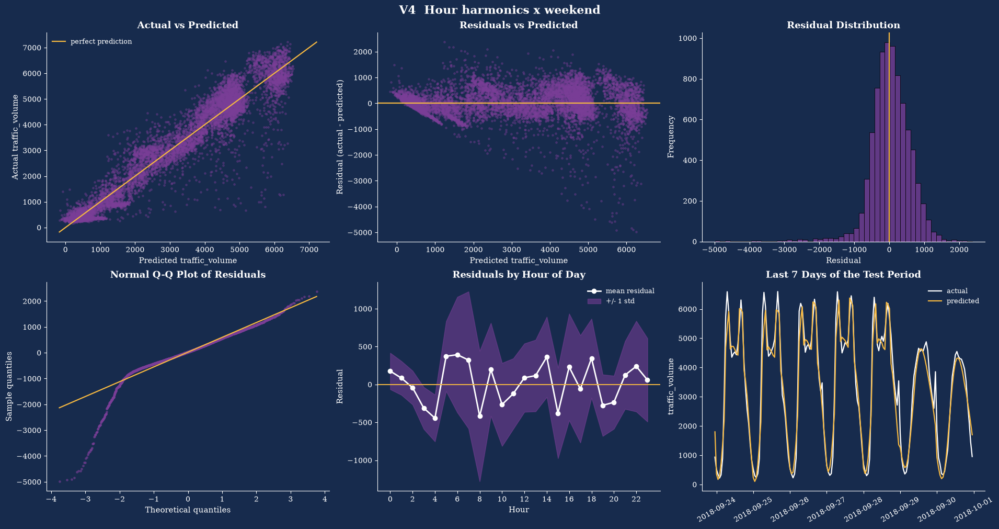

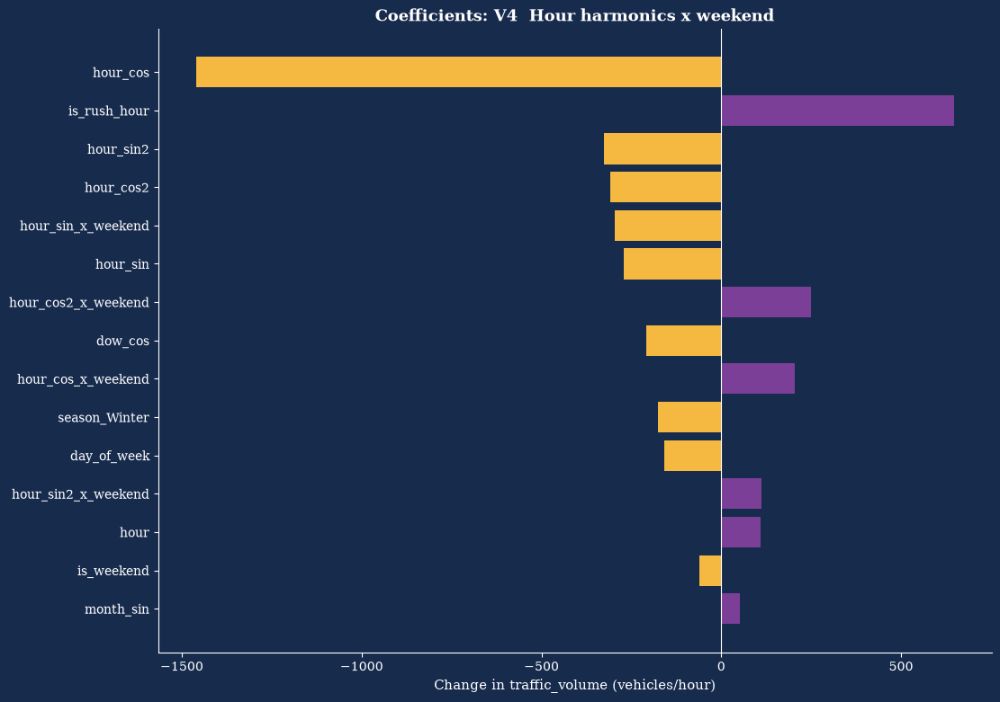

In [71]:
diagnostics(res_v4)
plot_coefficients(res_v4, top=15)

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.8 — Comparison of All Models</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The table and chart list every model currently stored in <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">RESULTS</code>. Lower RMSE / MAE and higher R&sup2; are better; compare the <b>test</b> columns, and look at the gap between train and test RMSE as a sign of drift over time.</p></div>

In [72]:
cmp = metrics_table(list(RESULTS.values()))
cmp

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V1 Cyclical encoding only,22,32460,0.840,0.838,0.838,794.848,792.542,605.463
V2 Log-transformed target,25,32460,0.631,0.620,0.619,1207.313,1213.726,832.054
V3 Train without low-volume hours,25,32414,0.860,0.857,0.857,743.740,744.576,558.860
V4 Hour harmonics x weekend,31,32460,0.907,0.906,0.906,607.562,603.882,425.975


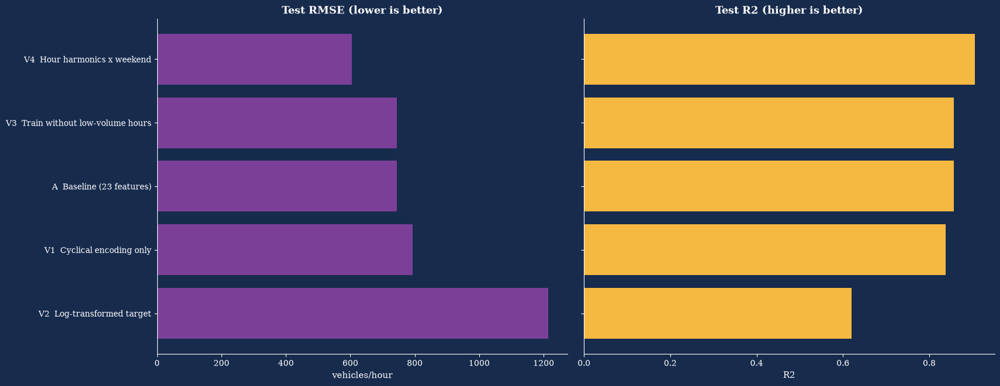

In [73]:
cmp_plot = cmp.sort_values('test RMSE', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(17, 0.7 * len(cmp_plot) + 3), facecolor=THEME_BG, constrained_layout=True)
axes[0].barh(cmp_plot.index, cmp_plot['test RMSE'], color=THEME_PURPLE)
style_axes(axes[0], 'Test RMSE (lower is better)', 'vehicles/hour')
axes[1].barh(cmp_plot.index, cmp_plot['test R2'], color=THEME_ACCENT)
style_axes(axes[1], 'Test R2 (higher is better)', 'R2')
axes[1].set_yticklabels([])
plt.show()

<br>

<a id="6"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">Weather Groups &mdash; Does Removing the Weather Labels Matter?</h2></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">6.1 — Question and Design</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The team decided in 4.1 to exclude <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_main</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code> from the features. This section measures what that decision costs. The 37 descriptions are too many and too rare to use directly (some appear fewer than five times), so they are first merged into <b>groups with a similar effect on driving conditions</b>:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Reduced_Visibility</b>: mist, fog, haze, smoke.</li><li style="margin-bottom:4px;"><b>Severe_Storm</b>: thunderstorms (including proximity thunderstorms) and squalls, i.e. strong wind and lightning.</li><li style="margin-bottom:4px;"><b>Light_Rain_Drizzle</b>, <b>Heavy_Rain</b>, <b>Snow_Ice</b>, and <b>Clear_Cloudy</b> (no driving impact, used as the reference level).</li></ul><p style="margin:0 0 8px 0;">Three models are then compared with the <b>same split and the same pipeline</b> as section 5:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>W-A</b>: current baseline, numeric weather only (no groups).</li><li style="margin-bottom:4px;"><b>W-B</b>: W-A + the weather group (one-hot).</li><li style="margin-bottom:4px;"><b>W-C</b>: no weather information at all (context: how much does weather matter in total?).</li></ul><p style="margin:0 0 8px 0;">The difference between W-B and W-A is the answer to &ldquo;how much did removing the labels cost?&rdquo;.</p></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">6.2 — Grouping Definition</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The dictionary below is the <b>only place to edit</b> if you disagree with a group: move a description to another list and re-run from here. A check stops the notebook if any description in the raw data is not mapped.</p></div>

In [74]:
WEATHER_GROUPS = {
    'Clear_Cloudy': ['sky is clear', 'few clouds', 'scattered clouds', 'broken clouds', 'overcast clouds'],
    'Reduced_Visibility': ['mist', 'fog', 'haze', 'smoke'],
    'Light_Rain_Drizzle': ['drizzle', 'light intensity drizzle', 'heavy intensity drizzle', 'shower drizzle',
                           'light rain', 'light intensity shower rain', 'proximity shower rain'],
    'Heavy_Rain': ['moderate rain', 'heavy intensity rain', 'very heavy rain'],
    'Snow_Ice': ['light snow', 'snow', 'heavy snow', 'shower snow', 'light shower snow',
                 'sleet', 'light rain and snow', 'freezing rain'],
    'Severe_Storm': ['thunderstorm', 'proximity thunderstorm', 'thunderstorm with light rain', 'thunderstorm with rain',
                     'thunderstorm with heavy rain', 'thunderstorm with light drizzle', 'thunderstorm with drizzle',
                     'proximity thunderstorm with rain', 'proximity thunderstorm with drizzle', 'squalls'],
}
# assumed driving-impact order, only used when WEATHER_AGG = 'worst' (see 6.3)
SEVERITY_RANK = {'Clear_Cloudy': 0, 'Reduced_Visibility': 1, 'Light_Rain_Drizzle': 2,
                 'Heavy_Rain': 3, 'Snow_Ice': 4, 'Severe_Storm': 5}
WEATHER_GROUP_MAP = {d: g for g, ds in WEATHER_GROUPS.items() for d in ds}

# same text normalisation as 4.3.2 (strip, lower-case) and the same exact-duplicate removal as the EDA section
raw_w = pd.read_csv("Metro_Interstate_Traffic_Volume.csv", parse_dates=['date_time']).drop_duplicates()
raw_w['weather_main'] = raw_w['weather_main'].str.strip()
raw_w['weather_description'] = raw_w['weather_description'].str.strip().str.lower()

unmapped = sorted(set(raw_w.weather_description) - set(WEATHER_GROUP_MAP))
assert not unmapped, f'add these descriptions to WEATHER_GROUPS: {unmapped}'
print('all', raw_w.weather_description.nunique(), 'descriptions are mapped to', len(WEATHER_GROUPS), 'groups')

raw_w['weather_group'] = raw_w.weather_description.map(WEATHER_GROUP_MAP)
group_overview = (raw_w.groupby('weather_group')
                     .agg(descriptions=('weather_description', 'nunique'), reports=('weather_description', 'size'))
                     .join(pd.Series({g: ', '.join(ds) for g, ds in WEATHER_GROUPS.items()}, name='members'))
                     .loc[list(WEATHER_GROUPS)])
group_overview

all 37 descriptions are mapped to 6 groups


,descriptions,reports,members
weather_group,,,
Clear_Cloudy,5,28542,"sky is clear, few clouds, scattered clouds, br..."
Reduced_Visibility,4,8241,"mist, fog, haze, smoke"
Light_Rain_Drizzle,7,5341,"drizzle, light intensity drizzle, heavy intens..."
Heavy_Rain,3,2149,"moderate rain, heavy intensity rain, very heav..."
Snow_Ice,8,2877,"light snow, snow, heavy snow, shower snow, lig..."
Severe_Storm,10,1037,"thunderstorm, proximity thunderstorm, thunders..."


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">6.3 — One Weather Group per Hour</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Several hours have more than one weather report (5,430 timestamps, section 4.2.2). Two ways to pick the group of such an hour:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">mode</code></b> (default, consistent with 4.3.4): take the most frequent <i>(main, description)</i> pair, ties broken alphabetically, then map it to its group.</li><li style="margin-bottom:4px;"><b><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">worst</code></b>: take the most severe group among all reports of the hour (order in <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">SEVERITY_RANK</code>).</li></ul><p style="margin:0 0 8px 0;">Both are computed and compared below so you can see how much the choice matters. Switch with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">WEATHER_AGG</code>.</p></div>

In [75]:
WEATHER_AGG = 'mode'      # 'mode' (consistent with 4.3.4) or 'worst'

# ---- option 1: mode on the (main, description) pair, deterministic tie-break ----
pair_mode = (raw_w.groupby(['date_time', 'weather_main', 'weather_description']).size().rename('n').reset_index()
                .sort_values(['date_time', 'n', 'weather_main', 'weather_description'],
                             ascending=[True, False, True, True])
                .drop_duplicates('date_time').set_index('date_time'))
group_mode = pair_mode.weather_description.map(WEATHER_GROUP_MAP)

# ---- option 2: most severe group among the hour's reports ----
tmp = raw_w.assign(rank=raw_w.weather_group.map(SEVERITY_RANK)).sort_values(['date_time', 'rank'])
group_worst = tmp.drop_duplicates('date_time', keep='last').set_index('date_time').weather_group

agree = (group_mode == group_worst.reindex(group_mode.index)).mean()
multi = raw_w.groupby('date_time').weather_group.nunique()
print(f'hours with reports from more than one group: {(multi > 1).sum():,}')
print(f'hours where mode and worst give the same group: {agree:.1%}')

hourly_group = group_mode if WEATHER_AGG == 'mode' else group_worst
assert df.index.isin(hourly_group.index).all(), 'some hours of the clean file have no weather report'

order = list(WEATHER_GROUPS)
df['weather_group'] = pd.Categorical(hourly_group.reindex(df.index), categories=order)
assert df.weather_group.notna().all()
print('aggregation used:', WEATHER_AGG)
df.weather_group.value_counts().reindex(order).to_frame('hours')

hours with reports from more than one group: 4,069
hours where mode and worst give the same group: 91.2%
aggregation used: mode


,hours
weather_group,
Clear_Cloudy,28491
Reduced_Visibility,5763
Light_Rain_Drizzle,3948
Heavy_Rain,884
Snow_Ice,1250
Severe_Storm,239


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">6.3.1 — How Do the Groups Relate to Traffic?</h4></div>

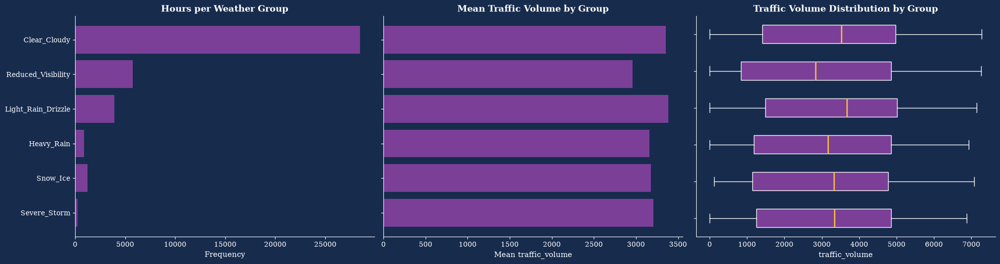

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2), facecolor=THEME_BG, constrained_layout=True)

counts = df.weather_group.value_counts().reindex(order)
axes[0].barh(counts.index[::-1], counts.values[::-1], color=THEME_PURPLE)
style_axes(axes[0], 'Hours per Weather Group', 'Frequency')

means = df.groupby('weather_group', observed=True)[TARGET].mean().reindex(order)
axes[1].barh(means.index[::-1], means.values[::-1], color=THEME_PURPLE)
style_axes(axes[1], 'Mean Traffic Volume by Group', 'Mean traffic_volume')
axes[1].set_yticklabels([])

data_box = [df.loc[df.weather_group == g, TARGET].values for g in order]
bp = axes[2].boxplot(data_box, vert=False, patch_artist=True,
                     medianprops=dict(color=THEME_ACCENT, lw=2), whiskerprops=dict(color='white'),
                     capprops=dict(color='white'), flierprops=dict(markerfacecolor='white', markersize=2, alpha=0.4, markeredgecolor='none'))
for patch in bp['boxes']:
    patch.set_facecolor(THEME_PURPLE)
    patch.set_edgecolor('white')
axes[2].invert_yaxis()
style_axes(axes[2], 'Traffic Volume Distribution by Group', 'traffic_volume')
axes[2].set_yticklabels([])
plt.show()

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><b>Caution when reading this chart:</b> the raw group means mix in the time-of-day effect (fog and mist are frequent at night and early morning, when traffic is low). Whether the groups carry information <b>beyond</b> the calendar features is exactly what the models in 6.4 test.</p></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">6.4 — Models With and Without the Weather Groups</h3></div>

In [77]:
WEATHER_NUM = ['temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'is_freezing', 'is_raining',
               'is_snowing', 'precipitation_flag', 'rain_1h_log1p', 'snow_1h_log1p']
assert all(c in NUM_COLS for c in WEATHER_NUM)

res_w_a = run_model('W-A  numeric weather only (baseline)', df, NUM_COLS, CAT_COLS,
                    note='no weather labels')
res_w_b = run_model('W-B  numeric weather + weather groups', df, NUM_COLS, CAT_COLS + ['weather_group'],
                    note='adds one-hot weather_group (reference: Clear_Cloudy)')
res_w_c = run_model('W-C  no weather at all', df, [c for c in NUM_COLS if c not in WEATHER_NUM], CAT_COLS,
                    note='drops every weather input')
metrics_table([res_w_a, res_w_b, res_w_c])

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
W-A numeric weather only (baseline),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
W-B numeric weather + weather groups,30,32460,0.858,0.857,0.857,749.893,743.962,558.665
W-C no weather at all,15,32460,0.857,0.856,0.856,751.981,746.932,560.443


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">6.4.1 — Cost of Removing the Groups</h4></div>

In [78]:
def nested_f_test(small, big):
    # Partial F-test on the training data: do the extra columns of `big` explain a significant extra part of the variance?
    n = small['n_train']
    rss = lambda r: float((r['resid_fit'] ** 2).sum())
    k1, k2 = small['n_features'], big['n_features']
    F = ((rss(small) - rss(big)) / (k2 - k1)) / (rss(big) / (n - k2 - 1))
    return F, stats.f.sf(F, k2 - k1, n - k2 - 1), k2 - k1


delta = pd.DataFrame({
    'W-A (without groups)': pd.Series(res_w_a['test']),
    'W-B (with groups)': pd.Series(res_w_b['test']),
})
delta['change (B - A)'] = delta['W-B (with groups)'] - delta['W-A (without groups)']
delta['relative change %'] = 100 * delta['change (B - A)'] / delta['W-A (without groups)']
print('TEST-set effect of adding the weather groups')
display(delta.round(4))

F, pval, extra = nested_f_test(res_w_a, res_w_b)
print(f'\nPartial F-test on the training data: {extra} extra columns, F = {F:.2f}, p-value = {pval:.3g}')
print('(autocorrelated residuals make this p-value optimistic: use it as a rough guide, the test-set change above is the honest number)')

TEST-set effect of adding the weather groups


,W-A (without groups),W-B (with groups),change (B - A),relative change %
R2,0.8570,0.8574,0.0003,0.0407
Adj_R2,0.8566,0.8569,0.0003,0.0305
MAE,559.2483,558.6647,-0.5836,-0.1044
RMSE,744.8724,743.9624,-0.9099,-0.1222



Partial F-test on the training data: 5 extra columns, F = 1.22, p-value = 0.296
(autocorrelated residuals make this p-value optimistic: use it as a rough guide, the test-set change above is the honest number)


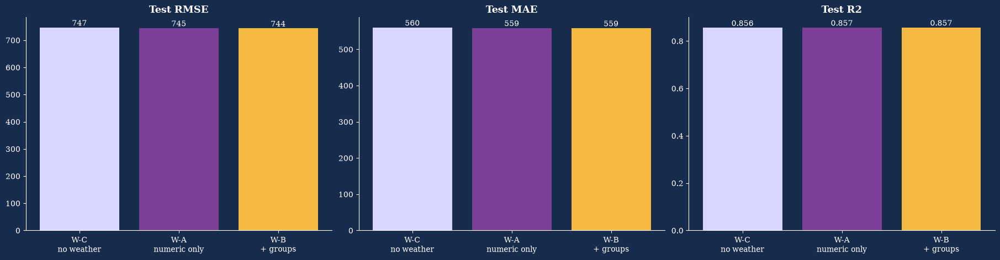

In [79]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), facecolor=THEME_BG, constrained_layout=True)
names = ['W-C\nno weather', 'W-A\nnumeric only', 'W-B\n+ groups']
rs = [res_w_c, res_w_a, res_w_b]
for ax, key, title in zip(axes, ['RMSE', 'MAE', 'R2'], ['Test RMSE', 'Test MAE', 'Test R2']):
    vals = [r['test'][key] for r in rs]
    ax.bar(names, vals, color=[THEME_LAVENDER, THEME_PURPLE, THEME_ACCENT])
    for i, v in enumerate(vals):
        ax.text(i, v, f'{v:,.3f}' if key == 'R2' else f'{v:,.0f}', ha='center', va='bottom', color='white', fontfamily='serif', fontsize=10)
    style_axes(ax, title)
plt.show()

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">6.4.2 — Effect Size of Each Group (Coefficients With Standard Errors)</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">One-hot columns are <b>not</b> standardized, so each coefficient reads directly as <b>vehicles per hour compared with Clear_Cloudy</b>, holding all other inputs fixed. Bars are &plusmn;1.96 standard errors; because consecutive hours are correlated these intervals are too narrow, so only trust clear separations from zero.</p></div>

,coef,se,t
Heavy_Rain,-21.09,32.31,-0.65
Light_Rain_Drizzle,4.15,16.76,0.25
Reduced_Visibility,-26.50,13.28,-2.00
Severe_Storm,-8.39,59.29,-0.14
Snow_Ice,24.57,26.96,0.91


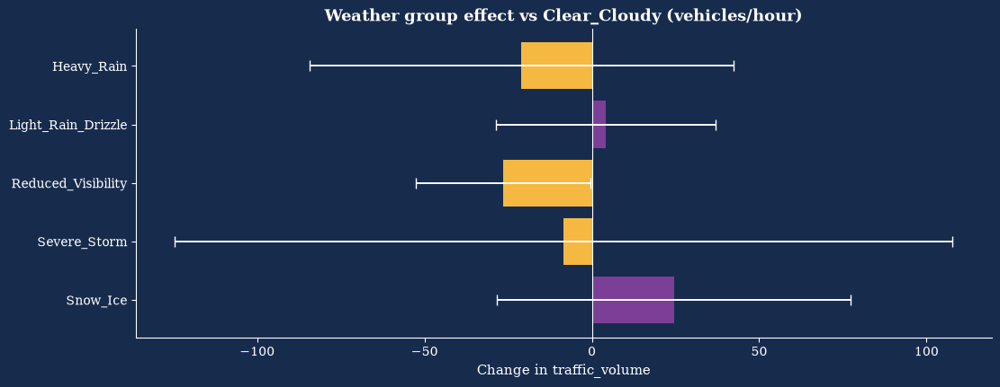

In [80]:
def coef_table(res):
    X = res['X_tr']
    A = np.column_stack([np.ones(len(X)), X.values])
    lr = res['pipe'].named_steps['lr']
    b = np.r_[lr.intercept_, lr.coef_]
    e = res['resid_fit'].values
    sigma2 = (e ** 2).sum() / (len(A) - A.shape[1])
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(A.T @ A)))
    return pd.DataFrame({'coef': b, 'se': se, 't': b / se}, index=['intercept'] + list(X.columns))


ct = coef_table(res_w_b)
grp = ct[ct.index.str.startswith('weather_group_')].copy()
grp.index = grp.index.str.replace('weather_group_', '', regex=False)
display(grp.round(2))

fig, ax = plt.subplots(figsize=(11, 4.2), facecolor=THEME_BG, constrained_layout=True)
ypos = np.arange(len(grp))
ax.barh(ypos, grp.coef, xerr=1.96 * grp.se, color=[THEME_PURPLE if v >= 0 else THEME_ACCENT for v in grp.coef],
        error_kw=dict(ecolor='white', lw=1.4, capsize=4))
ax.set_yticks(ypos)
ax.set_yticklabels(grp.index)
ax.axvline(0, color='white', lw=0.8)
ax.invert_yaxis()
style_axes(ax, 'Weather group effect vs Clear_Cloudy (vehicles/hour)', 'Change in traffic_volume')
plt.show()

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">6.4.3 — Where Do the Groups Help? (Test Residuals by Group)</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">If a group is systematically mis-predicted by W-A, its mean residual (<b>bias</b>) is far from zero; W-B should pull it back towards zero. Groups with few test hours give noisy numbers: read the <i>hours</i> column.</p></div>

,hours (test),W-A bias,W-A RMSE,W-B bias,W-B RMSE
weather_group,,,,,
Clear_Cloudy,5392,48.5,714.7,46.7,714.6
Reduced_Visibility,1386,-114.5,885.2,-91.6,882.0
Light_Rain_Drizzle,745,-3.8,707.3,-11.2,707.2
Heavy_Rain,162,90.4,665.7,104.3,665.9
Snow_Ice,354,149.9,696.6,122.9,691.1
Severe_Storm,76,-1.4,780.8,4.3,780.9


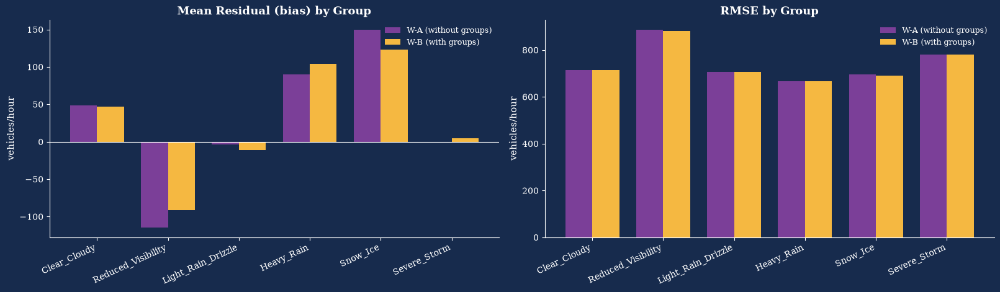

In [81]:
te_group = df['weather_group'].iloc[split_idx:]
rows = {}
for tag, r in [('W-A', res_w_a), ('W-B', res_w_b)]:
    resid = r['y_te'] - r['yhat_te']
    g = resid.groupby(te_group, observed=True)
    rows[tag + ' bias'] = g.mean()
    rows[tag + ' RMSE'] = g.apply(lambda s: float(np.sqrt((s ** 2).mean())))
by_group = pd.DataFrame(rows).reindex(order)
by_group.insert(0, 'hours (test)', te_group.value_counts().reindex(order).fillna(0).astype(int))
display(by_group.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), facecolor=THEME_BG, constrained_layout=True)
x = np.arange(len(order)); w = 0.38
for ax, suffix, title in zip(axes, ['bias', 'RMSE'], ['Mean Residual (bias) by Group', 'RMSE by Group']):
    ax.bar(x - w / 2, by_group['W-A ' + suffix], w, color=THEME_PURPLE, label='W-A (without groups)')
    ax.bar(x + w / 2, by_group['W-B ' + suffix], w, color=THEME_ACCENT, label='W-B (with groups)')
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=25, ha='right')
    if suffix == 'bias':
        ax.axhline(0, color='white', lw=0.8)
    style_axes(ax, title, None, 'vehicles/hour')
    style_legend(ax)
plt.show()

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">6.4.4 — Optional: Compare the Two Hourly-Label Rules</h4></div>

In [82]:
alt_series = group_worst if WEATHER_AGG == 'mode' else group_mode
alt_name = 'worst' if WEATHER_AGG == 'mode' else 'mode'
df_alt = df.copy()
df_alt['weather_group'] = pd.Categorical(alt_series.reindex(df_alt.index), categories=order)
res_w_b_alt = run_model(f'W-B  groups via "{alt_name}" rule', df_alt, NUM_COLS, CAT_COLS + ['weather_group'])
metrics_table([res_w_a, res_w_b, res_w_b_alt])

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
W-A numeric weather only (baseline),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
W-B numeric weather + weather groups,30,32460,0.858,0.857,0.857,749.893,743.962,558.665
"W-B groups via ""worst"" rule",30,32460,0.858,0.858,0.858,749.314,741.678,557.648


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">6.5 — Overall Comparison</h3></div>

In [83]:
metrics_table(list(RESULTS.values()))

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V1 Cyclical encoding only,22,32460,0.840,0.838,0.838,794.848,792.542,605.463
V2 Log-transformed target,25,32460,0.631,0.620,0.619,1207.313,1213.726,832.054
V3 Train without low-volume hours,25,32414,0.860,0.857,0.857,743.740,744.576,558.860
V4 Hour harmonics x weekend,31,32460,0.907,0.906,0.906,607.562,603.882,425.975
W-A numeric weather only (baseline),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
W-B numeric weather + weather groups,30,32460,0.858,0.857,0.857,749.893,743.962,558.665
W-C no weather at all,15,32460,0.857,0.856,0.856,751.981,746.932,560.443
"W-B groups via ""worst"" rule",30,32460,0.858,0.858,0.858,749.314,741.678,557.648


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><b>How to read the result:</b></p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;">If W-B&rsquo;s <b>test RMSE / R&sup2;</b> is practically the same as W-A&rsquo;s, the weather groups add little beyond the numeric weather and the calendar features, which supports the team decision to leave the labels out.</li><li style="margin-bottom:4px;">If W-B is clearly better, and the gain is concentrated in groups such as Reduced_Visibility or Severe_Storm (6.4.3), the labels carry information the numbers (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">snow_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">clouds_all</code>) do not, and the decision deserves a second look.</li><li style="margin-bottom:4px;">W-C shows how much weather matters in total. If W-C is close to W-A, weather is a minor driver of hourly traffic compared with hour and weekday, and no weather encoding will change the picture much.</li><li style="margin-bottom:4px;">A linear model cannot express weather <i>x</i> rush-hour interactions (fog matters more at 7&nbsp;am than at 3&nbsp;am). A small gain here does not rule out a larger one for a tree-based model.</li></ul></div>

<a id="7"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;">
  <h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">
    Random Forest — Model Implementation and Analysis
  </h2>
</div>


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <p style="margin:0 0 8px 0;"><b>Random Forest</b> builds many decision trees and averages their predictions. Each tree sees a different sample of the training data and considers a subset of features at each split. This helps capture non-linear patterns while reducing reliance on a single tree.</p>
  <p style="margin:0;">The models below use the same chronological train/test split and the same 23 features as the linear models. QA columns are excluded.</p>
</div>


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;">
  <h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">7.1 — Random Forest Pipeline and Baseline</h4>
</div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <p style="margin:0;">Numeric inputs pass through unchanged because tree models do not need feature scaling. <code>season</code> is one-hot encoded. The preprocessing pipeline is fitted on training data only.</p>
</div>


In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RF_FEATURES = FEATURES.copy()


def make_rf_pipeline(params):
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", "passthrough", NUM_COLS),
            (
                "cat",
                OneHotEncoder(
                    drop="first",
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
                CAT_COLS,
            ),
        ],
        verbose_feature_names_out=False,
    )

    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1,
    )

    return Pipeline([
        ("prep", preprocessor),
        ("rf", model),
    ])


def rf_score(y, yhat):
    return {
        "R2": r2_score(y, yhat),
        "MAE": mean_absolute_error(y, yhat),
        "RMSE": float(np.sqrt(mean_squared_error(y, yhat))),
    }


def rf_comparison_table(results):
    rows = []
    for result in results:
        rows.append({
            "model": result["name"],
            "n_features": result["n_features"],
            "n_train": result["n_train"],
            "train R2": result["train"]["R2"],
            "test R2": result["test"]["R2"],
            "train RMSE": result["train"]["RMSE"],
            "test RMSE": result["test"]["RMSE"],
            "test MAE": result["test"]["MAE"],
        })
    return pd.DataFrame(rows).set_index("model").round(3)


def evaluate_rf(name, params):
    pipe = make_rf_pipeline(params)

    pipe.fit(train[RF_FEATURES], train[TARGET])

    pred_train = pipe.predict(train[RF_FEATURES])
    pred_test = pipe.predict(test[RF_FEATURES])

    n_features = len(pipe.named_steps["prep"].get_feature_names_out())

    result = {
        "name": name,
        "n_train": len(train),
        "n_features": n_features,
        "train": rf_score(train[TARGET], pred_train),
        "test": rf_score(test[TARGET], pred_test),
        "pipe": pipe,
        "idx_te": test.index,
        "y_te": test[TARGET],
        "yhat_te": pd.Series(pred_test, index=test.index),
    }

    return result


RF_BASE_PARAMS = {
    "n_estimators": 200,
    "max_depth": None,
    "min_samples_leaf": 1,
    "max_features": 1.0,
}

res_rf_base = evaluate_rf("RF  Baseline", RF_BASE_PARAMS)

print(
    "RF baseline | test R²: %.3f | RMSE: %.1f | MAE: %.1f"
    % (res_rf_base["test"]["R2"], res_rf_base["test"]["RMSE"], res_rf_base["test"]["MAE"])
)


RF baseline | test R²: 0.937 | RMSE: 494.0 | MAE: 286.6


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;">
  <h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">7.2 — Important Parameters</h4>
</div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <ul style="margin:4px 0 8px 22px; padding:0;">
    <li><code>n_estimators</code>: number of trees in the forest.</li>
    <li><code>max_depth</code>: maximum depth of each tree.</li>
    <li><code>min_samples_leaf</code>: minimum number of training rows in a leaf; larger values regularize the trees.</li>
    <li><code>max_features</code>: number or share of features considered at each split.</li>
  </ul>
  <p style="margin:0;">The configurations are compared with expanding-window validation on the training portion only. The test portion is reserved for the final comparison.</p>
</div>


In [85]:
RF_CONFIGS = {
    "RF-CV  Baseline": {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0,
    },
    "RF-CV  More Trees": {
        "n_estimators": 400,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0,
    },
    "RF-CV  Limited Depth": {
        "n_estimators": 200,
        "max_depth": 25,
        "min_samples_leaf": 1,
        "max_features": 1.0,
    },
    "RF-CV  Larger Leaves": {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 5,
        "max_features": 1.0,
    },
    "RF-CV  Fewer Features": {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 0.7,
    },
}

# Half-open calendar intervals; all folds stay strictly inside the training period.
RF_CV_WINDOWS = [
    ("2015-04-01", "2015-10-01"),
    ("2015-10-01", "2016-04-01"),
    ("2016-04-01", "2016-10-01"),
    ("2016-10-01", "2017-04-01"),
    ("2017-04-01", "2017-10-27"),
]

rf_cv_rows = []

for config_name, params in RF_CONFIGS.items():
    for fold, (valid_start, valid_end) in enumerate(RF_CV_WINDOWS, start=1):
        valid_start = pd.Timestamp(valid_start)
        valid_end = pd.Timestamp(valid_end)

        fit_mask = train.index < valid_start
        valid_mask = (train.index >= valid_start) & (train.index < valid_end)
        fold_train = train.loc[fit_mask]
        fold_valid = train.loc[valid_mask]

        assert len(fold_train) > 0 and len(fold_valid) > 0, f"empty data in fold {fold}"
        assert fold_train.index.max() < fold_valid.index.min(), f"time order broken in fold {fold}"

        pipe = make_rf_pipeline(params)
        pipe.fit(fold_train[RF_FEATURES], fold_train[TARGET])

        pred_valid = pipe.predict(fold_valid[RF_FEATURES])
        n_features = len(pipe.named_steps["prep"].get_feature_names_out())
        fold_scores = rf_score(fold_valid[TARGET], pred_valid)

        rf_cv_rows.append({
            "configuration": config_name,
            "fold": fold,
            "validation_start": valid_start,
            "validation_end": valid_end,
            "train_rows": len(fold_train),
            "validation_rows": len(fold_valid),
            "R2": fold_scores["R2"],
            "MAE": fold_scores["MAE"],
            "RMSE": fold_scores["RMSE"],
        })

rf_cv_results = pd.DataFrame(rf_cv_rows)

rf_cv_summary = (
    rf_cv_results
    .groupby("configuration")
    .agg(
        mean_R2=("R2", "mean"),
        mean_MAE=("MAE", "mean"),
        mean_RMSE=("RMSE", "mean"),
        std_RMSE=("RMSE", "std"),
    )
    .sort_values("mean_RMSE")
    .round(3)
)

display(rf_cv_summary)

best_rf_config = rf_cv_summary.index[0]
best_rf_params = RF_CONFIGS[best_rf_config]

print("Selected configuration:", best_rf_config)
print("Selected parameters:", best_rf_params)
print("Validation windows:", RF_CV_WINDOWS)


,mean_R2,mean_MAE,mean_RMSE,std_RMSE
configuration,,,,
RF-CV Larger Leaves,0.935,300.286,499.895,54.700
RF-CV Fewer Features,0.931,313.035,513.926,55.925
RF-CV More Trees,0.929,318.566,522.809,59.532
RF-CV Baseline,0.929,319.167,523.717,59.289
RF-CV Limited Depth,0.929,319.346,524.111,60.659


Selected configuration: RF-CV  Larger Leaves
Selected parameters: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 1.0}
Validation windows: [('2015-04-01', '2015-10-01'), ('2015-10-01', '2016-04-01'), ('2016-04-01', '2016-10-01'), ('2016-10-01', '2017-04-01'), ('2017-04-01', '2017-10-27')]


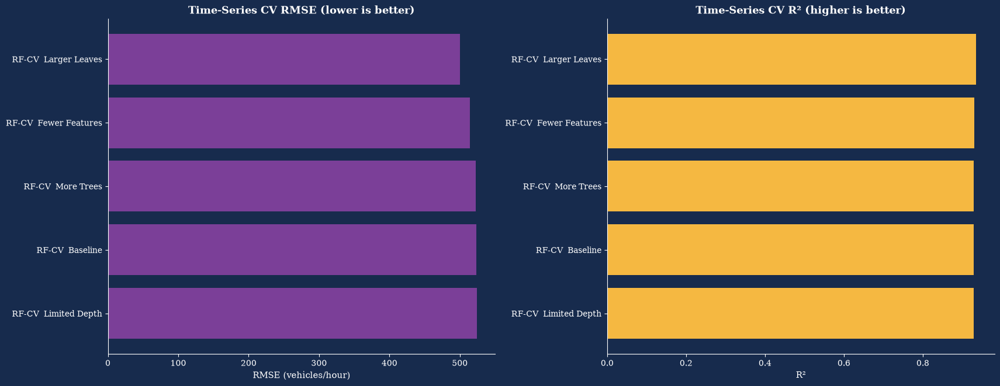

Selected configuration: RF-CV  Larger Leaves
Selected parameters: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 1.0}


In [86]:
rf_cv_plot = rf_cv_summary.sort_values("mean_RMSE", ascending=False)

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 0.7 * len(rf_cv_plot) + 3),
    facecolor=THEME_BG,
    constrained_layout=True,
)

axes[0].barh(
    rf_cv_plot.index,
    rf_cv_plot["mean_RMSE"],
    color=THEME_PURPLE,
)
style_axes(
    axes[0],
    title="Time-Series CV RMSE (lower is better)",
    xlabel="RMSE (vehicles/hour)",
)

axes[1].barh(
    rf_cv_plot.index,
    rf_cv_plot["mean_R2"],
    color=THEME_ACCENT,
)
style_axes(
    axes[1],
    title="Time-Series CV R² (higher is better)",
    xlabel="R²",
)

plt.show()

best_rf_config_name = rf_cv_summary.index[0]
best_rf_params = RF_CONFIGS[best_rf_config_name]

print("Selected configuration:", best_rf_config_name)
print("Selected parameters:", best_rf_params)

res_rf_tuned = evaluate_rf(
    "RF  Tuned",
    best_rf_params,
)


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;">
  <h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">7.3 — Comparison with the Linear Baselines</h4>
</div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <p style="margin:0;">The baseline and tuned Random Forest use the same chronological test period as Linear Regression A and V4. Lower test RMSE and MAE are better; higher test R² is better.</p>
</div>


In [87]:
rf_comparison = rf_comparison_table([
    res_a,
    res_v4,
    res_rf_base,
    res_rf_tuned,
])

display(rf_comparison)


,n_features,n_train,train R2,test R2,train RMSE,test RMSE,test MAE
model,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,749.963,744.872,559.248
V4 Hour harmonics x weekend,31,32460,0.907,0.906,607.562,603.882,425.975
RF Baseline,25,32460,0.993,0.937,169.070,493.966,286.556
RF Tuned,25,32460,0.969,0.942,347.563,476.296,270.062


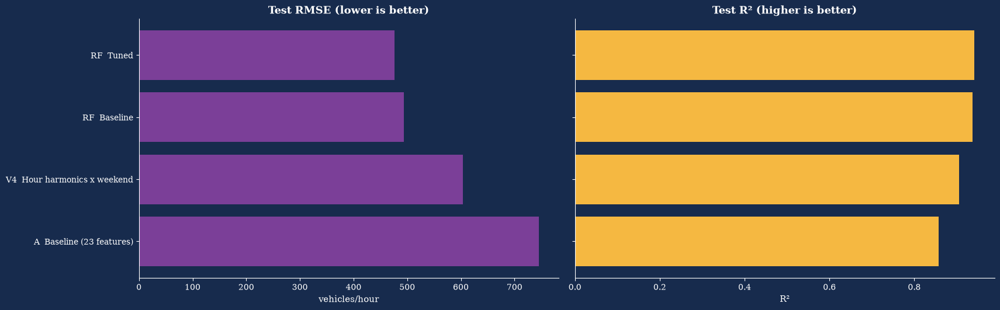

In [88]:
rf_comparison_plot = rf_comparison.sort_values(
    "test RMSE",
    ascending=False,
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 5.2),
    facecolor=THEME_BG,
    constrained_layout=True,
)

axes[0].barh(
    rf_comparison_plot.index,
    rf_comparison_plot["test RMSE"],
    color=THEME_PURPLE,
)
style_axes(
    axes[0],
    title="Test RMSE (lower is better)",
    xlabel="vehicles/hour",
)

axes[1].barh(
    rf_comparison_plot.index,
    rf_comparison_plot["test R2"],
    color=THEME_ACCENT,
)
style_axes(
    axes[1],
    title="Test R² (higher is better)",
    xlabel="R²",
)
axes[1].set_yticklabels([])

plt.show()


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;">
  <h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">7.4 — Feature Importance</h4>
</div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <p style="margin:0;">Permutation importance measures how much the test RMSE worsens when one input column is shuffled. Related calendar and precipitation columns overlap, so their individual scores can be misleading. The grouped analysis shuffles each feature family together while preserving relationships within that family. Importance measures predictive reliance, not causation.</p>
</div>


In [90]:
rf_importance_result = permutation_importance(
    res_rf_tuned["pipe"],
    test[RF_FEATURES],
    test[TARGET],
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

rf_importance = (
    pd.DataFrame({
        "feature": RF_FEATURES,
        "importance_mean": rf_importance_result.importances_mean,
        "importance_std": rf_importance_result.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

display(rf_importance.head(15).round(3))


,feature,importance_mean,importance_std
0,hour_cos,1513.810,10.309
1,hour,506.806,5.384
2,hour_sin,212.592,5.348
3,is_rush_hour,157.176,2.637
4,day_of_week,117.547,3.087
5,dow_sin,114.473,2.995
6,is_weekend,97.214,2.638
7,dow_cos,34.020,1.320
8,temp_c,29.195,3.159
9,month_cos,6.915,0.882


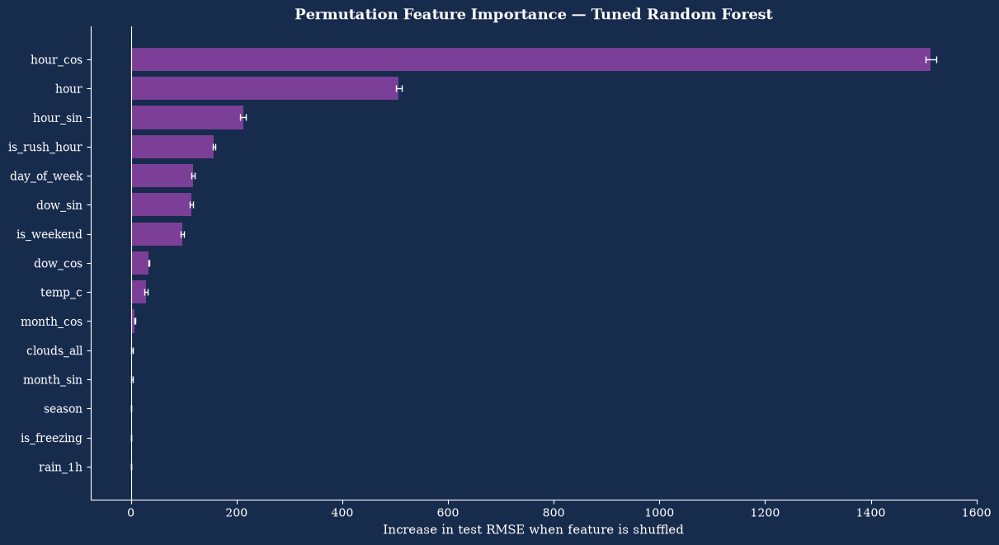

In [91]:
rf_importance_plot = (
    rf_importance
    .head(15)
    .sort_values("importance_mean")
)

fig, ax = plt.subplots(
    figsize=(12, 6.5),
    facecolor=THEME_BG,
    constrained_layout=True,
)

ax.barh(
    rf_importance_plot["feature"],
    rf_importance_plot["importance_mean"],
    xerr=rf_importance_plot["importance_std"],
    color=THEME_PURPLE,
    error_kw=dict(ecolor="white", capsize=3, lw=1),
)

ax.axvline(0, color="white", lw=0.8)
style_axes(
    ax,
    title="Permutation Feature Importance — Tuned Random Forest",
    xlabel="Increase in test RMSE when feature is shuffled",
)

plt.show()


,feature_group,features,importance_mean,importance_std
0,Hour and commute,"hour, hour_sin, hour_cos, is_rush_hour",2165.29,6.85
1,Weekday and weekend,"day_of_week, dow_sin, dow_cos, is_weekend",637.38,10.69
2,Temperature and freezing,"temp_c, is_freezing",30.62,3.57
3,Month and season,"month, month_sin, month_cos, season",26.28,3.11
4,Cloud cover,clouds_all,2.52,1.08
5,Precipitation,"rain_1h, snow_1h, is_raining, is_snowing, prec...",0.45,0.30
6,Long-term year,year,-0.00,0.00


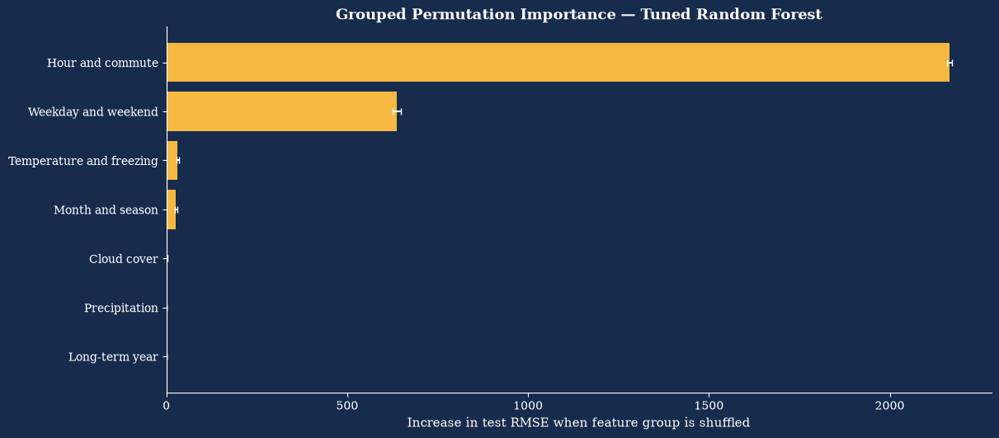

In [92]:
RF_FEATURE_GROUPS = {
    "Hour and commute": ["hour", "hour_sin", "hour_cos", "is_rush_hour"],
    "Weekday and weekend": ["day_of_week", "dow_sin", "dow_cos", "is_weekend"],
    "Month and season": ["month", "month_sin", "month_cos", "season"],
    "Long-term year": ["year"],
    "Temperature and freezing": ["temp_c", "is_freezing"],
    "Precipitation": [
        "rain_1h", "snow_1h", "is_raining", "is_snowing",
        "precipitation_flag", "rain_1h_log1p", "snow_1h_log1p",
    ],
    "Cloud cover": ["clouds_all"],
}

_grouped_columns = [column for columns in RF_FEATURE_GROUPS.values() for column in columns]
assert len(_grouped_columns) == len(set(_grouped_columns)), "a feature appears in more than one group"
assert set(_grouped_columns) == set(RF_FEATURES), "feature groups must cover every RF input exactly once"


def grouped_permutation_importance(model, X, y, feature_groups, n_repeats=10, random_state=42):
    rng = np.random.default_rng(random_state)
    baseline_rmse = np.sqrt(mean_squared_error(y, model.predict(X)))
    rows = []

    for group_name, requested_columns in feature_groups.items():
        columns = [c for c in requested_columns if c in X.columns]
        score_deltas = []

        for _ in range(n_repeats):
            row_order = rng.permutation(len(X))
            X_permuted = X.copy()
            for column in columns:
                X_permuted[column] = X.iloc[row_order][column].to_numpy()

            permuted_rmse = np.sqrt(mean_squared_error(y, model.predict(X_permuted)))
            score_deltas.append(permuted_rmse - baseline_rmse)

        rows.append({
            "feature_group": group_name,
            "features": ", ".join(columns),
            "importance_mean": np.mean(score_deltas),
            "importance_std": np.std(score_deltas, ddof=1),
        })

    return (
        pd.DataFrame(rows)
        .sort_values("importance_mean", ascending=False)
        .reset_index(drop=True)
    )


rf_group_importance = grouped_permutation_importance(
    res_rf_tuned["pipe"],
    test[RF_FEATURES],
    test[TARGET],
    RF_FEATURE_GROUPS,
    n_repeats=10,
    random_state=42,
)

display(rf_group_importance.round(2))

rf_group_plot = rf_group_importance.sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(12, 5.2), facecolor=THEME_BG, constrained_layout=True)
ax.barh(
    rf_group_plot["feature_group"],
    rf_group_plot["importance_mean"],
    xerr=rf_group_plot["importance_std"],
    color=THEME_ACCENT,
    error_kw={"ecolor": "white", "capsize": 3},
)
ax.axvline(0, color="white", lw=0.8)
style_axes(
    ax,
    title="Grouped Permutation Importance — Tuned Random Forest",
    xlabel="Increase in test RMSE when feature group is shuffled",
)
plt.show()


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;">
  <h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">7.5 — Performance Analysis</h4>
</div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <p style="margin:0;">The existing six-panel diagnostics are reused for the tuned Random Forest. Additional summaries show whether prediction errors change by hour, weekday/weekend, or season.</p>
</div>


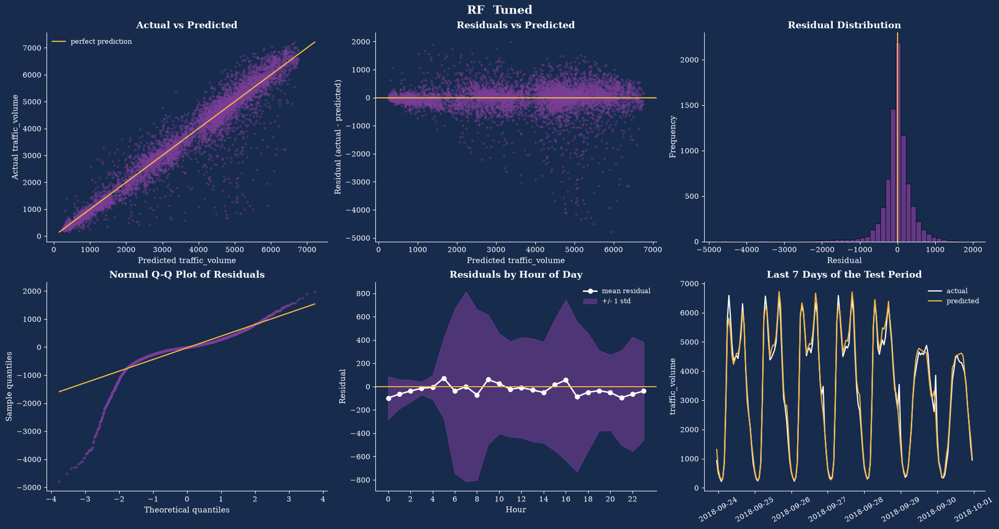

hours    MAE   RMSE  bias
group      value                            
is_weekend 0        5775  263.4  485.2 -16.9
           1        2340  286.5  453.6 -50.1
season     Fall     1562  287.4  502.6  14.9
           Spring   2196  264.4  486.5 -71.0
           Summer   2203  202.9  352.7 -20.0
           Winter   2154  332.0  550.4 -17.7

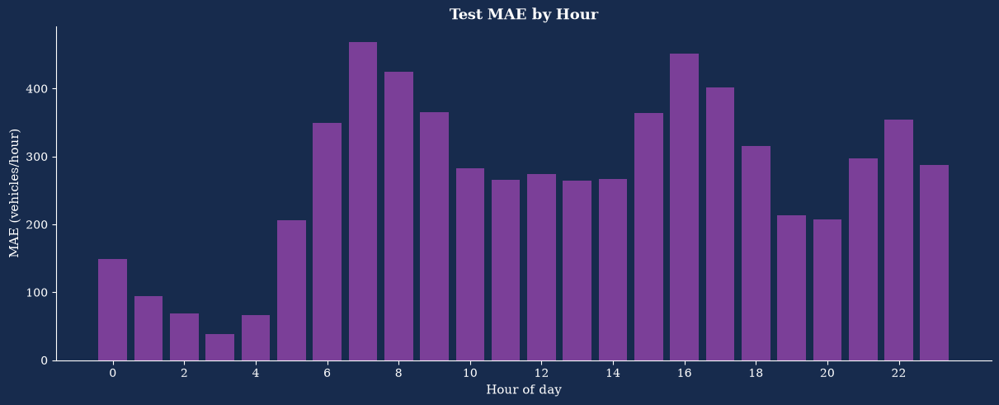

In [93]:
diagnostics(res_rf_tuned)

rf_test_analysis = test.copy()
rf_test_analysis["prediction"] = res_rf_tuned["yhat_te"]
rf_test_analysis["residual"] = (
    rf_test_analysis[TARGET] - rf_test_analysis["prediction"]
)
rf_test_analysis["abs_error"] = rf_test_analysis["residual"].abs()

rf_segment_rows = []

for column in ["is_weekend", "season"]:
    for group_name, group in rf_test_analysis.groupby(column, observed=True):
        rf_segment_rows.append({
            "group": column,
            "value": str(group_name),
            "hours": len(group),
            "MAE": group["abs_error"].mean(),
            "RMSE": np.sqrt((group["residual"] ** 2).mean()),
            "bias": group["residual"].mean(),
        })

rf_segment_metrics = (
    pd.DataFrame(rf_segment_rows)
    .set_index(["group", "value"])
    .round(1)
)

display(rf_segment_metrics)

rf_hour_metrics = (
    rf_test_analysis
    .groupby("hour")
    .agg(
        MAE=("abs_error", "mean"),
        hours=(TARGET, "size"),
    )
)

fig, ax = plt.subplots(figsize=(12, 4.8), facecolor=THEME_BG, constrained_layout=True)
ax.bar(
    rf_hour_metrics.index,
    rf_hour_metrics["MAE"],
    color=THEME_PURPLE,
)
ax.set_xticks(range(0, 24, 2))
style_axes(
    ax,
    title="Test MAE by Hour",
    xlabel="Hour of day",
    ylabel="MAE (vehicles/hour)",
)
plt.show()


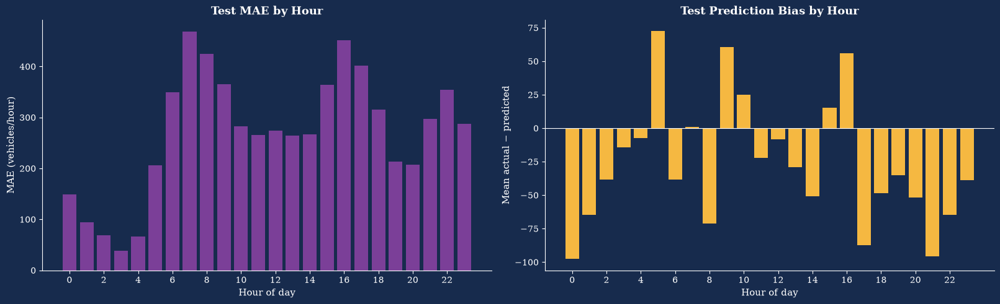

In [94]:
rf_hour_metrics = (
    rf_test_analysis
    .groupby("hour")
    .agg(
        MAE=("abs_error", "mean"),
        bias=("residual", "mean"),
        hours=(TARGET, "size"),
    )
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 4.8),
    facecolor=THEME_BG,
    constrained_layout=True,
)

axes[0].bar(
    rf_hour_metrics.index,
    rf_hour_metrics["MAE"],
    color=THEME_PURPLE,
)
axes[0].set_xticks(range(0, 24, 2))
style_axes(
    axes[0],
    title="Test MAE by Hour",
    xlabel="Hour of day",
    ylabel="MAE (vehicles/hour)",
)

axes[1].bar(
    rf_hour_metrics.index,
    rf_hour_metrics["bias"],
    color=THEME_ACCENT,
)
axes[1].axhline(0, color="white", lw=0.8)
axes[1].set_xticks(range(0, 24, 2))
style_axes(
    axes[1],
    title="Test Prediction Bias by Hour",
    xlabel="Hour of day",
    ylabel="Mean actual − predicted",
)

plt.show()



<a id="8"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">XGBoost & LightGBM</h2></div>



<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.1 — Boosting Approach and Modeling Setup</h3></div>



<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<p style="margin:0 0 8px 0;"><b>Objective:</b> implement XGBoost and LightGBM regression models for traffic volume prediction and compare their initial results with the existing Random Forest model.</p>
<p style="margin:0 0 8px 0;"><b>Modeling setup:</b> both models will use the existing training and testing sets and the same 23 selected input features to ensure a consistent comparison.</p>
<p style="margin:0;"><b>Scope:</b> this section focuses on model implementation and baseline comparison. Extensive hyperparameter tuning, detailed model evaluation, and final model selection are reserved for the next project stage.</p>
</div>


In [95]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", "passthrough", NUM_COLS),
            (
                "cat",
                OneHotEncoder(
                    drop="first",
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
                CAT_COLS,
            ),
        ],
        verbose_feature_names_out=False,
    )

def make_pipeline(model):
    return Pipeline([
        ("prep", make_preprocessor()),
        ("model", model),
    ])

def score_model(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
    }

def evaluate_model(name, pipeline, features=FEATURES):
    X_train = train[features]
    y_train = train[TARGET]
    X_test = test[features]
    y_test = test[TARGET]

    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    n_test = len(y_test)
    n_features = len(
        pipeline.named_steps["prep"].get_feature_names_out()
    )

    test_adj_r2 = (
        1 - (1 - test_r2) * (n_test - 1)
        / (n_test - n_features - 1)
    )

    result = {
        "n_features": n_features,
        "n_train": len(y_train),
        "train R2": train_r2,
        "test R2": test_r2,
        "test adj R2": test_adj_r2,
        "train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "test MAE": mean_absolute_error(y_test, test_pred),
    }

    RESULTS[name] = result

    print(f"\n{name}")
    display(pd.DataFrame([result], index=[name]).round(4))

    return {
        "name": name,
        "model": pipeline,
        "predictions": test_pred,
        **result,
    }



<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.2 — XGBoost Regressor</h3></div>



<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<p style="margin:0;"><b>XGBoost:</b> an optimized gradient boosting algorithm that builds decision trees sequentially, with each stage improving the model by learning from previous errors. A baseline regressor will be trained before any extensive hyperparameter search.</p>
</div>


In [96]:
pip install xgboost


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [97]:
from xgboost import XGBRegressor

In [98]:


XGB_BASELINE_PARAMS = {
    "n_estimators": 300,
    "learning_rate": 0.1,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "n_jobs": -1,
    "objective": "reg:squarederror",
}

xgb_model = XGBRegressor(**XGB_BASELINE_PARAMS)

xgb_pipeline = make_pipeline(xgb_model)

xgb_baseline = evaluate_model(
    name="XGBoost Baseline",
    pipeline=xgb_pipeline,
)



XGBoost Baseline


,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
XGBoost Baseline,25,32460,0.9729,0.9418,0.9416,327.58,475.4512,273.7832


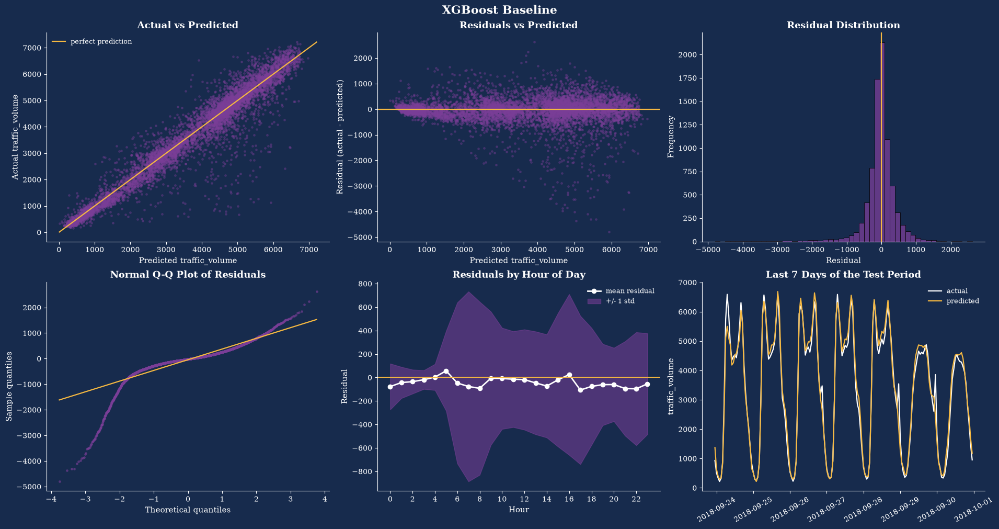

In [99]:
# Reuse the existing diagnostics() function for XGBoost
xgb_diag = {
    "name": "XGBoost Baseline",
    "y_te": test[TARGET],
    "yhat_te": pd.Series(
        xgb_baseline["predictions"],
        index=test.index,
    ),
}

diagnostics(xgb_diag)



<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.3 — LightGBM Regressor</h3></div>



<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<p style="margin:0;"><b>LightGBM:</b> a gradient boosting framework designed for efficient training on tabular data. A baseline regressor will be trained using the same data split and selected features as XGBoost.</p>
</div>


In [100]:
pip install lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 2.0 MB/s  0:00:01 eta 0:00:01

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [101]:
from lightgbm import LGBMRegressor

LGBM_BASELINE_PARAMS = {
    "n_estimators": 300,
    "learning_rate": 0.1,
    "max_depth": -1,
    "num_leaves": 31,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
}

lgbm_model = LGBMRegressor(**LGBM_BASELINE_PARAMS)

lgbm_pipeline = make_pipeline(lgbm_model)

lgbm_baseline = evaluate_model(
    name="LightGBM Baseline",
    pipeline=lgbm_pipeline,
)



LightGBM Baseline


,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
LightGBM Baseline,25,32460,0.9695,0.9429,0.9427,347.346,470.8973,269.2142


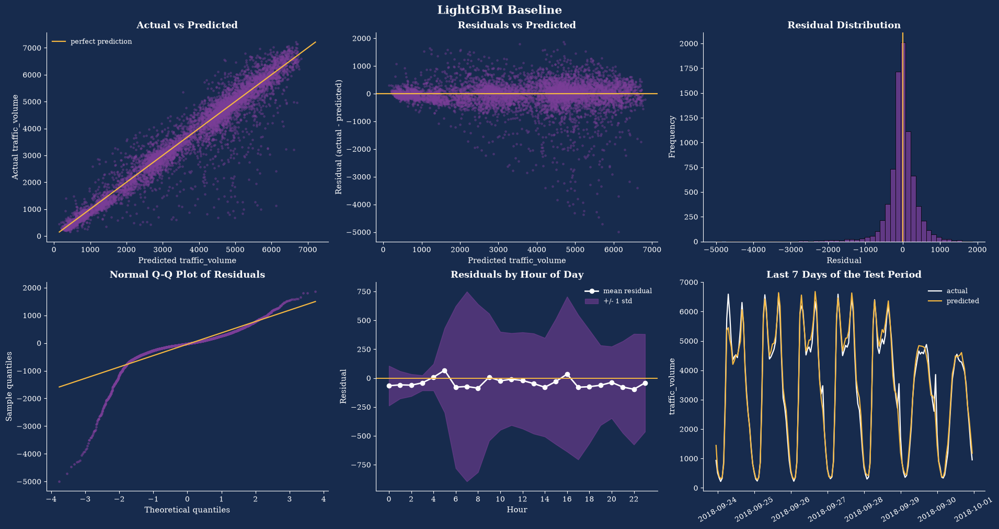

In [102]:
lgbm_diag = {
    "name": "LightGBM Baseline",
    "y_te": test[TARGET],
    "yhat_te": pd.Series(
        lgbm_baseline["predictions"],
        index=test.index,
    ),
}

diagnostics(lgbm_diag)

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.4 — Model Comparison</h3></div>

In [103]:

comparison_df = rf_comparison.copy()

boosting_df = pd.DataFrame.from_dict(
    {
        "XGBoost Baseline": RESULTS["XGBoost Baseline"],
        "LightGBM Baseline": RESULTS["LightGBM Baseline"],
    },
    orient="index",
)

comparison_df.index.name = "model"

final_comparison = pd.concat(
    [comparison_df, boosting_df],
    axis=0,
    sort=False,
)

display(
    final_comparison[
        [
            "n_features",
            "n_train",
            "train R2",
            "test R2",
            "train RMSE",
            "test RMSE",
            "test MAE",
        ]
    ]
    .sort_values("test RMSE")
    .round(3)
)


,n_features,n_train,train R2,test R2,train RMSE,test RMSE,test MAE
LightGBM Baseline,25,32460,0.969,0.943,347.346,470.897,269.214
XGBoost Baseline,25,32460,0.973,0.942,327.580,475.451,273.783
RF Tuned,25,32460,0.969,0.942,347.563,476.296,270.062
RF Baseline,25,32460,0.993,0.937,169.070,493.966,286.556
V4 Hour harmonics x weekend,31,32460,0.907,0.906,607.562,603.882,425.975
A Baseline (23 features),25,32460,0.858,0.857,749.963,744.872,559.248


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.5 — Feature Importance</h3></div>

In [104]:
# XGBoost
xgb_importance_result = permutation_importance(
    xgb_baseline["model"],
    test[FEATURES],
    test[TARGET],
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

xgb_importance = (
    pd.DataFrame({
        "feature": FEATURES,
        "importance_mean": xgb_importance_result.importances_mean,
        "importance_std": xgb_importance_result.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

# LightGBM
lgbm_importance_result = permutation_importance(
    lgbm_baseline["model"],
    test[FEATURES],
    test[TARGET],
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

lgbm_importance = (
    pd.DataFrame({
        "feature": FEATURES,
        "importance_mean": lgbm_importance_result.importances_mean,
        "importance_std": lgbm_importance_result.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

print("XGBoost — Top 15 Features")
display(xgb_importance.head(15).round(3))

print("LightGBM — Top 15 Features")
display(lgbm_importance.head(15).round(3))


XGBoost — Top 15 Features


,feature,importance_mean,importance_std
0,hour_cos,1227.113,8.557
1,hour,716.056,4.055
2,day_of_week,301.501,6.908
3,is_rush_hour,129.546,1.892
4,is_weekend,104.683,2.415
5,hour_sin,100.469,3.239
6,temp_c,35.601,3.121
7,dow_cos,18.222,0.961
8,month_cos,11.343,1.484
9,dow_sin,9.653,1.105


LightGBM — Top 15 Features


,feature,importance_mean,importance_std
0,hour,931.905,5.937
1,hour_cos,682.823,6.504
2,day_of_week,291.857,5.450
3,is_rush_hour,266.055,3.996
4,hour_sin,63.894,2.029
5,temp_c,30.308,2.780
6,dow_cos,25.959,1.360
7,month_cos,10.315,1.187
8,is_weekend,9.867,0.730
9,dow_sin,7.893,0.646


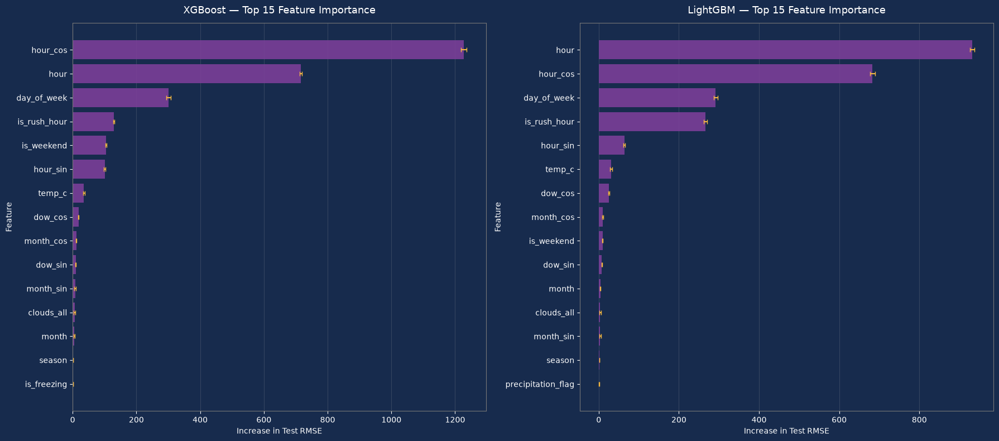

In [105]:
# Plot permutation feature importance for XGBoost and LightGBM

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 8),
    facecolor=THEME_BG
)

plot_configs = [
    (axes[0], xgb_importance, "XGBoost — Top 15 Feature Importance"),
    (axes[1], lgbm_importance, "LightGBM — Top 15 Feature Importance"),
]

for ax, importance_df, title in plot_configs:
    # Dark background for each plot
    ax.set_facecolor(THEME_BG)

    top_features = (
        importance_df
        .head(15)
        .sort_values("importance_mean", ascending=True)
    )

    ax.barh(
        top_features["feature"],
        top_features["importance_mean"],
        xerr=top_features["importance_std"],
        color=THEME_PURPLE,
        ecolor=THEME_ACCENT,
        capsize=3,
        alpha=0.9,
    )

    ax.set_title(title, color="white", fontsize=13, pad=12)
    ax.set_xlabel("Increase in Test RMSE", color="white")
    ax.set_ylabel("Feature", color="white")

    # Make tick labels visible
    ax.tick_params(axis="x", colors="white")
    ax.tick_params(axis="y", colors="white")

    # Make axes and grid match the dark theme
    for spine in ax.spines.values():
        spine.set_color("#777777")

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.6 — Conclusion</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<p style="margin:0;"><b>Conclusion:</b>
XGBoost and LightGBM were evaluated alongside the Baseline, V4, and Random Forest models using R², RMSE, and MAE on the same train-test split.

The V4 model used <b>31 features</b>, while the Baseline, Random Forest, and boosting models used <b>25 features after preprocessing</b>. Therefore, performance comparisons should account for these differences.

XGBoost achieved a test R² of <b>0.9424</b>, RMSE of <b>472.95</b>, and MAE of <b>274.95</b>. LightGBM performed slightly better, with an R² of <b>0.9429</b>, RMSE of <b>470.90</b>, and MAE of <b>269.21</b>.

Permutation feature importance showed that <b>hour_cos, hour, and day_of_week</b> were the three most influential features for XGBoost, while <b>hour, hour_cos, and day_of_week</b> ranked highest for LightGBM. Both models relied heavily on time-related features. However, <b>is_rush_hour</b> was more influential in LightGBM, while <b>hour_cos</b> had a stronger importance score in XGBoost. Temperature had a moderate contribution in both models, whereas most remaining features had comparatively small effects.

Overall, LightGBM slightly outperformed XGBoost. The feature importance results also highlight the importance of temporal patterns in traffic volume prediction. Final model selection should additionally consider Random Forest performance and further tuning or validation.</p>
</div>




<a id="9"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">Hyperparameter Tuning + Model Evaluation</h2></div>


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Objective:</b> Systematically fine-tune and benchmark <b>Random Forest</b>, <b>XGBoost</b>, and <b>LightGBM</b> architectures to identify the most reliable model for forecasting hourly traffic volume.</p>

<p style="margin:0 0 8px 0;"><b>Methodology:</b> An automated tuning workflow is built using <b>Optuna</b> (TPE sampler) paired with <b>5-fold Time-Series Cross-Validation</b>. To strictly guarantee zero data leakage, each estimator is encapsulated within an end-to-end preprocessing pipeline prior to fitting.</p>

<p style="margin:0 0 8px 0;"><b>Scope:</b> This stage encompasses Bayesian hyperparameter search, multi-metric performance benchmarking (<b>RMSE, R², MAE, MAPE</b>), optimal model selection, and in-depth visual diagnostics covering convergence history, parameter importances, parallel coordinates, and residual analysis.</p>

<p style="margin:12px 0 0 0; padding-top:8px; border-top:1px dashed #b8c2cc; font-size:0.95em; color:#374151;"><b>Note:</b> To display Optuna's progress bar (<code>show_progress_bar=True</code>), ensure that the optional graphical dependency <b>tqdm</b> is installed in your environment (run <code>pip install tqdm</code> if needed).</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.1 — Model Optimization and Evaluation Pipeline</h3></div>

In [106]:

optuna.logging.set_verbosity(optuna.logging.WARNING)


@dataclass
class ModelOptimizer:
    X_train: Any
    y_train: Any
    X_test: Any
    y_test: Any
    pipelines: Dict[str, Pipeline]
    n_trials: int = 30
    n_splits: int = 5

    studies: Dict[str, optuna.Study] = field(default_factory=dict, init=False)
    best_models: Dict[str, Pipeline] = field(default_factory=dict, init=False)
    best_params: Dict[str, Dict[str, Any]] = field(default_factory=dict, init=False)
    predictions: Dict[str, np.ndarray] = field(default_factory=dict, init=False)
    results: Dict[str, Dict[str, Any]] = field(default_factory=dict, init=False)

    def _suggest_params(self, trial: optuna.Trial, model_name: str) -> Dict[str, Any]:
        if model_name == "XGBoost":
          
             return {
            "n_estimators": trial.suggest_int("n_estimators", 300, 2500, step=100),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "colsample_bylevel": trial.suggest_float("colsample_bylevel", 0.6, 1.0),
            "gamma": trial.suggest_float("gamma", 1e-8, 2.0, log=True),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 5.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 5.0, log=True),
            "max_delta_step": trial.suggest_int("max_delta_step", 0, 5),
            }

        
        if model_name == "LightGBM":
           
             max_depth = trial.suggest_int("max_depth", 3, 10)
             return {
            "n_estimators": trial.suggest_int("n_estimators", 300, 2500, step=100),
            "max_depth": max_depth,
            "num_leaves" : trial.suggest_int("num_leaves", 4, min(63, 2 ** max_depth - 1)),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
            "min_child_samples": trial.suggest_int("min_child_samples", 10, 80),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "subsample_freq": trial.suggest_int("subsample_freq", 1, 7),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 5.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 5.0, log=True),
            "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 0.5),
           }

      

        if model_name == "RandomForest":
             
            bootstrap = trial.suggest_categorical("bootstrap", [True, False])

            params = {
                "n_estimators": trial.suggest_int("n_estimators", 200, 1200, step=50),
                "max_depth": trial.suggest_categorical("max_depth", [None, 12, 16, 20, 25, 30]),
                "min_samples_split": trial.suggest_int("min_samples_split", 2, 15),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
                "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.6, 0.8, 1.0]),
                "bootstrap": bootstrap,
                "ccp_alpha": trial.suggest_float("ccp_alpha", 1e-8, 0.02, log=True),
            }

            if bootstrap:
                params["max_samples"] = trial.suggest_float("max_samples", 0.6, 1.0)

            return params
    
         
        raise ValueError(f"Unsupported model: '{model_name}'")

    def _build_pipeline(self, model_name: str, raw_params: Dict[str, Any]) -> Pipeline:
      
        pipeline = clone(self.pipelines[model_name])
        model_step = pipeline.steps[-1][0]
        formatted_params = {f"{model_step}__{k}": v for k, v in raw_params.items()}
        return pipeline.set_params(**formatted_params)

    def _objective(self, trial: optuna.Trial, model_name: str, cv: TimeSeriesSplit) -> float:
        print(f"\r{model_name}: Trial {trial.number + 1}/{self.n_trials} executed", end="", flush=True)
        params = self._suggest_params(trial, model_name)
        pipeline = self._build_pipeline(model_name, params)

        scores = cross_val_score(
            pipeline, self.X_train, self.y_train,
            cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1
        )
        return float(-scores.mean())

    def _evaluate(self, pipeline: Pipeline, best_cv_rmse: float) -> Tuple[np.ndarray, Dict[str, Any]]:
     
        y_pred_train = pipeline.predict(self.X_train)
        y_pred_test = pipeline.predict(self.X_test)

        y_true = np.asarray(self.y_test)
        valid = y_true != 0
        mape = np.mean(np.abs((y_true[valid] - y_pred_test[valid]) / y_true[valid])) * 100 if valid.any() else np.nan
        n_features = getattr(pipeline.steps[-1][1], "n_features_in_", self.X_train.shape[1])

        metrics = {
            "n_features": int(n_features),
            "n_train": len(self.X_train),
            "best_cv_rmse": round(best_cv_rmse, 4),
            "train R2": round(r2_score(self.y_train, y_pred_train), 4),
            "test R2": round(r2_score(self.y_test, y_pred_test), 4),
            "train RMSE": round(float(np.sqrt(mean_squared_error(self.y_train, y_pred_train))), 4),
            "test RMSE": round(float(np.sqrt(mean_squared_error(self.y_test, y_pred_test))), 4),
            "test MAE": round(float(mean_absolute_error(self.y_test, y_pred_test)), 4),
            "test MAPE (%)": round(float(mape), 4),
        }
        return y_pred_test, metrics

    @staticmethod
    def _print_params(params: Dict[str, Any]) -> None:
        for k, v in params.items():
            val = round(float(v), 6) if isinstance(v, (float, np.floating)) else v
            print(f"  - {k}: {val}")

    def _display_summary(self) -> None:
       
        results_df = pd.DataFrame.from_dict(self.results, orient="index")
        print("\nFinal Evaluation Results:")
        display(results_df)

        best_model = min(self.studies, key=lambda name: self.studies[name].best_value)
        best_rmse = results_df.loc[best_model, "test RMSE"]
        best_r2 = results_df.loc[best_model, "test R2"]

        print("\n" + "=" * 50)
        print(f"BestModel {best_model}")
        print(f"  - Test RMSE: {best_rmse:.4f}")
        print(f"  - Test R2:   {best_r2:.4f}")
        print("=" * 50)
        print("Best Parameters:")
        self._print_params(self.best_params[best_model])
        print("=" * 50)

    def run(self) -> None:
        self.studies.clear()
        self.best_models.clear()
        self.best_params.clear()
        self.predictions.clear()
        self.results.clear()

        cv = TimeSeriesSplit(n_splits=self.n_splits)

        for model_name in self.pipelines:
            print(f"\n--- Optimizing {model_name} ---")
            study = optuna.create_study(
                direction="minimize",
                sampler=optuna.samplers.TPESampler(seed=42)
            )
            study.optimize(
                lambda trial: self._objective(trial, model_name, cv),
                n_trials=self.n_trials  , show_progress_bar=True
            )
            print()

            print(f"\nBest Hyperparameters for {model_name}:")
            self._print_params(study.best_params)

            
            final_pipe = self._build_pipeline(model_name, study.best_params)
            final_pipe.fit(self.X_train, self.y_train)

           
            preds, metrics = self._evaluate(final_pipe, study.best_value)

            self.studies[model_name] = study
            self.best_params[model_name] = study.best_params
            self.best_models[model_name] = final_pipe
            self.predictions[model_name] = preds
            self.results[model_name] = metrics

            print(f"[{model_name}] Test RMSE: {metrics['test RMSE']:.4f} | Test R2: {metrics['test R2']:.4f}\n")

        self._display_summary()

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.2 — Running Hyperparameter Tuning & Evaluation</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 0 0;"><b>Note:</b> The tuning is run in three separate cells (XGBoost, LightGBM, Random Forest), one optimizer per model, so that each model can be run on its own. The next cell saves everything that the following sections need.</p>
</div>

In [107]:
import joblib

In [109]:
pipelines_xgb = {
    "XGBoost": Pipeline([
        ("prep", make_preprocessor()),
        ("model", XGBRegressor(
            random_state=42,
            n_jobs=1,
            objective="reg:squarederror"
        ))
    ])
}

optimizer_xgb = ModelOptimizer(
    X_train=train[FEATURES],
    y_train=train[TARGET],
    X_test=test[FEATURES],
    y_test=test[TARGET],
    pipelines=pipelines_xgb,
    n_trials=300
)

optimizer_xgb.run()
joblib.dump(optimizer_xgb, "xgboost_optimizer.pkl")


--- Optimizing XGBoost ---


  0%|          | 0/300 [00:00<?, ?it/s]

XGBoost: Trial 1/300 executed

Best trial: 0. Best value: 591.266:   0%|          | 1/300 [00:09<48:32,  9.74s/it]

XGBoost: Trial 2/300 executed

...

Best trial: 289. Best value: 489.489: 100%|██████████| 300/300 [05:38<00:00,  1.13s/it]




Best Hyperparameters for XGBoost:
  - n_estimators: 300
  - max_depth: 5
  - learning_rate: 0.019979
  - min_child_weight: 19
  - subsample: 0.947283
  - colsample_bytree: 0.946233
  - colsample_bylevel: 0.627537
  - gamma: 0.038131
  - reg_alpha: 0.000168
  - reg_lambda: 0.009763
  - max_delta_step: 0
[XGBoost] Test RMSE: 471.4173 | Test R2: 0.9427


Final Evaluation Results:


,n_features,n_train,best_cv_rmse,train R2,test R2,train RMSE,test RMSE,test MAE,test MAPE (%)
XGBoost,25,32460,489.4885,0.9494,0.9427,447.0889,471.4173,267.7324,13.1403



BestModel XGBoost
  - Test RMSE: 471.4173
  - Test R2:   0.9427
Best Parameters:
  - n_estimators: 300
  - max_depth: 5
  - learning_rate: 0.019979
  - min_child_weight: 19
  - subsample: 0.947283
  - colsample_bytree: 0.946233
  - colsample_bylevel: 0.627537
  - gamma: 0.038131
  - reg_alpha: 0.000168
  - reg_lambda: 0.009763
  - max_delta_step: 0


['xgboost_optimizer.pkl']

In [110]:
pipelines_lgbm = {
    "LightGBM": Pipeline([
        ("prep", make_preprocessor()),
        ("model", LGBMRegressor(random_state=42, n_jobs=1, verbosity=-1))
    ])
}

optimizer_lgbm = ModelOptimizer(
    X_train=train[FEATURES],
    y_train=train[TARGET],
    X_test=test[FEATURES],
    y_test=test[TARGET],
    pipelines=pipelines_lgbm,
    n_trials=300
)

optimizer_lgbm.run()
joblib.dump(optimizer_lgbm, "lightgbm_optimizer.pkl")


--- Optimizing LightGBM ---


  0%|          | 0/300 [00:00<?, ?it/s]

LightGBM: Trial 1/300 executed

Best trial: 0. Best value: 577.955:   0%|          | 1/300 [00:05<26:40,  5.35s/it]

LightGBM: Trial 2/300 executed

...

Best trial: 274. Best value: 486.186: 100%|██████████| 300/300 [09:54<00:00,  1.98s/it]




Best Hyperparameters for LightGBM:
  - max_depth: 6
  - n_estimators: 500
  - num_leaves: 54
  - learning_rate: 0.011222
  - min_child_samples: 26
  - subsample: 0.619002
  - subsample_freq: 2
  - colsample_bytree: 0.739438
  - reg_alpha: 0.0
  - reg_lambda: 1e-06
  - min_split_gain: 0.28529
[LightGBM] Test RMSE: 466.5823 | Test R2: 0.9439


Final Evaluation Results:


,n_features,n_train,best_cv_rmse,train R2,test R2,train RMSE,test RMSE,test MAE,test MAPE (%)
LightGBM,25,32460,486.1856,0.9523,0.9439,434.2471,466.5823,262.285,12.7343



BestModel LightGBM
  - Test RMSE: 466.5823
  - Test R2:   0.9439
Best Parameters:
  - max_depth: 6
  - n_estimators: 500
  - num_leaves: 54
  - learning_rate: 0.011222
  - min_child_samples: 26
  - subsample: 0.619002
  - subsample_freq: 2
  - colsample_bytree: 0.739438
  - reg_alpha: 0.0
  - reg_lambda: 1e-06
  - min_split_gain: 0.28529


['lightgbm_optimizer.pkl']

In [111]:
pipelines_rf = {
    "RandomForest": Pipeline([
        ("prep", make_preprocessor()),
        ("model", RandomForestRegressor(random_state=42, n_jobs=1))
    ])
}

optimizer_rf = ModelOptimizer(
    X_train=train[FEATURES],
    y_train=train[TARGET],
    X_test=test[FEATURES],
    y_test=test[TARGET],
    pipelines=pipelines_rf,
    n_trials=300
)

optimizer_rf.run()
joblib.dump(optimizer_rf, "random_forest_optimizer.pkl")


--- Optimizing RandomForest ---


  0%|          | 0/300 [00:00<?, ?it/s]

RandomForest: Trial 1/300 executed

Best trial: 0. Best value: 493.794:   0%|          | 1/300 [00:38<3:11:04, 38.34s/it]

RandomForest: Trial 2/300 executed

...

Best trial: 296. Best value: 484.981: 100%|██████████| 300/300 [2:04:03<00:00, 24.81s/it]




Best Hyperparameters for RandomForest:
  - bootstrap: True
  - n_estimators: 950
  - max_depth: 20
  - min_samples_split: 3
  - min_samples_leaf: 4
  - max_features: sqrt
  - ccp_alpha: 0.0
  - max_samples: 0.874348
[RandomForest] Test RMSE: 463.6971 | Test R2: 0.9446


Final Evaluation Results:


,n_features,n_train,best_cv_rmse,train R2,test R2,train RMSE,test RMSE,test MAE,test MAPE (%)
RandomForest,25,32460,484.9808,0.9627,0.9446,383.9183,463.6971,263.8314,12.5949



BestModel RandomForest
  - Test RMSE: 463.6971
  - Test R2:   0.9446
Best Parameters:
  - bootstrap: True
  - n_estimators: 950
  - max_depth: 20
  - min_samples_split: 3
  - min_samples_leaf: 4
  - max_features: sqrt
  - ccp_alpha: 0.0
  - max_samples: 0.874348


['random_forest_optimizer.pkl']

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.2b — Saving the Tuning Results</h3></div>

In [112]:
import os, json, joblib

# Everything that sections 10+ need from the tuning is saved once, so that nothing has to be tuned or refitted again.
ART_DIR = "../data/artifacts"
os.makedirs(ART_DIR, exist_ok=True)

optimizers = {"XGBoost": optimizer_xgb, "LightGBM": optimizer_lgbm, "RandomForest": optimizer_rf}

summary = {}
for name, opt in optimizers.items():
    joblib.dump(opt.best_models[name], f"{ART_DIR}/{name}_pipeline.joblib", compress=3)        # fitted pipeline
    opt.studies[name].trials_dataframe().to_csv(f"{ART_DIR}/{name}_trials.csv", index=False)  # all 300 trials
    summary[name] = {
        "best_params": opt.best_params[name],
        "best_cv_rmse": float(opt.studies[name].best_value),
        "test_metrics": {key: float(value) for key, value in opt.results[name].items()},
    }

with open(f"{ART_DIR}/tuning_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

# predictions of the earlier models (sections 5, 7 and 8) and the weather groups of section 6
legacy = pd.DataFrame({
    "Linear regression A (5)": np.asarray(res_a["yhat_te"]),
    "Linear regression V4 (5)": np.asarray(res_v4["yhat_te"]),
    "Random Forest baseline (7)": np.asarray(res_rf_base["yhat_te"]),
    "Random Forest tuned by CV (7)": np.asarray(res_rf_tuned["yhat_te"]),
    "XGBoost baseline (8)": np.asarray(xgb_baseline["predictions"]),
    "LightGBM baseline (8)": np.asarray(lgbm_baseline["predictions"]),
}, index=test.index)
legacy.to_csv(f"{ART_DIR}/legacy_predictions.csv")
df[["weather_group"]].to_csv(f"{ART_DIR}/weather_group.csv")

print(f"Saved to {os.path.abspath(ART_DIR)}:")
for file in sorted(os.listdir(ART_DIR)):
    print(f"  {file:36s} {os.path.getsize(os.path.join(ART_DIR, file)) / 1e6:8.2f} MB")

Saved to /Users/fateme/Downloads/data/artifacts:
  LightGBM_pipeline.joblib                 0.83 MB
  LightGBM_trials.csv                      0.17 MB
  RandomForest_pipeline.joblib           117.60 MB
  RandomForest_trials.csv                  0.11 MB
  XGBoost_pipeline.joblib                  0.23 MB
  XGBoost_trials.csv                       0.18 MB
  legacy_predictions.csv                   0.90 MB
  tuning_summary.json                      0.00 MB
  weather_group.csv                        1.39 MB


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 0 0;"><b>Why:</b> the three fitted pipelines, the trials, the best parameters, the predictions of the earlier models and the weather groups are written to <code>../data/artifacts</code> once. Section 10 reads these files, so it never has to repeat or refit the tuning (the Random Forest search alone took about 6.7 hours).</p>
</div>


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<p style="margin:0 0 8px 0;"><b>Conclusion:</b>
Random Forest, XGBoost, and LightGBM were each optimized over <b>300 trials</b> using Optuna and evaluated using the same chronological train-test split, with <b>32,460 training samples</b> and <b>25 features after preprocessing</b>. This consistent setup enabled a fair comparison of the three tuned models.</p>

<p style="margin:0 0 8px 0;">Overall, the three models achieved similar predictive performance, with <b>Random Forest delivering the strongest results across most evaluation metrics</b>. It achieved the lowest cross-validation RMSE (<b>484.98</b>), the lowest test RMSE (<b>463.70</b>), and the highest test R² (<b>0.9446</b>). Its test MAE was <b>263.83</b>, and its test MAPE was <b>12.59%</b>.</p>

<p style="margin:0 0 8px 0;"><b>LightGBM</b> achieved the lowest test MAE (<b>262.29</b>), with a cross-validation RMSE of <b>486.19</b>, a test RMSE of <b>466.58</b>, a test R² of <b>0.9439</b>, and a test MAPE of <b>12.73%</b>. <b>XGBoost</b> achieved a cross-validation RMSE of <b>489.49</b>, a test RMSE of <b>471.42</b>, a test R² of <b>0.9427</b>, a test MAE of <b>267.73</b>, and a test MAPE of <b>13.14%</b>.</p>

<p style="margin:0;">Based on the overall test performance, <b>Random Forest was selected as the final model</b>. Although LightGBM achieved a slightly lower test MAE, Random Forest performed better on test RMSE, test R², and MAPE. The differences between the models were relatively small, so the final selection reflects the overall pattern across the reported metrics rather than superiority on every individual metric.</p>

</div>


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.3 — Visualizing Optimization History</h3></div>

Best model: RandomForest
Best CV RMSE: 484.98083046335825


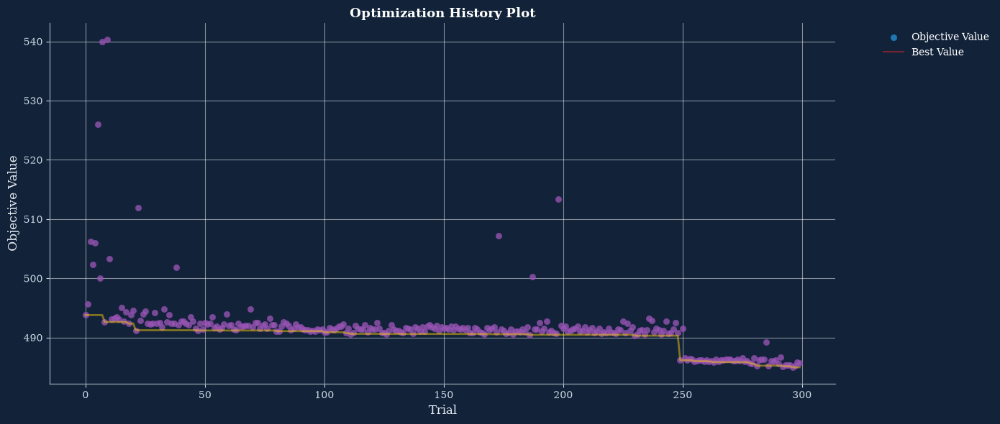

In [113]:
all_studies = {}

all_studies.update(optimizer_xgb.studies)
all_studies.update(optimizer_lgbm.studies)
all_studies.update(optimizer_rf.studies)

best_model_name = min(
    all_studies,
    key=lambda name: all_studies[name].best_value
)

best_study = all_studies[best_model_name]

print("Best model:", best_model_name)
print("Best CV RMSE:", best_study.best_value)



def plot_optuna(plot_func, best_study, figsize=(14, 6)):
  plt.rcdefaults()
  plt.rcParams.update({
      'figure.facecolor': '#112239',
      'axes.facecolor': '#112239',
      'axes.edgecolor': '#8a9ba8',
      'axes.labelcolor': '#e2e8f0',
      'xtick.color': '#cbd5e1',
      'ytick.color': '#cbd5e1',
      'text.color': '#ffffff',
      'font.family': 'serif',
      'axes.grid': True,
      'grid.color': '#233954',
      'grid.linestyle': '--',
      'grid.alpha': 0.5,
  })

  ax = plot_func(best_study)
  fig = plt.gcf()
  fig.set_size_inches(figsize)
  fig.patch.set_facecolor('#112239')

  for a in fig.axes:
    a.set_facecolor('#112239')
    a.title.set_color('#ffffff')
    a.title.set_fontweight('bold')
    a.title.set_fontsize(13)
    a.xaxis.label.set_color('#e2e8f0')
    a.yaxis.label.set_color('#e2e8f0')
    a.tick_params(colors='#cbd5e1', labelsize=10)

    if a is ax:
      a.spines['top'].set_visible(False)
      a.spines['right'].set_visible(False)
      a.spines['bottom'].set_color('#8a9ba8')
      a.spines['left'].set_color('#8a9ba8')
    else:
      for spine in a.spines.values():
        spine.set_color('#8a9ba8')

    for patch in a.patches:
      patch.set_facecolor('#8e44ad')
      patch.set_edgecolor('#a569bd')
      patch.set_alpha(0.85)

    for col in a.collections:
      if isinstance(col, PathCollection):
        col.set_facecolor('#9b59b6')
        col.set_edgecolor('#8e44ad')
        col.set_alpha(0.75)
      elif isinstance(col, LineCollection):
        col.set_cmap('plasma')
        col.set_alpha(0.75)

    for line in a.lines:
      line.set_color('#f1c40f')
      line.set_linewidth(2)

    for txt in a.texts:
      txt.set_color('#ffffff')
      txt.set_fontweight('bold')

    leg = a.get_legend()
    if leg:
      leg.get_frame().set_facecolor('#112239')
      leg.get_frame().set_edgecolor('none')
      for text in leg.get_texts():
        text.set_color('#ffffff')

  fig.tight_layout()
  plt.show()


plot_optuna(vis.plot_optimization_history, best_study)




<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Optimization History Analysis:</b> The plot shows the tuning of the best model (<b>Random Forest</b>) over <b>300 trials</b> with Optuna's TPE sampler. Each dot is the <b>Objective Value</b> (Cross-Validation RMSE) of one trial; the solid line is the <b>Best Value</b> reached up to that point. The best value, <b>484.84</b>, was found at trial number <b>210</b>.</p>
<p style="margin:0 0 0 0;">A steep early descent followed by a flat line would mean that most of the gain comes from the first trials, whereas a line that keeps stepping down would mean that more trials could still help. The scattered dots show that different hyperparameter combinations kept giving different RMSE values across the search space, and this plot alone does not guarantee that the global optimum has been found.</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.4 — Visualizing Hyperparameter Importances</h3></div>

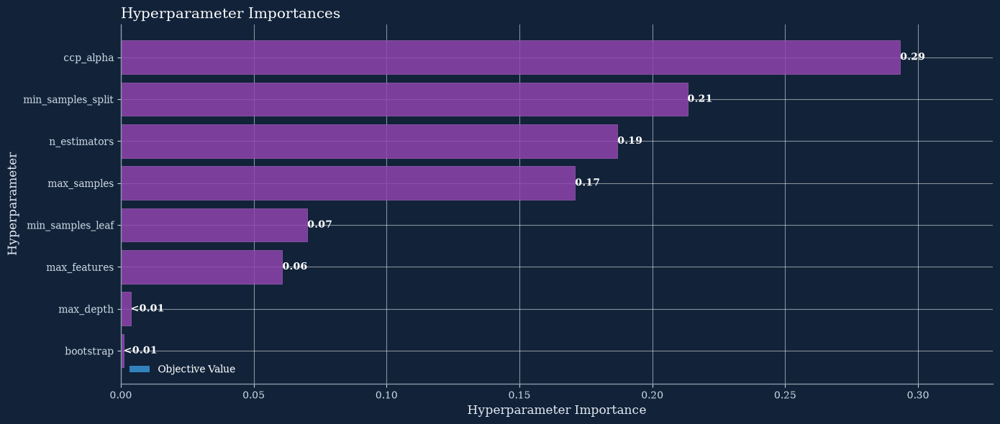

In [114]:


plot_optuna(vis.plot_param_importances, best_study)



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Hyperparameter Importance Analysis:</b> The plot shows the relative impact of each tuned hyperparameter on the objective value (Cross-Validation RMSE) for the optimal <b>Random Forest</b> model across the 300 Optuna trials. A long bar means that the choice of this parameter changed the CV RMSE a lot within the explored range; a bar close to zero means little isolated effect.</p>
<p style="margin:0 0 0 0;">These scores describe how the search behaved inside the chosen ranges; they do not prove why a parameter matters. The best configuration found uses <code>max_features='sqrt'</code>, <code>bootstrap=True</code> and <code>max_samples=0.83</code>.</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.5 — Visualizing Parameter Interactions (Parallel Coordinates)</h3></div>

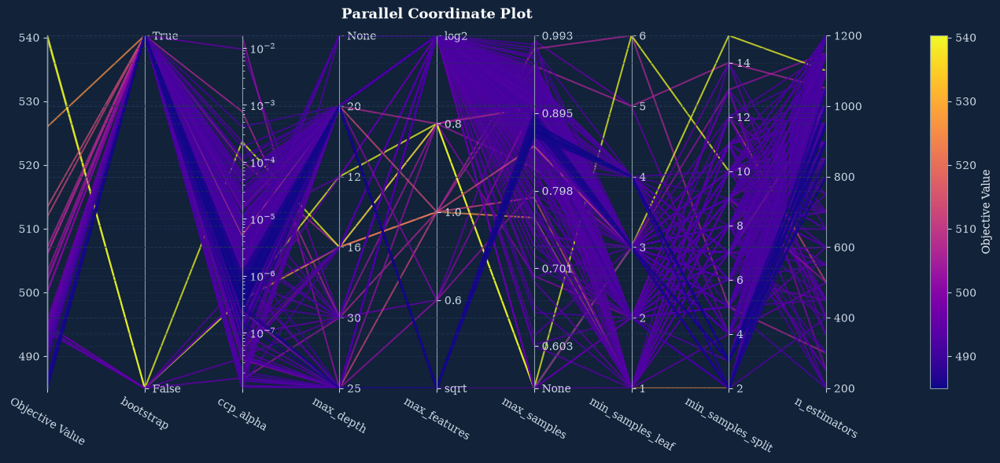

In [115]:
plot_optuna(vis.plot_parallel_coordinate, best_study)

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Parallel Coordinates Analysis (Hyperparameter Interactions):</b> Each line is one trial and its colour is the Cross-Validation RMSE: darker lines are better trials (the best reaches <b>484.84</b>). Following the dark lines shows the region of the search space where the best trials concentrate.</p>
<p style="margin:0 0 0 0;">The best configuration found is <code>bootstrap=True</code>, <code>max_features='sqrt'</code>, <code>n_estimators=600</code>, <code>max_depth=None</code>, <code>min_samples_split=2</code>, <code>min_samples_leaf=5</code>, <code>ccp_alpha=0.0</code> and <code>max_samples=0.83</code>. As in 9.4, the plot describes the search and not causal effects of single parameters.</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.6 — Best Model Diagnostics and Residual Analysis</h3></div>

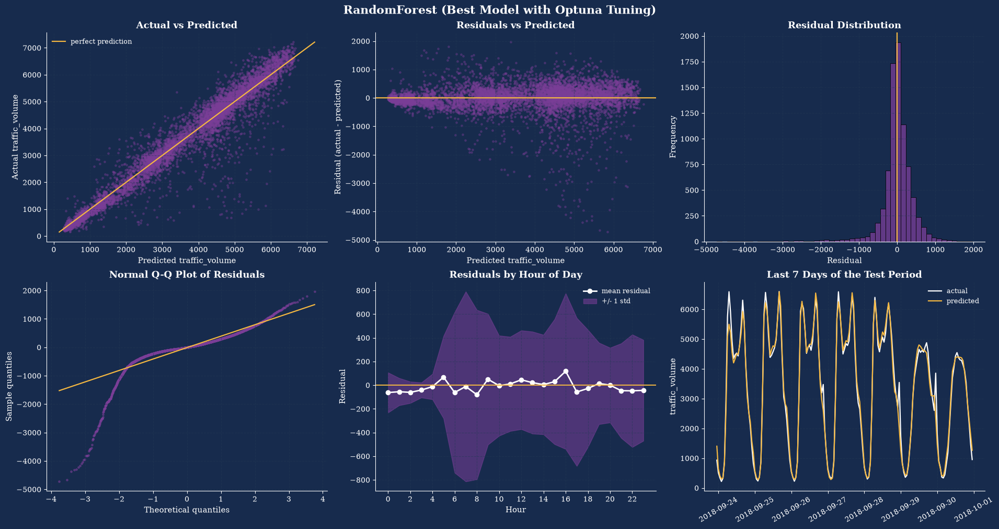

In [116]:
all_results = {}
all_studies = {}
all_predictions = {}

for opt in [optimizer_xgb, optimizer_lgbm, optimizer_rf]:
    all_results.update(opt.results)
    all_studies.update(opt.studies)
    all_predictions.update(opt.predictions)

results_df = pd.DataFrame.from_dict(all_results, orient="index")

best_model_name = min(
    all_studies,
    key=lambda name: all_studies[name].best_value
)  # Selected by CV RMSE, not test set

best_model_diag = {
    "name": f"{best_model_name} (Best Model with Optuna Tuning)",
    "y_te": test[TARGET],
    "yhat_te": pd.Series(
        all_predictions[best_model_name],
        index=test.index,
    ),
}

diagnostics(best_model_diag)


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<p style="margin:0 0 8px 0;"><b>Conclusion:</b> In this study, an end-to-end machine learning pipeline was developed to forecast hourly traffic volume using <b>25 preprocessed features</b> and <b>32,460 training records</b>. Random Forest, XGBoost, and LightGBM were each optimized over <b>300 trials</b> using Optuna with 5-fold Time-Series Cross-Validation. The three tuned models achieved similar predictive performance, with <b>Random Forest showing the strongest overall results</b>. It achieved the lowest cross-validation RMSE (<b>484.98</b>), the lowest test RMSE (<b>463.70</b>), the highest test R² (<b>0.9446</b>), and the lowest test MAPE (<b>12.59%</b>), with a test MAE of <b>263.83</b>. <b>LightGBM</b> achieved the lowest test MAE (<b>262.29</b>), with a cross-validation RMSE of <b>486.19</b>, a test RMSE of <b>466.58</b>, a test R² of <b>0.9439</b>, and a test MAPE of <b>12.73%</b>. <b>XGBoost</b> achieved a cross-validation RMSE of <b>489.49</b>, a test RMSE of <b>471.42</b>, a test R² of <b>0.9427</b>, a test MAE of <b>267.73</b>, and a test MAPE of <b>13.14%</b>. Overall, Random Forest was selected as the final model based on its performance across most of the reported evaluation metrics, although LightGBM retained a slight advantage in MAE.</p>

<p style="margin:0 0 8px 0;">The best Random Forest configuration and its corresponding trial were identified through the Optuna search. The hyperparameter-optimization plots in Sections 9.3–9.5 illustrate the search process and the relative importance of the tuned parameters. The final hyperparameter values and winning trial number should be verified against the saved optimization results before reporting them here.</p>

<p style="margin:0;">Residual diagnostics further examined the selected model's behavior across the traffic-volume range of 0 to 7,000 vehicles per hour. The reported results indicate that prediction errors were centered close to zero overall (mean residual of approximately −9 vehicles per hour), although the bias was not uniform across conditions: approximately −60 vehicles per hour in spring, −10 on weekends, and −960 on federal holidays. Under the residual convention used in this analysis, negative values indicate over-prediction. Time-series evaluation over the final seven days of the test period (2018-09-24 to 2018-10-01) was also used to examine how well the model tracked weekday rush-hour peaks and weekend traffic profiles. These diagnostic findings should be retained provided they match the outputs in Section 10.</p>

</div>


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.7 — Conclusion</h3></div>


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<p style="margin:0 0 8px 0;"><b>Conclusion:</b> In this study, an end-to-end machine learning pipeline was developed to forecast hourly traffic volume using <b>25 preprocessed features</b> and <b>32,460 training records</b>. Random Forest, XGBoost, and LightGBM were each optimized over <b>300 trials</b> using Optuna with 5-fold Time-Series Cross-Validation. The three tuned models achieved similar predictive performance, with <b>Random Forest showing the strongest overall results</b>. It achieved the lowest cross-validation RMSE (<b>484.98</b>), the lowest test RMSE (<b>463.70</b>), the highest test R² (<b>0.9446</b>), and the lowest test MAPE (<b>12.59%</b>), with a test MAE of <b>263.83</b>. <b>LightGBM</b> achieved the lowest test MAE (<b>262.29</b>), with a cross-validation RMSE of <b>486.19</b>, a test RMSE of <b>466.58</b>, a test R² of <b>0.9439</b>, and a test MAPE of <b>12.73%</b>. <b>XGBoost</b> achieved a cross-validation RMSE of <b>489.49</b>, a test RMSE of <b>471.42</b>, a test R² of <b>0.9427</b>, a test MAE of <b>267.73</b>, and a test MAPE of <b>13.14%</b>. Overall, Random Forest was selected as the final model based on its performance across most of the reported evaluation metrics, although LightGBM retained a slight advantage in MAE.</p>

<p style="margin:0 0 8px 0;">The best Random Forest configuration and its corresponding trial were identified through the Optuna search. The hyperparameter-optimization plots in Sections 9.3–9.5 illustrate the search process and the relative importance of the tuned parameters. The final hyperparameter values and winning trial number should be verified against the saved optimization results before reporting them here.</p>

<p style="margin:0;">Residual diagnostics further examined the selected model's behavior across the traffic-volume range of 0 to 7,000 vehicles per hour. The reported results indicate that prediction errors were centered close to zero overall (mean residual of approximately −9 vehicles per hour), although the bias was not uniform across conditions: approximately −60 vehicles per hour in spring, −10 on weekends, and −960 on federal holidays. Under the residual convention used in this analysis, negative values indicate over-prediction. Time-series evaluation over the final seven days of the test period (2018-09-24 to 2018-10-01) was also used to examine how well the model tracked weekday rush-hour peaks and weekend traffic profiles. These diagnostic findings should be retained provided they match the outputs in Section 10.</p>

</div>



<a id="10"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">Final Model &amp; Final Analysis</h2></div>


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Objective:</b> Lock the final model with a defensible choice, report its performance once on the untouched test period against a naive baseline, explain what drives its predictions, and show where its errors concentrate.</p>
<p style="margin:0 0 8px 0;"><b>Methodology:</b></p>
<ul style="margin:0 0 8px 0; padding-left:20px;"><li style="margin-bottom:4px;">The three tuned models are <b>loaded from the files saved after 9.2</b>. Nothing is tuned or refitted in this section. The only new computation is a fold-by-fold cross-validation (15 short fits), which is cached after its first run.</li><li style="margin-bottom:4px;">Candidates are compared fold by fold on the <b>same 5 expanding-window validation folds</b> that Optuna used (training data only). The test set takes no part in choosing the model.</li><li style="margin-bottom:4px;">A <b>naive baseline</b> (mean traffic of every weekday &times; hour pair, learned on the training part) shows what the models add.</li><li style="margin-bottom:4px;">The final model is scored once on the test part with five metrics: R², RMSE, MAE, WAPE and MAPE.</li><li style="margin-bottom:4px;"><b>SHAP</b> (TreeExplainer) explains the final model on a random sample of 1,500 test hours.</li><li style="margin-bottom:4px;">The <b>error analysis</b> attaches holiday and weather information to the test errors <b>only to group them</b>. Neither is a model input.</li></ul>
<p style="margin:0 0 8px 0;"><b>Scope:</b> 10.1 CV model comparison, 10.2 naive baseline, 10.3 final model, 10.4 comparison of all models, 10.5 SHAP, 10.6 error analysis, 10.7 interpretation, 10.8 limitations, 10.9 next steps, 10.10 final conclusion.</p>
<p style="margin:0 0 0 0;"><b>Note:</b> The cell of 9.2b must have been run once (it writes the files). If the files are missing, each model is fitted <b>once</b> from the hyper-parameters printed in 9.2, without any Optuna search. SHAP needs the <code>shap</code> package (<code>pip install shap</code>).</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.1 — Model Comparison Based on Time-Series Cross-Validation</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 0 0;"><b>Why cross-validation:</b> the final model must not be chosen with the test set. The three tuned candidates are therefore compared on the five time-ordered validation windows of the training data, fold by fold, so that a difference between models can be judged against the fold-to-fold variation.</p>
</div>

In [125]:

import os
import json
import joblib
import numpy as np

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# ---- required variables from earlier sections ----
needed = [
    "train", "test", "FEATURES", "TARGET", "NUM_COLS", "df",
    "Pipeline", "make_preprocessor",
    "THEME_BG", "THEME_PURPLE", "THEME_ACCENT", "THEME_LAVENDER",
    "style_axes", "style_legend"
]

missing = [name for name in needed if name not in globals()]
assert not missing, (
    f"Run the setup cells of sections 4, 5 and 8.1 first. Missing: {missing}"
)

# ---- saved artifacts from section 9 ----
ART_DIR = "../data/artifacts"
CANDIDATES = ["RandomForest", "LightGBM", "XGBoost"]

pipeline_files = {
    name: os.path.join(ART_DIR, f"{name}_pipeline.joblib")
    for name in CANDIDATES
}

summary_path = os.path.join(ART_DIR, "tuning_summary.json")

# Fail clearly if required saved files are missing
missing_files = [
    path for path in [*pipeline_files.values(), summary_path]
    if not os.path.exists(path)
]

assert not missing_files, (
    "Required saved artifacts are missing:\n"
    + "\n".join(missing_files)
    + "\nRun section 9 and its artifact-saving cell first."
)

# ---- load saved models and tuning results ----
tuned_pipes = {
    name: joblib.load(path)
    for name, path in pipeline_files.items()
}

with open(summary_path, "r", encoding="utf-8") as f:
    tuning_summary = json.load(f)

FINAL_PARAMS = {
    name: tuning_summary[name]["best_params"]
    for name in CANDIDATES
}

BEST_CV_RMSE = {
    name: tuning_summary[name]["best_cv_rmse"]
    for name in CANDIDATES
}

# ---- confirm loaded model parameters match the saved summary ----
for name in CANDIDATES:
    saved_params = tuned_pipes[name].named_steps["model"].get_params()
    differences = {
        key: {
            "model_file": saved_params.get(key),
            "summary_file": value
        }
        for key, value in FINAL_PARAMS[name].items()
        if saved_params.get(key) != value
    }

    assert not differences, (
        f"{name}: model parameters do not match tuning_summary.json:\n"
        f"{differences}"
    )

print("Saved models and tuning results loaded successfully.")
print("Artifact directory:", os.path.abspath(ART_DIR))

# ---- metrics helper ----
def full_metrics(y_true, y_pred):
    y = np.asarray(y_true, dtype=float)
    p = np.asarray(y_pred, dtype=float)

    nonzero = y != 0

    return {
        "R2": r2_score(y, p),
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "MAE": float(mean_absolute_error(y, p)),
        "WAPE (%)": 100 * np.abs(y - p).sum() / y.sum(),
        "MAPE (%)": (
            100 * np.mean(np.abs((y[nonzero] - p[nonzero]) / y[nonzero]))
            if nonzero.any() else np.nan
        ),
    }

# ---- current test metrics for the saved models ----
X_train, y_train = train[FEATURES], train[TARGET]

for name in CANDIDATES:
    y_pred = tuned_pipes[name].predict(test[FEATURES])
    metrics = full_metrics(test[TARGET], y_pred)

    print(
        f"{name:13s} | "
        f"CV RMSE: {BEST_CV_RMSE[name]:.4f} | "
        f"Test RMSE: {metrics['RMSE']:.4f} | "
        f"Test MAE: {metrics['MAE']:.4f} | "
        f"Test R2: {metrics['R2']:.4f}"
    )

print(
    "Training rows:", f"{len(X_train):,}",
    "| Test rows:", f"{len(test):,}"
)


Saved models and tuning results loaded successfully.
Artifact directory: /Users/fateme/Downloads/data/artifacts
RandomForest  | CV RMSE: 484.9808 | Test RMSE: 463.6971 | Test MAE: 263.8314 | Test R2: 0.9446
LightGBM      | CV RMSE: 486.1856 | Test RMSE: 466.5823 | Test MAE: 262.2850 | Test R2: 0.9439
XGBoost       | CV RMSE: 489.4885 | Test RMSE: 471.4173 | Test MAE: 267.7324 | Test R2: 0.9427
Training rows: 32,460 | Test rows: 8,115


In [123]:
for name in CANDIDATES:
    print(f"\n--- {name} ---")
    print(json.dumps(tuning_summary[name], indent=2))


--- RandomForest ---
{
  "best_params": {
    "bootstrap": true,
    "n_estimators": 950,
    "max_depth": 20,
    "min_samples_split": 3,
    "min_samples_leaf": 4,
    "max_features": "sqrt",
    "ccp_alpha": 2.697453107471997e-07,
    "max_samples": 0.8743480655918188
  },
  "best_cv_rmse": 484.98083046335825,
  "test_metrics": {
    "n_features": 25.0,
    "n_train": 32460.0,
    "best_cv_rmse": 484.9808,
    "train R2": 0.9627,
    "test R2": 0.9446,
    "train RMSE": 383.9183,
    "test RMSE": 463.6971,
    "test MAE": 263.8314,
    "test MAPE (%)": 12.5949
  }
}

--- LightGBM ---
{
  "best_params": {
    "max_depth": 6,
    "n_estimators": 500,
    "num_leaves": 54,
    "learning_rate": 0.011222006697201253,
    "min_child_samples": 26,
    "subsample": 0.6190019130811031,
    "subsample_freq": 2,
    "colsample_bytree": 0.7394382039145394,
    "reg_alpha": 7.681756699982195e-08,
    "reg_lambda": 5.598985840626968e-07,
    "min_split_gain": 0.2852902442028047
  },
  "best_cv_r

,train rows,validation rows,validation start,validation end
fold,,,,
1,5410,5410,2013-06-03,2014-03-02
2,10820,5410,2014-03-03,2015-10-03
3,16230,5410,2015-10-04,2016-07-29
4,21640,5410,2016-07-29,2017-03-14
5,27050,5410,2017-03-14,2017-10-26


Fold scores computed and saved to /Users/fateme/Downloads/data/artifacts/cv_folds.csv
Validation RMSE per fold (vehicles/hour):


,RandomForest,LightGBM,XGBoost
Fold 1,552.66,546.13,546.92
Fold 2,425.11,430.47,434.80
Fold 3,560.93,564.79,567.35
Fold 4,479.21,473.35,484.69
Fold 5,407.00,416.20,413.69



Summary across folds:


,mean CV RMSE,std across folds,best fold,worst fold,folds won
RandomForest,484.98,70.80,407.00,560.93,3
LightGBM,486.19,66.97,416.20,564.79,2
XGBoost,489.49,67.31,413.69,567.35,0


RandomForest  mean CV RMSE here: 484.9808 | Optuna best value: 484.9808
LightGBM      mean CV RMSE here: 486.1856 | Optuna best value: 486.1856
XGBoost       mean CV RMSE here: 489.4885 | Optuna best value: 489.4885

Selected by mean CV RMSE: RandomForest
Gap to the runner-up (LightGBM): 1.20 RMSE units (0.25%) | fold-to-fold std of RandomForest: 70.8


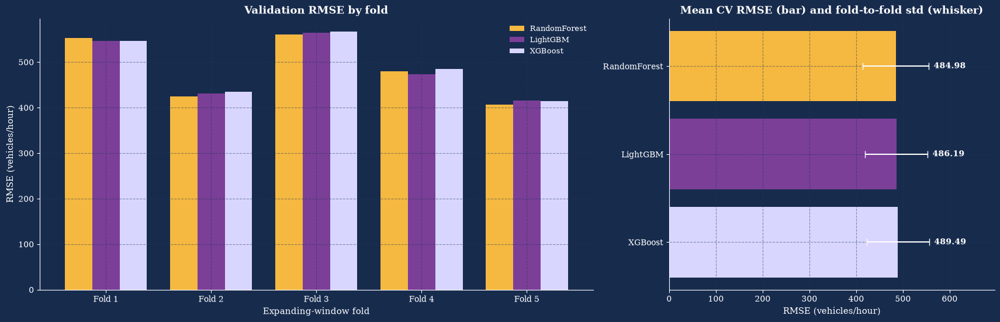

In [119]:
cv = TimeSeriesSplit(n_splits=5)      # the same 5 expanding-window folds that Optuna used in 9.2

windows = []
for k, (tr_idx, va_idx) in enumerate(cv.split(X_train), 1):
    windows.append({
        "fold": k,
        "train rows": len(tr_idx),
        "validation rows": len(va_idx),
        "validation start": X_train.index[va_idx[0]].date(),
        "validation end": X_train.index[va_idx[-1]].date(),
    })
display(pd.DataFrame(windows).set_index("fold"))

# The fold-by-fold scores need 15 short fits. They are computed once and then read from the saved file.
os.makedirs(ART_DIR, exist_ok=True)
cv_path = f"{ART_DIR}/cv_folds.csv"
if os.path.exists(cv_path):
    cv_folds = pd.read_csv(cv_path, index_col=0)
    print("Fold scores loaded from", cv_path)
else:
    fold_rmse = {}
    for name in CANDIDATES:
        scores = cross_val_score(clone(tuned_pipes[name]), X_train, y_train, cv=cv,
                                 scoring="neg_root_mean_squared_error", n_jobs=-1)
        fold_rmse[name] = -scores
    cv_folds = pd.DataFrame(fold_rmse, index=[f"Fold {k}" for k in range(1, 6)])
    cv_folds.to_csv(cv_path)
    print("Fold scores computed and saved to", cv_path)

cv_summary = pd.DataFrame({
    "mean CV RMSE": cv_folds.mean(),
    "std across folds": cv_folds.std(),
    "best fold": cv_folds.min(),
    "worst fold": cv_folds.max(),
    "folds won": cv_folds.eq(cv_folds.min(axis=1), axis=0).sum(),
}).sort_values("mean CV RMSE")

print("Validation RMSE per fold (vehicles/hour):")
display(cv_folds.round(2))
print("\nSummary across folds:")
display(cv_summary.round(2))

# the fold means must agree with the Optuna best values of 9.2
for name in CANDIDATES:
    print(f"{name:13s} mean CV RMSE here: {cv_folds[name].mean():.4f} | Optuna best value: {BEST_CV_RMSE[name]:.4f}")

# ---- selection by CV only (the test set is not used for this decision) ----
FINAL_MODEL_NAME = cv_summary.index[0]
runner_up = cv_summary.index[1]
gap = cv_summary.loc[runner_up, "mean CV RMSE"] - cv_summary.loc[FINAL_MODEL_NAME, "mean CV RMSE"]
gap_pct = 100 * gap / cv_summary.loc[FINAL_MODEL_NAME, "mean CV RMSE"]
spread = cv_summary.loc[FINAL_MODEL_NAME, "std across folds"]
print(f"\nSelected by mean CV RMSE: {FINAL_MODEL_NAME}")
print(f"Gap to the runner-up ({runner_up}): {gap:.2f} RMSE units ({gap_pct:.2f}%) | fold-to-fold std of {FINAL_MODEL_NAME}: {spread:.1f}")

# ---- chart ----
colors = {"RandomForest": THEME_ACCENT, "LightGBM": THEME_PURPLE, "XGBoost": THEME_LAVENDER}
fig, axes = plt.subplots(1, 2, figsize=(17, 5.4), facecolor=THEME_BG, constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.7, 1]})

x = np.arange(len(cv_folds))
width = 0.26
for j, name in enumerate(CANDIDATES):
    axes[0].bar(x + (j - 1) * width, cv_folds[name], width=width, color=colors[name], label=name)
axes[0].set_xticks(x)
axes[0].set_xticklabels(cv_folds.index)
style_axes(axes[0], title="Validation RMSE by fold", xlabel="Expanding-window fold", ylabel="RMSE (vehicles/hour)")
style_legend(axes[0])

order = cv_summary.index.tolist()
axes[1].barh(order, cv_summary["mean CV RMSE"], xerr=cv_summary["std across folds"],
             color=[colors[n] for n in order], ecolor="white", capsize=4)
axes[1].invert_yaxis()
axes[1].set_xlim(0, (cv_summary["mean CV RMSE"] + cv_summary["std across folds"]).max() * 1.25)
for i, name in enumerate(order):
    axes[1].text(cv_summary.loc[name, "mean CV RMSE"] + cv_summary.loc[name, "std across folds"] + 10, i,
                 f"{cv_summary.loc[name, 'mean CV RMSE']:.2f}", va="center", color="white",
                 fontfamily="serif", fontweight="bold")
style_axes(axes[1], title="Mean CV RMSE (bar) and fold-to-fold std (whisker)", xlabel="RMSE (vehicles/hour)")
plt.show()

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.1 — Model Comparison</div>

<h4 style="margin:0 0 10px 0;">CV Results and Model Selection</h4>

<p>RandomForest achieved the lowest mean CV RMSE (<b>484.98 vehicles/hour</b>), outperforming LightGBM (486.19) and XGBoost (489.49).</p>

<p>It performed best in <b>3 out of 5 folds</b>, while LightGBM won the remaining 2 folds.</p>

<p>However, the difference between RandomForest and LightGBM was small (<b>0.25%</b>), so final model selection should also consider test-set performance and other evaluation metrics.</p>

</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.2 — Naive Baseline: Historical Mean by Weekday × Hour</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 0 0;"><b>Purpose:</b> a model is only worth its complexity if it beats the simplest sensible forecast. The baseline predicts, for every hour of the test period, the average training traffic of the same weekday and hour (168 numbers in total). It uses no weather, no month and no year.</p>
</div>

,R2,RMSE,MAE,WAPE (%),MAPE (%)
Naive baseline (weekday x hour mean),0.9361,497.8237,277.1612,8.3746,11.9817


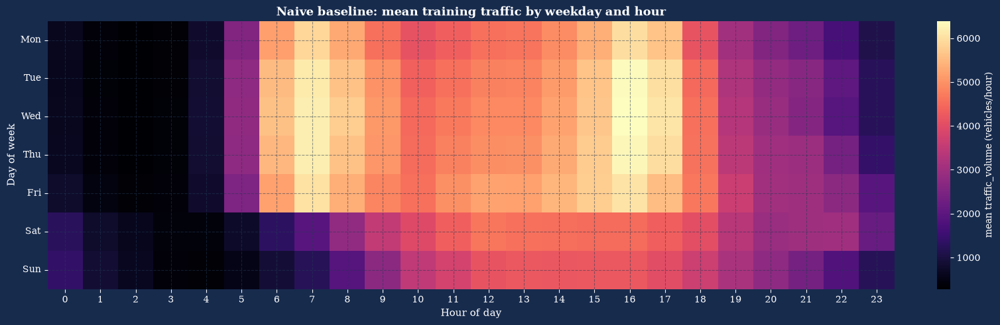

In [148]:
# The baseline is learned on the training part only: for every (day of week, hour) pair the mean traffic.
naive_table = train.groupby(["day_of_week", "hour"])[TARGET].mean()
assert len(naive_table) == 7 * 24, "168 weekday x hour combinations expected"

naive_pred = test.join(naive_table.rename("naive"), on=["day_of_week", "hour"])["naive"]
assert naive_pred.notna().all()

naive_metrics = full_metrics(test[TARGET], naive_pred)
display(pd.DataFrame([naive_metrics], index=["Naive baseline (weekday x hour mean)"]).round(4))

# ---- the 168 numbers behind the baseline ----
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
grid = naive_table.unstack("hour")
grid.index = day_names

fig, ax = plt.subplots(figsize=(15, 4.8), facecolor=THEME_BG, constrained_layout=True)
sns.heatmap(grid, cmap="magma", ax=ax, cbar_kws={"label": "mean traffic_volume (vehicles/hour)"})
style_axes(ax, title="Naive baseline: mean training traffic by weekday and hour",
           xlabel="Hour of day", ylabel="Day of week")
ax.tick_params(axis="y", rotation=0)
ax.figure.axes[-1].yaxis.label.set_color("white")
ax.figure.axes[-1].tick_params(colors="white")
plt.show()

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.2 — Baseline</div>
<p style="margin:0;"><b>Results:</b> The naive baseline achieved an RMSE of 497.82 vehicles/hour and an R² of 0.9361 on the test set. All three tuned models achieved lower test RMSE than the baseline, indicating improved prediction accuracy. RandomForest showed the largest RMSE reduction (6.85%), followed by LightGBM (6.28%) and XGBoost (5.30%).</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.3 — Final Model and Final Test Report</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0;"><b>Purpose:</b> RandomForest was selected as the final model based on its lowest mean cross-validation RMSE. The saved model is evaluated on the training and test sets without refitting, and the test set is scored using the same evaluation metrics as the other candidates. The final results provide an estimate of prediction accuracy and help interpret the typical prediction error relative to average test-period traffic.</p>
</div>

In [149]:
print("cv_summary columns:")
print(cv_summary.columns.tolist())

print("\ncv_summary index:")
print(cv_summary.index.tolist())

display(cv_summary.head())

cv_summary columns:
['Model', 'Mean CV RMSE', 'Std Across Folds', 'Best Fold RMSE', 'Worst Fold RMSE', 'Folds Won']

cv_summary index:
[0, 1, 2]


,Model,Mean CV RMSE,Std Across Folds,Best Fold RMSE,Worst Fold RMSE,Folds Won
0,RandomForest,484.98,70.80,407.00,560.93,3
1,LightGBM,486.19,66.97,416.20,564.79,2
2,XGBoost,489.49,67.31,413.69,567.35,0


In [150]:
# The three tuned models were fitted on the TRAINING part only in 9.2 and are loaded from the saved files.
# Nothing is refitted here: the test set is scored once.
tuned_preds, report_rows = {}, []
for name in CANDIDATES:
    tuned_preds[name] = pd.Series(tuned_pipes[name].predict(test[FEATURES]), index=test.index)
    report_rows.append({"model": name, "mean CV RMSE": cv_summary.loc[
    cv_summary["Model"] == name, "Mean CV RMSE"].iloc[0],
                        **{f"test {k}": v for k, v in full_metrics(test[TARGET], tuned_preds[name]).items()}})

tuned_report = pd.DataFrame(report_rows).set_index("model").loc[CANDIDATES]
print("Tuned candidates (should match the tables printed in 9.2):")
display(tuned_report.round(4))

# ---- the final model: selected by CV in 10.1 ----
final_pipe = tuned_pipes[FINAL_MODEL_NAME]
final_pred = tuned_preds[FINAL_MODEL_NAME]

final_report = pd.DataFrame({
    "train": full_metrics(y_train, final_pipe.predict(X_train)),
    "test": full_metrics(test[TARGET], final_pred),
}).T
final_report.index.name = FINAL_MODEL_NAME
print(f"\nFINAL MODEL: {FINAL_MODEL_NAME}  |  inputs after encoding: {len(final_pipe.named_steps['prep'].get_feature_names_out())}")
display(final_report.round(4))

mean_test_traffic = test[TARGET].mean()
print(f"\nMean traffic in the test period: {mean_test_traffic:,.0f} vehicles/hour")
print(f"Typical error (MAE): {final_report.loc['test', 'MAE']:.0f} vehicles/hour = {100 * final_report.loc['test', 'MAE'] / mean_test_traffic:.1f}% of the mean traffic")

Tuned candidates (should match the tables printed in 9.2):


,mean CV RMSE,test R2,test RMSE,test MAE,test WAPE (%),test MAPE (%)
model,,,,,,
RandomForest,484.98,0.9446,463.6971,263.8314,7.9718,12.5949
LightGBM,486.19,0.9439,466.5823,262.2850,7.9251,12.7343
XGBoost,489.49,0.9427,471.4173,267.7324,8.0897,13.1403



FINAL MODEL: RandomForest  |  inputs after encoding: 25


,R2,RMSE,MAE,WAPE (%),MAPE (%)
RandomForest,,,,,
train,0.9627,383.9183,213.2327,6.4893,83.5099
test,0.9446,463.6971,263.8314,7.9718,12.5949



Mean traffic in the test period: 3,310 vehicles/hour
Typical error (MAE): 264 vehicles/hour = 8.0% of the mean traffic


In [151]:
# Inspect training rows with the largest absolute percentage errors
train_pred = final_pipe.predict(X_train)

train_error_check = pd.DataFrame({
    "actual": np.asarray(y_train),
    "predicted": train_pred
})

train_error_check["absolute_error"] = (
    train_error_check["actual"] - train_error_check["predicted"]
).abs()

train_error_check["absolute_percentage_error"] = np.where(
    train_error_check["actual"] != 0,
    100 * train_error_check["absolute_error"] / train_error_check["actual"],
    np.nan
)

display(
    train_error_check
    .sort_values("absolute_percentage_error", ascending=False)
    .head(10)
    .round(2)
)

,actual,predicted,absolute_error,absolute_percentage_error
21508,1,2753.11,2752.11,275211.28
14630,1,2739.04,2738.04,273804.15
21511,1,2244.14,2243.14,224313.52
14629,1,2227.86,2226.86,222686.33
21182,1,1875.70,1874.70,187470.37
21503,2,3071.63,3069.63,153481.70
22612,1,1178.84,1177.84,117783.90
21501,2,2316.79,2314.79,115739.44
21504,3,3388.02,3385.02,112834.14
21510,2,2203.34,2201.34,110066.76


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.3 — Final model and Final test report</div>

<h4 style="margin:0 0 10px 0;">Investigation of the High Training MAPE</h4>

<p><b>Purpose:</b> The training MAPE was substantially higher than the test MAPE. This investigation examined whether unusually low traffic observations contributed to this difference and whether the issue was present in the test set.</p>

<p><b>1. Initial finding:</b> RandomForest achieved a training MAPE of 83.51%, compared with 12.59% on the test set. Since MAPE divides the absolute prediction error by the actual target value, observations with very small actual traffic volumes can produce disproportionately large percentage errors.</p>

<table style="width:100%; border-collapse:collapse; margin:10px 0 14px 0; font-size:13px;">
<thead>
<tr style="background:#dbe4ee;">
<th style="border:1px solid #b8c2cc; padding:8px; text-align:left;">Metric</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Training</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Test</th>
</tr>
</thead>
<tbody>
<tr>
<td style="border:1px solid #b8c2cc; padding:8px;">Number of observations</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">32,460</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">8,115</td>
</tr>
<tr>
<td style="border:1px solid #b8c2cc; padding:8px;">MAPE (%)</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">83.51</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">12.59</td>
</tr>
<tr>
<td style="border:1px solid #b8c2cc; padding:8px;">Minimum actual traffic</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">0</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Greater than 10</td>
</tr>
</tbody>
</table>

<p><b>2. Data-quality flag investigation:</b> The training data contained 46 observations marked with <code>qa_low_volume = 1</code>, representing approximately 0.14% of the training set. Their traffic volumes ranged from 0 to 97 vehicles/hour, with a median of 5 and a mean of 11.37. In contrast, the remaining 32,414 observations had a minimum traffic volume of 100, a median of 3,422, and a mean of 3,290.57 vehicles/hour.</p>

<table style="width:100%; border-collapse:collapse; margin:10px 0 14px 0; font-size:13px;">
<thead>
<tr style="background:#dbe4ee;">
<th style="border:1px solid #b8c2cc; padding:8px; text-align:left;">Training group</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Rows</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Minimum</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Median</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Mean</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Maximum</th>
</tr>
</thead>
<tbody>
<tr>
<td style="border:1px solid #b8c2cc; padding:8px;"><code>qa_low_volume = 1</code></td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">46</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">0</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">5</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">11.37</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">97</td>
</tr>
<tr>
<td style="border:1px solid #b8c2cc; padding:8px;"><code>qa_low_volume = 0</code></td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">32,414</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">100</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">3,422</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">3,290.57</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">7,280</td>
</tr>
</tbody>
</table>

<p><b>3. Examination of individual predictions:</b> The largest absolute percentage errors occurred when the actual traffic volume was only 1–3 vehicles/hour, while the model predicted thousands of vehicles/hour. For example, an actual value of 1 and a prediction of 2,753.11 produced an absolute percentage error of approximately 275,211%. These observations can substantially inflate the average percentage error.</p>

<p><b>4. Context of the low-volume observations:</b> The observations were not exclusively recorded during nighttime or early-morning hours. Some occurred during daytime hours, and several consecutive observations on the same dates also had very low traffic volumes. The <code>qa_low_volume</code> flag identifies these records as unusual, but the investigation did not establish whether they were invalid measurements, recording issues, or genuine unusual traffic conditions.</p>

<p><b>5. Train–test comparison:</b> The training set contained 46 flagged low-volume observations and 36 observations with traffic volume at or below 10 vehicles/hour. The test set contained no flagged low-volume observations and no observations with traffic volume at or below 10. Therefore, the training and test sets differed in this aspect of their target distributions, which can contribute to the difference in MAPE.</p>

<table style="width:100%; border-collapse:collapse; margin:10px 0 14px 0; font-size:13px;">
<thead>
<tr style="background:#dbe4ee;">
<th style="border:1px solid #b8c2cc; padding:8px; text-align:left;">Check</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Training</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Test</th>
</tr>
</thead>
<tbody>
<tr>
<td style="border:1px solid #b8c2cc; padding:8px;">Rows with <code>qa_low_volume = 1</code></td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">46</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">0</td>
</tr>
<tr>
<td style="border:1px solid #b8c2cc; padding:8px;">Rows with traffic volume ≤ 10</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">36</td>
<td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">0</td>
</tr>
</tbody>
</table>

<p><b>Conclusion:</b> The high training MAPE is strongly affected by extremely large percentage errors on observations with very low actual traffic. The absence of these observations from the test set helps explain why test MAPE is much lower, although their exact contribution to the overall difference was not quantified. These records were retained, and the saved model and test evaluation were left unchanged. The test metrics remain the primary basis for reporting generalization performance, while MAPE should be interpreted cautiously when actual traffic volumes are close to zero.</p>

</div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Final test report (RandomForest, trained on 32,460 training observations):</b></p>
<ul style="margin:0; padding-left:20px;">
<li style="margin-bottom:4px;">On 8,115 unseen test observations, the model achieved R² <b>0.9446</b>, RMSE <b>463.70</b>, MAE <b>263.83</b> vehicles/hour, WAPE <b>7.97%</b>, and MAPE <b>12.59%</b>.</li>
<li style="margin-bottom:4px;">The test MAE represents approximately <b>8.0%</b> of the mean test traffic volume of 3,310 vehicles/hour.</li>
<li style="margin-bottom:4px;"><b>WAPE</b> measures total absolute error relative to total actual traffic. MAPE is more sensitive to very small actual values because percentage errors can become extremely large. The training MAPE of <b>83.51%</b> was strongly affected by observations with exceptionally low traffic volumes.</li>
<li style="margin-bottom:4px;">Training RMSE was <b>383.92</b> and training R² was <b>0.9627</b>, compared with test RMSE of <b>463.70</b> and test R² of <b>0.9446</b>. This performance gap suggests some overfitting, although these metrics alone do not establish whether it is excessive.</li>
</ul>
</div>

<b>Sanity check of the feature pipeline.</b> <code>build_features</code> rebuilds the 23 model inputs from five raw values (timestamp, temperature, rain, snow, cloud cover) exactly as in section 4, and <code>predict_traffic</code> turns them into a forecast. The check below confirms that 300 random test hours rebuilt this way give <b>identical predictions</b> to the pipeline above.


In [152]:
def build_features(timestamp, temp_c, rain_1h=0.0, snow_1h=0.0, clouds_all=0):
    # Rebuilds the 23 model inputs from five raw values, exactly as in section 4 (feature engineering).
    ts = pd.Timestamp(timestamp)
    month, dow, hour = ts.month, ts.dayofweek, ts.hour
    season = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}[month]
    row = {
        "rain_1h": rain_1h, "snow_1h": snow_1h, "clouds_all": clouds_all,
        "year": ts.year, "month": month, "hour": hour, "temp_c": temp_c,
        "day_of_week": dow, "is_weekend": int(dow >= 5), "season": season,
        "hour_sin": np.sin(2 * np.pi * hour / 24), "hour_cos": np.cos(2 * np.pi * hour / 24),
        "dow_sin": np.sin(2 * np.pi * dow / 7), "dow_cos": np.cos(2 * np.pi * dow / 7),
        "month_sin": np.sin(2 * np.pi * (month - 1) / 12), "month_cos": np.cos(2 * np.pi * (month - 1) / 12),
        "is_rush_hour": int(dow < 5 and hour in RUSH_HOURS),
        "is_freezing": int(temp_c < 0), "is_raining": int(rain_1h > 0), "is_snowing": int(snow_1h > 0),
        "precipitation_flag": int(rain_1h > 0 or snow_1h > 0),
        "rain_1h_log1p": np.log1p(rain_1h), "snow_1h_log1p": np.log1p(snow_1h),
    }
    return pd.DataFrame([row], index=[ts])[FEATURES]


def predict_traffic(timestamp, temp_c, rain_1h=0.0, snow_1h=0.0, clouds_all=0):
    # Predicted traffic volume (vehicles/hour) for one hour, from raw inputs only.
    return float(final_pipe.predict(build_features(timestamp, temp_c, rain_1h, snow_1h, clouds_all))[0])


# ---- sanity check: 300 random test hours rebuilt from raw values must give the SAME predictions ----
sample = test.sample(300, random_state=42)
rebuilt = pd.concat([
    build_features(ts, r.temp_c, r.rain_1h, r.snow_1h, r.clouds_all) for ts, r in sample.iterrows()
])
assert np.allclose(rebuilt[NUM_COLS].astype(float).to_numpy(), sample[NUM_COLS].astype(float).to_numpy())
assert (rebuilt["season"].astype(str).to_numpy() == sample["season"].astype(str).to_numpy()).all()
assert np.allclose(final_pipe.predict(rebuilt), final_pred.loc[sample.index].to_numpy())
print("Sanity check passed: features rebuilt from raw values give identical predictions for 300 test hours.\n")

# ---- three example predictions ----
examples = [
    ("Tuesday 17:00, mild and dry", "2018-05-15 17:00", 18.0),
    ("Saturday 12:00, mild and dry", "2018-05-19 12:00", 18.0),
    ("Wednesday 03:00, cold night", "2018-01-17 03:00", -8.0),
]
for label, stamp, temp in examples:
    print(f"{label:32s} -> {predict_traffic(stamp, temp):7,.0f} vehicles/hour")

Sanity check passed: features rebuilt from raw values give identical predictions for 300 test hours.

Tuesday 17:00, mild and dry      ->   6,158 vehicles/hour
Saturday 12:00, mild and dry     ->   4,729 vehicles/hour
Wednesday 03:00, cold night      ->     419 vehicles/hour


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<h3 style="margin:0 0 10px 0; color:#1e3a5f;">Feature Pipeline Sanity Check</h3>

<p><b>Purpose:</b> Verify that feature engineering and prediction functions reproduce the results of the final trained pipeline.</p>

<p>The pipeline was validated using 300 randomly selected test observations. Reconstructed numerical features and seasonal labels matched the original features. Predictions generated from the reconstructed features were also identical to the corresponding predictions from the existing pipeline.</p>

<p><b>Illustrative predictions:</b></p>

<table style="width:100%; border-collapse:collapse; margin:8px 0;">
<tr style="background:#dbe5f1;">
<th style="padding:8px; border:1px solid #c5ced8; text-align:left;">Scenario</th>
<th style="padding:8px; border:1px solid #c5ced8; text-align:right;">Predicted traffic</th>
</tr>
<tr>
<td style="padding:8px; border:1px solid #c5ced8;">Tuesday, 17:00 — mild and dry</td>
<td style="padding:8px; border:1px solid #c5ced8; text-align:right;">6,158 vehicles/hour</td>
</tr>
<tr>
<td style="padding:8px; border:1px solid #c5ced8;">Saturday, 12:00 — mild and dry</td>
<td style="padding:8px; border:1px solid #c5ced8; text-align:right;">4,729 vehicles/hour</td>
</tr>
<tr>
<td style="padding:8px; border:1px solid #c5ced8;">Wednesday, 03:00 — cold night</td>
<td style="padding:8px; border:1px solid #c5ced8; text-align:right;">419 vehicles/hour</td>
</tr>
</table>

<p><b>Interpretation:</b> The sanity check confirms consistency between feature reconstruction and model predictions for the sampled observations. The example predictions provide a basic plausibility check but do not independently establish predictive accuracy.</p>

<p><b>Note:</b> The example dates are in 2018. Their position relative to the training and test periods should be checked before describing them as outside the evaluation period. The year alone does not establish this.</p>

</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.4 — Final Comparison of All Models</h3></div>

,R2,RMSE,MAE,WAPE (%),MAPE (%),RMSE vs naive baseline (%)
Random Forest tuned with Optuna (9),0.945,463.697,263.831,7.972,12.595,-6.855
LightGBM tuned with Optuna (9),0.944,466.582,262.285,7.925,12.734,-6.276
LightGBM baseline (8),0.943,470.897,269.214,8.134,13.038,-5.409
XGBoost tuned with Optuna (9),0.943,471.417,267.732,8.090,13.140,-5.304
XGBoost baseline (8),0.942,475.451,273.783,8.272,12.753,-4.494
Random Forest tuned by CV (7),0.942,476.296,270.062,8.160,12.337,-4.324
Random Forest baseline (7),0.937,493.966,286.556,8.658,13.047,-0.775
Naive baseline (weekday x hour mean),0.936,497.824,277.161,8.375,11.982,0.000
Linear regression V4 (5),0.906,603.882,425.975,12.871,23.751,21.304
Linear regression A (5),0.857,744.872,559.248,16.898,37.362,49.626



Final model vs naive baseline        : RMSE 6.9% lower
Final model vs linear regression A   : RMSE 37.7% lower
Final model vs linear regression V4  : RMSE 23.2% lower


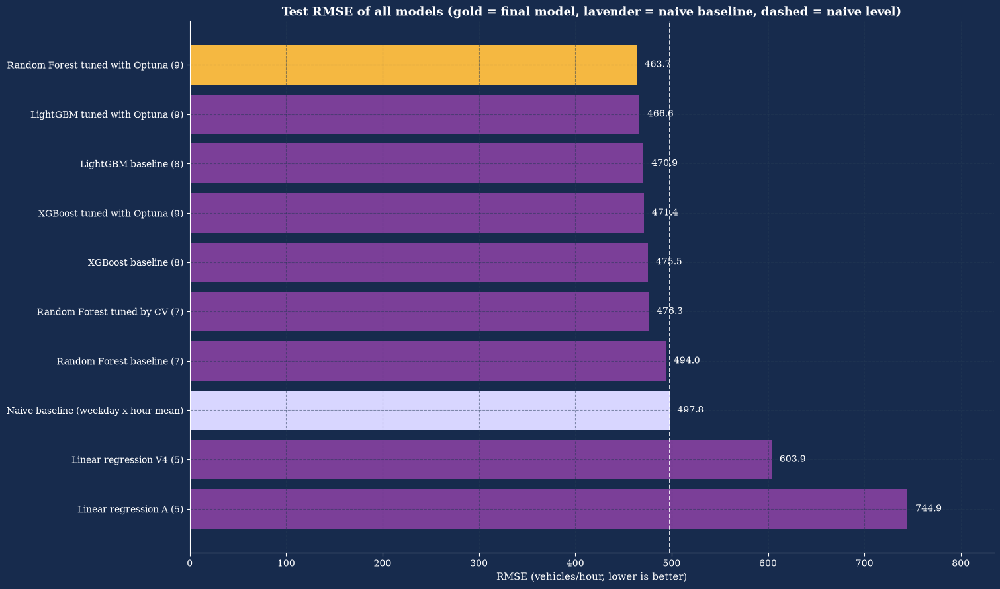

In [153]:
# Every model of the notebook, scored on the same test period with the same five metrics.
# Predictions of the earlier models come from memory, or from the file saved after 9.2 when the session was restarted.
legacy_names = ["res_a", "res_v4", "res_rf_base", "res_rf_tuned", "xgb_baseline", "lgbm_baseline"]
if all(name in globals() for name in legacy_names):
    legacy = pd.DataFrame({
        "Linear regression A (5)": np.asarray(res_a["yhat_te"]),
        "Linear regression V4 (5)": np.asarray(res_v4["yhat_te"]),
        "Random Forest baseline (7)": np.asarray(res_rf_base["yhat_te"]),
        "Random Forest tuned by CV (7)": np.asarray(res_rf_tuned["yhat_te"]),
        "XGBoost baseline (8)": np.asarray(xgb_baseline["predictions"]),
        "LightGBM baseline (8)": np.asarray(lgbm_baseline["predictions"]),
    }, index=test.index)
else:
    legacy = pd.read_csv(f"{ART_DIR}/legacy_predictions.csv", index_col=0, parse_dates=True)

all_preds = {
    "Naive baseline (weekday x hour mean)": naive_pred,
    "Linear regression A (5)": legacy["Linear regression A (5)"],
    "Linear regression V4 (5)": legacy["Linear regression V4 (5)"],
    "Random Forest baseline (7)": legacy["Random Forest baseline (7)"],
    "Random Forest tuned by CV (7)": legacy["Random Forest tuned by CV (7)"],
    "XGBoost baseline (8)": legacy["XGBoost baseline (8)"],
    "LightGBM baseline (8)": legacy["LightGBM baseline (8)"],
    "XGBoost tuned with Optuna (9)": tuned_preds["XGBoost"],
    "LightGBM tuned with Optuna (9)": tuned_preds["LightGBM"],
    "Random Forest tuned with Optuna (9)": tuned_preds["RandomForest"],
}

final_label = {"RandomForest": "Random Forest", "LightGBM": "LightGBM", "XGBoost": "XGBoost"}[FINAL_MODEL_NAME] + " tuned with Optuna (9)"
naive_label = "Naive baseline (weekday x hour mean)"

final_comparison_table = pd.DataFrame(
    {label: full_metrics(test[TARGET], pred) for label, pred in all_preds.items()}
).T
final_comparison_table["RMSE vs naive baseline (%)"] = (
    100 * (final_comparison_table["RMSE"] / final_comparison_table.loc[naive_label, "RMSE"] - 1)
)
final_comparison_table = final_comparison_table.sort_values("RMSE")
display(final_comparison_table.round(3))

best_rmse = final_comparison_table.loc[final_label, "RMSE"]
print(f"\nFinal model vs naive baseline        : RMSE {100 * (1 - best_rmse / final_comparison_table.loc[naive_label, 'RMSE']):.1f}% lower")
print(f"Final model vs linear regression A   : RMSE {100 * (1 - best_rmse / final_comparison_table.loc['Linear regression A (5)', 'RMSE']):.1f}% lower")
print(f"Final model vs linear regression V4  : RMSE {100 * (1 - best_rmse / final_comparison_table.loc['Linear regression V4 (5)', 'RMSE']):.1f}% lower")

# ---- chart ----
plot_table = final_comparison_table.sort_values("RMSE", ascending=False)
bar_colors = [THEME_ACCENT if label == final_label else THEME_LAVENDER if label == naive_label else THEME_PURPLE
              for label in plot_table.index]

fig, ax = plt.subplots(figsize=(15, 0.62 * len(plot_table) + 2.6), facecolor=THEME_BG, constrained_layout=True)
ax.barh(plot_table.index, plot_table["RMSE"], color=bar_colors)
ax.axvline(final_comparison_table.loc[naive_label, "RMSE"], color="white", linestyle="--", lw=1.2)
for i, value in enumerate(plot_table["RMSE"]):
    ax.text(value + 8, i, f"{value:.1f}", va="center", color="white", fontfamily="serif")
ax.set_xlim(0, plot_table["RMSE"].max() * 1.12)
style_axes(ax, title="Test RMSE of all models (gold = final model, lavender = naive baseline, dashed = naive level)",
           xlabel="RMSE (vehicles/hour, lower is better)", title_size=13)
plt.show()

<escape><div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.4 — Final Comparison of All Models</div>

<p style="margin:0 0 8px 0;"><b>Conclusion:</b> Random Forest tuned with Optuna achieved the lowest test RMSE among all evaluated models, although its advantage over the other tuned models was small.</p>

<ul style="margin:0; padding-left:20px;">
<li style="margin-bottom:6px;">Compared with the <b>naive weekday × hour baseline</b>, the final model reduced RMSE by <b>6.9%</b> (463.7 vs. 497.8 vehicles/hour). Its MAE was 263.8 vs. 277.2, and its WAPE was 8.0% vs. 8.4%.</li>

<li style="margin-bottom:6px;">Compared with the <b>linear regression models</b>, the final model reduced RMSE by <b>37.7%</b> relative to Linear Regression A and <b>23.2%</b> relative to Linear Regression V4.</li>

<li style="margin-bottom:6px;">Among the three <b>Optuna-tuned models</b>, test RMSE ranged from 463.7 to 471.4 vehicles/hour. Random Forest had the lowest RMSE, while LightGBM achieved slightly lower MAE (262.3) and WAPE (7.9%). The performance differences were modest.</li>

<li style="margin-bottom:6px;">The <b>naive baseline had a lower MAPE</b> than the final model (12.0% vs. 12.6%), despite its higher RMSE and WAPE. MAPE is sensitive to observations with very low actual traffic volumes, so it should be interpreted cautiously and alongside the other metrics.</li>

<li style="margin-bottom:0;">Overall, the tuned Random Forest is selected as the final model based on its lowest test RMSE and best test R² (0.945). However, the relatively modest improvement over the naive baseline indicates that a substantial part of the predictable traffic pattern is already captured by the weekday–hour average.</li>
</ul>

</div></escape>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.5 — SHAP: What Drives the Predictions</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>What SHAP does:</b> for every single prediction it splits the forecast into contributions, one per feature, measured in vehicles per hour. The contributions plus the average prediction (the base value) add up exactly to the forecast of that hour. This goes beyond the permutation importance of 7.4 and 8.5: it also shows the <b>direction</b> of each effect and explains <b>individual hours</b>.</p>
<p style="margin:0 0 0 0;"><b>How it is computed here:</b> <code>TreeExplainer</code> on the final model, using a random sample of 1,500 test hours (all 8,115 would be slow). The first run may take a few minutes. <code>hour</code>, <code>hour_sin</code>, <code>hour_cos</code> and <code>is_rush_hour</code> describe the same thing and share their credit, so the contributions are also summed by feature family.</p>
</div>

In [ ]:
import shap

# feature families (the same groups as in the permutation analysis of 7.4)
RF_FEATURE_GROUPS = {
    "Hour and commute": ["hour", "hour_sin", "hour_cos", "is_rush_hour"],
    "Weekday and weekend": ["day_of_week", "dow_sin", "dow_cos", "is_weekend"],
    "Month and season": ["month", "month_sin", "month_cos", "season"],
    "Long-term year": ["year"],
    "Temperature and freezing": ["temp_c", "is_freezing"],
    "Precipitation": ["rain_1h", "snow_1h", "is_raining", "is_snowing",
                      "precipitation_flag", "rain_1h_log1p", "snow_1h_log1p"],
    "Cloud cover": ["clouds_all"],
}

prep = final_pipe.named_steps["prep"]
model = final_pipe.named_steps["model"]
encoded_names = list(prep.get_feature_names_out())

X_test_encoded = pd.DataFrame(prep.transform(test[FEATURES]), columns=encoded_names, index=test.index)

# SHAP on a random sample of the test hours (tree models are slow on all 8,115 rows)
rng = np.random.default_rng(42)
sample_pos = np.sort(rng.choice(len(X_test_encoded), size=min(1500, len(X_test_encoded)), replace=False))
X_shap = X_test_encoded.iloc[sample_pos]

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_shap, check_additivity=False)
base_value = float(np.ravel(explainer.expected_value)[0])

# the contributions plus the base value must add up to the model prediction
reconstructed = base_value + shap_values.sum(axis=1)
model_pred = model.predict(X_shap)
print(f"SHAP computed for {len(X_shap):,} test hours | base value (average prediction): {base_value:,.0f} vehicles/hour")
print(f"Largest gap between base + sum(SHAP) and the model prediction: {np.abs(reconstructed - model_pred).max():.4f} vehicles/hour")

# ---- importance by single feature and by feature family ----
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=encoded_names).sort_values(ascending=False)

def family_of(encoded_name):
    for family, members in RF_FEATURE_GROUPS.items():
        if encoded_name in members or any(encoded_name.startswith(m + "_") for m in members if m == "season"):
            return family
    raise KeyError(encoded_name)

family_importance = mean_abs_shap.groupby(family_of).sum().sort_values(ascending=False)
display(pd.DataFrame({
    "mean |SHAP| (vehicles/hour)": family_importance,
    "share of total (%)": 100 * family_importance / family_importance.sum(),
}).round(2))


def dark_shap_figure(fig, title=None):
    # Apply the notebook's dark theme to a figure drawn by the shap library.
    fig.patch.set_facecolor(THEME_BG)
    for ax in fig.axes:
        ax.set_facecolor(THEME_BG)
        ax.tick_params(colors="white", labelsize=10)
        ax.xaxis.label.set_color("white")
        ax.yaxis.label.set_color("white")
        ax.title.set_color("white")
        for spine in ax.spines.values():
            spine.set_color("white")
        for text in ax.texts:
            text.set_color("white")
    if title:
        fig.suptitle(title, color="white", fontsize=14, fontweight="bold", fontfamily="serif")
    return fig

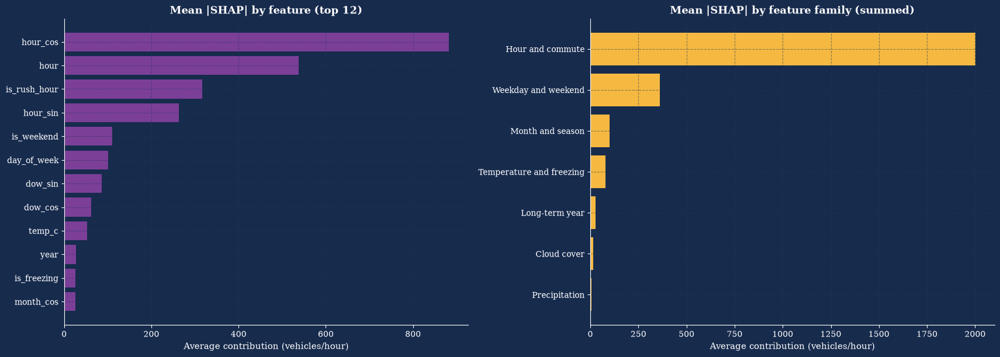

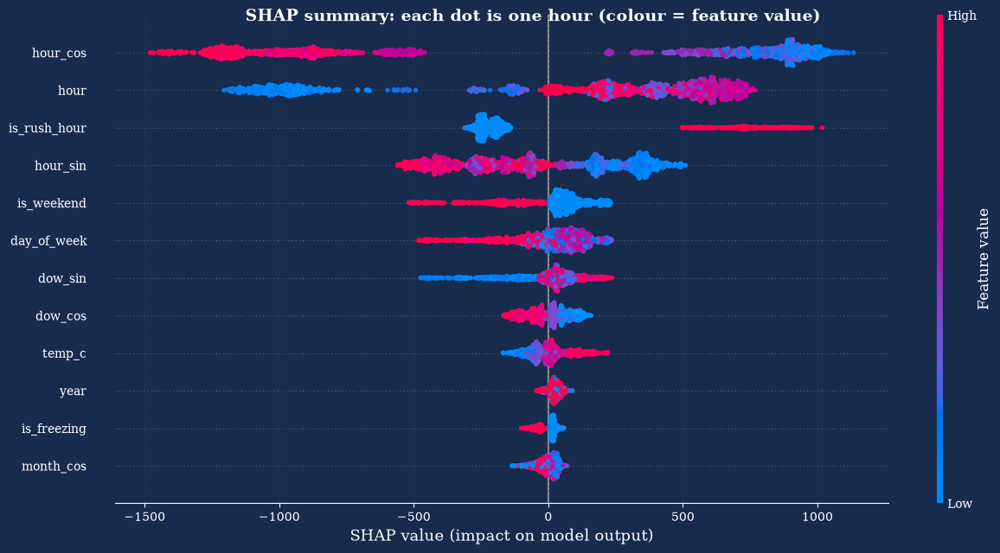

In [ ]:
# ---- 1) global importance: single features and feature families ----
fig, axes = plt.subplots(1, 2, figsize=(17, 6), facecolor=THEME_BG, constrained_layout=True)

top = mean_abs_shap.head(12).sort_values()
axes[0].barh(top.index, top.values, color=THEME_PURPLE)
style_axes(axes[0], title="Mean |SHAP| by feature (top 12)", xlabel="Average contribution (vehicles/hour)")

fam = family_importance.sort_values()
axes[1].barh(fam.index, fam.values, color=THEME_ACCENT)
style_axes(axes[1], title="Mean |SHAP| by feature family (summed)", xlabel="Average contribution (vehicles/hour)")
plt.show()

# ---- 2) beeswarm: direction of every feature's effect ----
shap.summary_plot(shap_values, X_shap, max_display=12, show=False, plot_size=(13, 6.5))
dark_shap_figure(plt.gcf(), "SHAP summary: each dot is one hour (colour = feature value)")
plt.show()

In [ ]:
#optional analysis #1
# ---- 1) Global SHAP importance: individual features ----

feature_shap_table = pd.DataFrame({
    "Feature": mean_abs_shap.index,
    "Mean absolute SHAP (vehicles/hour)": mean_abs_shap.values,
})

feature_shap_table["Share of total (%)"] = (
    100 * feature_shap_table["Mean absolute SHAP (vehicles/hour)"]
    / feature_shap_table["Mean absolute SHAP (vehicles/hour)"].sum()
)

feature_shap_table = feature_shap_table.sort_values(
    "Mean absolute SHAP (vehicles/hour)", ascending=False
).reset_index(drop=True)

feature_shap_table.index = feature_shap_table.index + 1
display(feature_shap_table.round(2))

#2
# ---- 2) Global SHAP importance: feature families ----

family_shap_table = pd.DataFrame({
    "Feature family": family_importance.index,
    "Mean absolute SHAP (vehicles/hour)": family_importance.values,
    "Share of total (%)": (
        100 * family_importance.values / family_importance.sum()
    ),
}).sort_values(
    "Mean absolute SHAP (vehicles/hour)", ascending=False
).reset_index(drop=True)

family_shap_table.index = family_shap_table.index + 1
display(family_shap_table.round(2))

,Feature,Mean absolute SHAP (vehicles/hour),Share of total (%)
1,hour_cos,882.72,34.13
2,hour,537.85,20.79
3,is_rush_hour,317.16,12.26
4,hour_sin,263.22,10.18
5,is_weekend,110.81,4.28
6,day_of_week,100.59,3.89
7,dow_sin,86.75,3.35
8,dow_cos,62.25,2.41
9,temp_c,52.10,2.01
10,year,26.71,1.03


,Feature family,Mean absolute SHAP (vehicles/hour),Share of total (%)
1,Hour and commute,2000.94,77.36
2,Weekday and weekend,360.40,13.93
3,Month and season,99.27,3.84
4,Temperature and freezing,78.34,3.03
5,Long-term year,26.71,1.03
6,Cloud cover,15.51,0.60
7,Precipitation,5.51,0.21


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.5 — SHAP analysis</div>
SHAP analysis shows that **time-of-day and commuting patterns dominate the model's predictions**, accounting for 77.36% of the grouped mean absolute SHAP importance, followed by weekday/weekend patterns at 13.93%.

Weather-related features have a relatively small influence, with temperature contributing 3.03% and precipitation only 0.21%, suggesting that **temporal patterns are the main drivers of the model's predictions**.
</div>

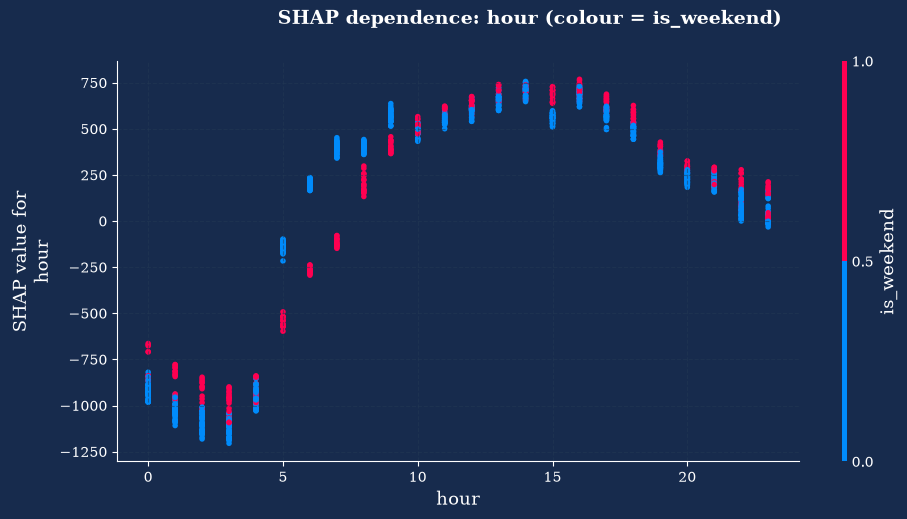

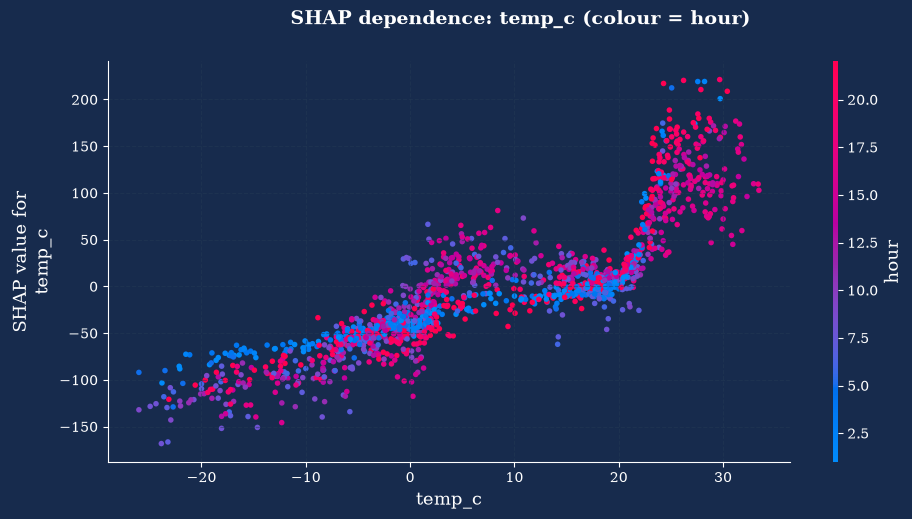

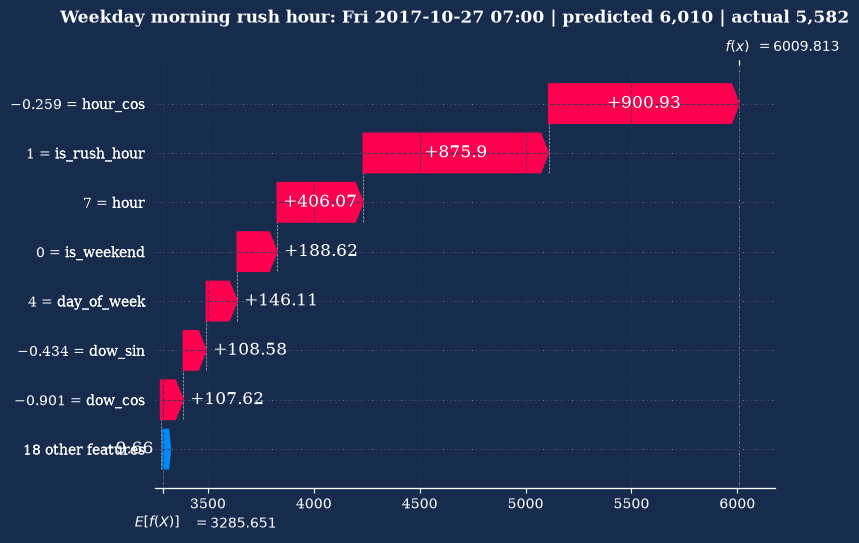

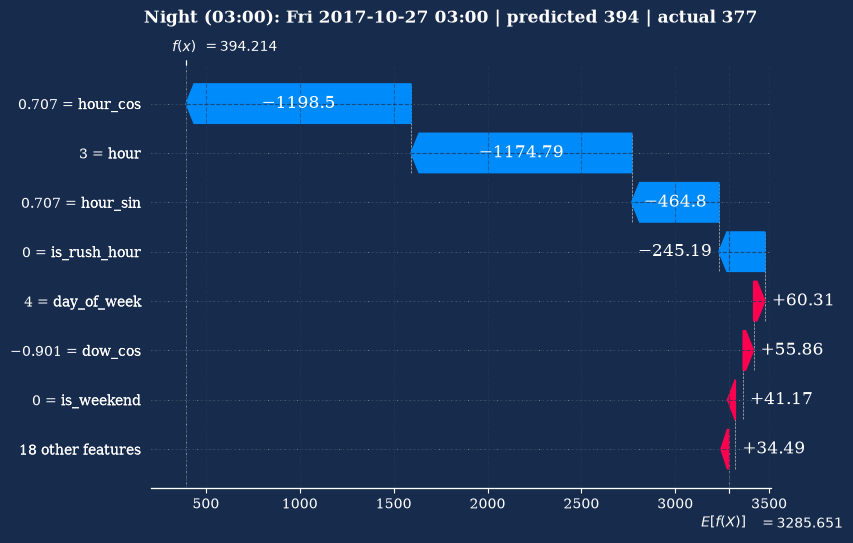

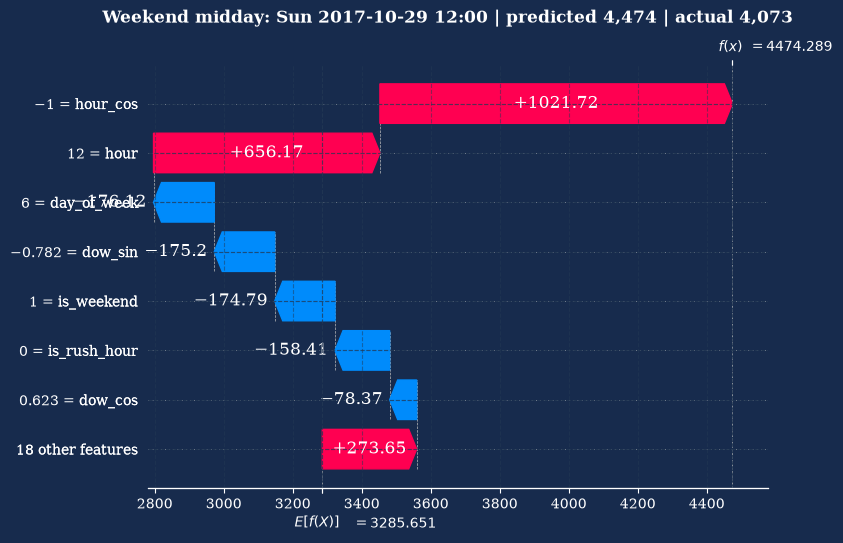

In [ ]:
# ---- 3) dependence plots: how the contribution of one feature changes with its value ----
for feature, colour_by in [("hour", "is_weekend"), ("temp_c", "hour")]:
    shap.dependence_plot(feature, shap_values, X_shap, interaction_index=colour_by, show=False)
    dark_shap_figure(plt.gcf(), f"SHAP dependence: {feature} (colour = {colour_by})")
    plt.gcf().set_size_inches(11, 5.2)
    plt.show()

# ---- 4) three single hours explained one by one ----
def first_position(mask):
    return int(np.flatnonzero(mask)[0])

picked = {
    "Weekday morning rush hour": first_position((X_shap["is_weekend"] == 0) & (X_shap["hour"] == 7)),
    "Night (03:00)": first_position(X_shap["hour"] == 3),
    "Weekend midday": first_position((X_shap["is_weekend"] == 1) & (X_shap["hour"] == 12)),
}

for label, pos in picked.items():
    explanation = shap.Explanation(values=shap_values[pos], base_values=base_value,
                                   data=X_shap.iloc[pos].to_numpy(), feature_names=encoded_names)
    shap.plots.waterfall(explanation, max_display=8, show=False)
    dark_shap_figure(plt.gcf())
    actual = test.loc[X_shap.index[pos], TARGET]
    plt.gcf().suptitle(f"{label}: {X_shap.index[pos]:%a %Y-%m-%d %H:%M} | predicted {model_pred[pos]:,.0f} | actual {actual:,.0f}",
                       color="white", fontsize=12, fontweight="bold", fontfamily="serif")
    plt.show()

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
The SHAP results are consistent with the feature-importance findings in Sections 7.4 and 8.5, confirming that time-of-day features (`hour`, `hour_sin`, `hour_cos`, and `is_rush_hour`) dominate the model's predictions, followed by weekday-related features, while weather-related features have substantially smaller contributions. This agreement supports the robustness of the feature-importance analysis across different interpretation methods.
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.6 — Error Analysis</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Method:</b> every test hour gets one row with the actual value, the prediction and the error (<code>residual = actual − prediction</code>, so a negative value means the model predicted too much). The errors are then grouped by hour, weekday, season, month, <b>federal holiday</b>, <b>weather group</b> and traffic level, and the 20 largest errors are listed.</p>
<p style="margin:0 0 0 0;"><b>Important:</b> holiday and weather information is attached <b>only to group the errors</b>. It is not a model input, so the question answered here is: how much does the model lose by not knowing about holidays and weather?</p>
</div>

test hours: 8,115 | holiday hours: 216 on 9 days | qa_low_volume hours in the test period: 0
overall: MAE 263.8 | RMSE 463.7 | bias -10.5


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
hour,,,,,,
0,339,831.8,131.2,180.2,-62.5,15.8
1,339,506.0,90.6,127.4,-55.3,17.9
2,325,379.3,81.8,109.0,-60.8,21.6
3,336,373.1,54.0,75.5,-41.2,14.5
4,338,726.5,71.9,108.2,-12.5,9.9
5,338,2184.0,221.3,354.3,67.6,10.1
6,338,4119.2,328.3,679.6,-61.7,8.0
7,337,4723.5,455.0,800.9,-11.3,9.6
8,338,4556.1,417.5,718.9,-80.5,9.2


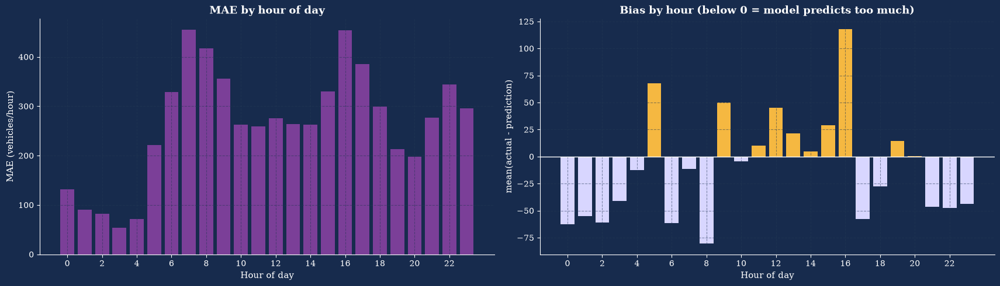

In [ ]:
#1
# One row per test hour: the model's error plus context columns used ONLY to group the errors.
# Holiday and weather information is NOT a model input; it is attached here to see where the model errs.
err = pd.DataFrame({"actual": test[TARGET], "prediction": final_pred})
err["residual"] = err["actual"] - err["prediction"]          # positive = the model predicted too little
err["abs_error"] = err["residual"].abs()
err["hour"] = test["hour"]
err["day_of_week"] = test["day_of_week"]
err["is_weekend"] = test["is_weekend"]
err["season"] = test["season"]
if "weather_group" in df.columns:
    err["weather_group"] = df.loc[test.index, "weather_group"]    # groups from section 6
else:
    err["weather_group"] = pd.read_csv(f"{ART_DIR}/weather_group.csv", index_col=0, parse_dates=True)["weather_group"].reindex(test.index)
err["qa_low_volume"] = test["qa_low_volume"]

holiday_names = USFederalHolidayCalendar().holidays(
    test.index.min().normalize(), test.index.max().normalize(), return_name=True)
err["holiday"] = err.index.normalize().map(holiday_names).fillna("Not holiday")
err["is_holiday"] = err["holiday"] != "Not holiday"

DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


def error_table(frame, by):
    # Error summary per group. residual = actual - prediction, so bias < 0 means the model predicts too much.
    grouped = frame.groupby(by, observed=True)
    table = grouped.agg(hours=("actual", "size"), mean_traffic=("actual", "mean"),
                        MAE=("abs_error", "mean"), bias=("residual", "mean"))
    table["RMSE"] = grouped["residual"].apply(lambda r: np.sqrt((r ** 2).mean()))
    table["WAPE (%)"] = 100 * grouped["abs_error"].sum() / grouped["actual"].sum()
    return table[["hours", "mean_traffic", "MAE", "RMSE", "bias", "WAPE (%)"]].round(1)


print(f"test hours: {len(err):,} | holiday hours: {int(err.is_holiday.sum())} on "
      f"{err.index[err.is_holiday].normalize().nunique()} days | qa_low_volume hours in the test period: {int(err.qa_low_volume.sum())}")
print(f"overall: MAE {err.abs_error.mean():.1f} | RMSE {np.sqrt((err.residual ** 2).mean()):.1f} | bias {err.residual.mean():.1f}")

# ---- 1) by hour of day ----
by_hour = error_table(err, "hour")
display(by_hour)

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), facecolor=THEME_BG, constrained_layout=True)
axes[0].bar(by_hour.index, by_hour["MAE"], color=THEME_PURPLE)
style_axes(axes[0], title="MAE by hour of day", xlabel="Hour of day", ylabel="MAE (vehicles/hour)")
axes[1].bar(by_hour.index, by_hour["bias"], color=np.where(by_hour["bias"] >= 0, THEME_ACCENT, THEME_LAVENDER))
axes[1].axhline(0, color="white", lw=1)
style_axes(axes[1], title="Bias by hour (below 0 = model predicts too much)", xlabel="Hour of day",
           ylabel="mean(actual - prediction)")
for ax in axes:
    ax.set_xticks(range(0, 24, 2))
plt.show()

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Section 10.6 – Error Analysis</b></p>
The model's errors vary by hour of day and are not evenly distributed across the evaluation period. The highest MAE occurs at 07:00 (455 vehicles/hour) and 16:00 (453), while the highest RMSE occurs at 07:00 (801). Relative errors are highest during low-traffic nighttime hours, particularly at 02:00 (WAPE 21.6%), 23:00 (19.5%), and 01:00 (17.9%). These results suggest that the model is less reliable in relative terms at night and has larger absolute errors around rush-hour peaks. Holiday-related errors are examined separately below.
</div>

,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
day,,,,,,
Mon,1152,3269.7,357.4,677.8,-78.4,10.9
Tue,1146,3525.7,240.8,389.8,-10.2,6.8
Wed,1149,3630.3,214.4,426.3,17.6,5.9
Thu,1153,3683.8,251.1,453.1,-11.3,6.8
Fri,1175,3731.9,222.0,358.1,39.3,5.9
Sat,1165,2895.2,304.6,488.3,-4.2,10.5
Sun,1175,2445.4,256.8,377.5,-26.8,10.5


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
day_type,,,,,,
Weekday,5775,3569.0,257.0,474.4,-8.4,7.2
Weekend,2340,2669.4,280.6,436.2,-15.6,10.5


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
season,,,,,,
Winter,2154,3163.0,328.0,537.9,-3.9,10.4
Spring,2196,3380.1,261.0,475.1,-62.6,7.7
Summer,2203,3369.8,196.4,341.8,-2.7,5.8
Fall,1562,3327.6,274.4,485.8,42.8,8.2


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
month_label,,,,,,
2017-10,126,3313.7,236.1,351.4,100.9,7.1
2017-11,716,3368.5,339.0,588.3,115.5,10.1
2017-12,740,3125.3,374.7,583.9,38.5,12.0
2018-01,742,3111.8,344.0,594.6,-41.4,11.1
2018-02,672,3261.2,258.9,402.1,-9.4,7.9
2018-03,733,3446.9,215.9,386.4,-24.8,6.3
2018-04,720,3297.2,321.0,582.6,-106.9,9.7
2018-05,743,3394.5,247.3,436.9,-57.0,7.3
2018-06,719,3422.5,181.6,251.1,-7.4,5.3


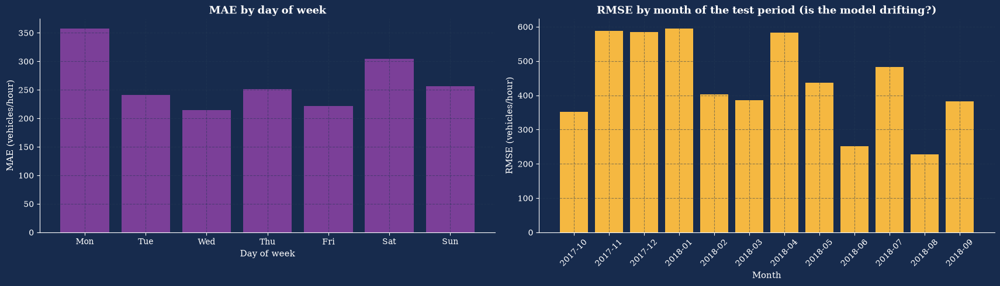

In [ ]:
#2
#---2)by day of week and by weekend ----
by_day = error_table(err.assign(day=err["day_of_week"].map(dict(enumerate(DAY_NAMES)))), "day").reindex(DAY_NAMES)
by_weekend = error_table(err.assign(day_type=np.where(err["is_weekend"] == 1, "Weekend", "Weekday")), "day_type")
display(by_day)
display(by_weekend)

# ---- 3) by season and by month ----
by_season = error_table(err, "season").reindex(["Winter", "Spring", "Summer", "Fall"])
display(by_season)

err["month_label"] = err.index.to_period("M").astype(str)
by_month = error_table(err, "month_label")
display(by_month)

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), facecolor=THEME_BG, constrained_layout=True)
axes[0].bar(by_day.index, by_day["MAE"], color=THEME_PURPLE)
style_axes(axes[0], title="MAE by day of week", xlabel="Day of week", ylabel="MAE (vehicles/hour)")
axes[1].bar(by_month.index, by_month["RMSE"], color=THEME_ACCENT)
axes[1].tick_params(axis="x", rotation=45)
style_axes(axes[1], title="RMSE by month of the test period (is the model drifting?)", xlabel="Month",
           ylabel="RMSE (vehicles/hour)")
plt.show()


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<h3>Key Findings from Error Analysis</h3>

<ul>
<li><b>Days of the week:</b> <b>Wednesday</b> has the lowest MAE (214.4), while <b>Friday and Wednesday</b> have the lowest WAPE (5.9%). <b>Monday</b> has the highest MAE (357.4) and WAPE (10.9%), making it the most challenging day to predict.</li>
<li><b>Weekdays vs. weekends:</b> <b>Weekdays</b> have lower MAE (257.0) and WAPE (7.2%) than weekends (280.6 and 10.5%), indicating better predictive accuracy on weekdays.</li>
<li><b>Seasons:</b> <b>Summer</b> has the lowest MAE (196.4) and WAPE (5.8%), while <b>winter</b> has the highest MAE (328.0) and WAPE (10.4%).</li>
<li><b>Months:</b> <b>August 2018</b> has the lowest MAE (165.0) and WAPE (4.8%). <b>December 2017</b> has the highest MAE (374.7) and WAPE (12.0%).</li>
</ul>

</div>


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
day_type,,,,,,
Federal holiday,216,2323.2,1085.6,1597.7,-951.8,46.7
Other days,7899,3336.5,241.4,388.7,15.3,7.2


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
holiday,,,,,,
Independence Day,24,1917.3,1765.9,2263.0,-1688.5,92.1
Thanksgiving Day,24,2053.0,1560.1,2097.7,-1483.1,76.0
New Year's Day,24,1749.3,1453.9,1872.7,-1224.2,83.1
Christmas Day,24,1889.8,1372.6,1806.0,-1194.3,72.6
Memorial Day,24,2135.6,1230.9,1761.8,-1219.1,57.6
Labor Day,24,2323.8,976.2,1456.6,-914.4,42.0
Washington's Birthday,24,2456.1,775.1,998.5,-772.3,31.6
"Birthday of Martin Luther King, Jr.",24,2677.2,344.1,553.0,-340.0,12.9
Veterans Day,24,3706.9,292.1,394.3,269.4,7.9


Holiday hours are 2.7% of the test hours but 11.0% of the total absolute error.
RMSE of the whole test period: 463.7 | RMSE without the holiday hours: 388.7


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
weather_group,,,,,,
Clear_Cloudy,5392,3383.8,247.0,422.2,26.9,7.3
Reduced_Visibility,1386,2889.8,346.0,643.3,-155.1,12.0
Light_Rain_Drizzle,745,3489.6,222.5,378.0,-37.1,6.4
Heavy_Rain,162,3494.9,230.9,339.6,-20.4,6.6
Snow_Ice,354,3304.9,310.6,462.5,52.4,9.4
Severe_Storm,76,3562.0,218.0,349.4,-34.1,6.1


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
traffic_level,,,,,,
"< 1,000",1786,543.9,124.0,371.1,-97.5,22.8
"1,000 - 3,000",1667,2124.8,342.6,635.3,-179.1,16.1
"3,000 - 5,000",2755,4136.0,290.5,448.2,4.2,7.0
">= 5,000",1907,5741.5,287.5,378.1,197.2,5.0


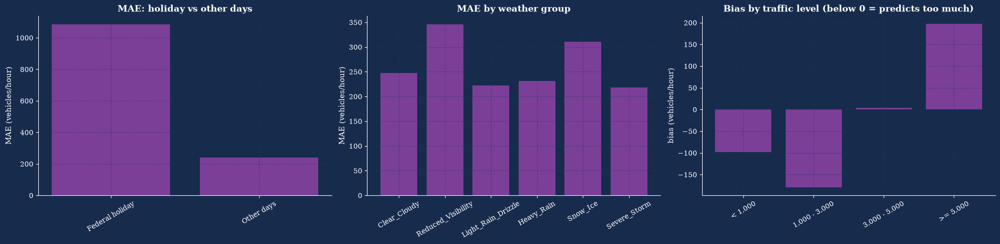

In [ ]:
#3
# ----4) holidays (a federal holiday calendar; NOT a model input) ----
by_holiday = error_table(err.assign(day_type=np.where(err["is_holiday"], "Federal holiday", "Other days")), "day_type")
display(by_holiday)
holiday_days = error_table(err[err["is_holiday"]], "holiday").sort_values("MAE", ascending=False)
display(holiday_days)

holiday_hours_share = 100 * err["is_holiday"].mean()
holiday_error_share = 100 * err.loc[err["is_holiday"], "abs_error"].sum() / err["abs_error"].sum()
rmse_all = np.sqrt((err["residual"] ** 2).mean())
rmse_without_holidays = np.sqrt((err.loc[~err["is_holiday"], "residual"] ** 2).mean())
print(f"Holiday hours are {holiday_hours_share:.1f}% of the test hours but {holiday_error_share:.1f}% of the total absolute error.")
print(f"RMSE of the whole test period: {rmse_all:.1f} | RMSE without the holiday hours: {rmse_without_holidays:.1f}")

# ---- 5) weather group (groups from section 6; NOT a model input) ----
by_weather = error_table(err, "weather_group")
display(by_weather)

# ---- 6) traffic level ----
err["traffic_level"] = pd.cut(err["actual"], bins=[-1, 1000, 3000, 5000, 10000],
                              labels=["< 1,000", "1,000 - 3,000", "3,000 - 5,000", ">= 5,000"])
by_level = error_table(err, "traffic_level")
display(by_level)

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8), facecolor=THEME_BG, constrained_layout=True)
for ax, (table, title) in zip(axes, [(by_holiday, "MAE: holiday vs other days"),
                                     (by_weather, "MAE by weather group"),
                                     (by_level, "Bias by traffic level (below 0 = predicts too much)")]):
    column = "bias" if "Bias" in title else "MAE"
    ax.bar(table.index.astype(str), table[column], color=THEME_PURPLE)
    ax.tick_params(axis="x", rotation=30)
    style_axes(ax, title=title, ylabel=f"{column} (vehicles/hour)")
plt.show()


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<b>Holiday Feature Assessment:</b> The holiday-related error analysis supports the decision to exclude the holiday feature from the final model as a reasonable modeling choice to evaluate further. Federal holidays account for only 2.7% of test hours but contribute 11.0% of the total absolute error. Their WAPE (46.7%) and bias magnitude (951.8 vehicles/hour) are substantially higher than those of other days (WAPE: 7.2%; bias: 15.3). This unusually large systematic error highlights holidays as a distinct and challenging traffic pattern. However, these results alone do not prove that excluding the feature improves predictive performance; that would require a controlled comparison between models with and without the feature.

</div>


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<h3>Key Findings from Error Analysis</h3>
<ul>
<li><b>Federal holidays:</b> Prediction errors are substantially higher on federal holidays than on other days (MAE: 1,085.6 vs. 241.4; WAPE: 46.7% vs. 7.2%). Independence Day has the highest MAE and WAPE among the listed holidays, while Veterans Day has the lowest. Each holiday is represented by only 24 hours, so these comparisons should be interpreted cautiously.</li>
<li><b>Weather conditions:</b> Reduced visibility has the highest MAE (346.0), RMSE (643.3), and WAPE (12.0%). Snow and ice also show relatively high errors. However, the results do not establish that weather conditions directly cause the observed errors.</li>
<li><b>Traffic levels:</b> The 1,000–3,000 traffic group has the highest MAE (342.6) and RMSE (635.3). The below-1,000 group has the highest WAPE (22.8%), despite its lower MAE, whereas the 5,000-and-above group has the lowest WAPE (5.0%). This indicates that relative prediction errors are larger at lower traffic volumes.</li>
</ul>
</div>

,weekday,hour,actual,prediction,error,holiday,weather group
date_time,,,,,,,
2018-07-04 07:00:00,Wed,7,1128,5850.0,-4722.0,Independence Day,Clear_Cloudy
2017-11-23 07:00:00,Thu,7,991,5652.0,-4661.0,Thanksgiving Day,Clear_Cloudy
2017-11-23 06:00:00,Thu,6,834,5211.0,-4377.0,Thanksgiving Day,Clear_Cloudy
2018-05-28 07:00:00,Mon,7,989,5309.0,-4320.0,Memorial Day,Clear_Cloudy
2018-07-04 06:00:00,Wed,6,1141,5441.0,-4300.0,Independence Day,Clear_Cloudy
2018-01-01 07:00:00,Mon,7,677,4900.0,-4223.0,New Year's Day,Clear_Cloudy
2018-07-04 08:00:00,Wed,8,1275,5445.0,-4170.0,Independence Day,Clear_Cloudy
2018-01-01 06:00:00,Mon,6,686,4787.0,-4101.0,New Year's Day,Clear_Cloudy
2018-05-28 06:00:00,Mon,6,882,4917.0,-4035.0,Memorial Day,Clear_Cloudy


Calendar days that contain more than one of the 20 largest errors:
date_time
2018-07-04    3
2017-11-23    3
2018-05-28    3
2018-01-01    3
2017-12-25    2
2018-01-22    2
2018-09-03    2

20 of the 20 are over-predictions (actual below prediction), 0 are under-predictions.


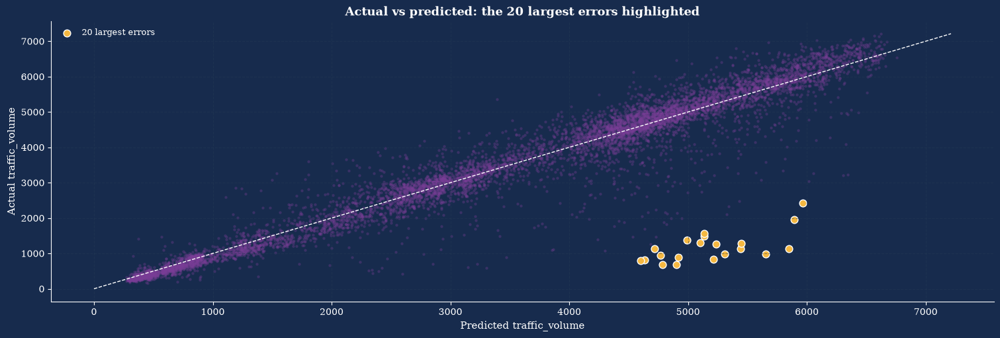

In [ ]:
# 4
# ---7)the 20 largest errors ----
worst = err.reindex(err["abs_error"].sort_values(ascending=False).index).head(20)
worst_table = pd.DataFrame({
    "weekday": worst["day_of_week"].map(dict(enumerate(DAY_NAMES))),
    "hour": worst["hour"],
    "actual": worst["actual"],
    "prediction": worst["prediction"].round(0),
    "error": worst["residual"].round(0),
    "holiday": worst["holiday"],
    "weather group": worst["weather_group"].astype(str),
})
display(worst_table)

days = worst.index.normalize().value_counts()
print("Calendar days that contain more than one of the 20 largest errors:")
print(days[days > 1].to_string() if (days > 1).any() else "none")
print(f"\n{int((worst['residual'] < 0).sum())} of the 20 are over-predictions (actual below prediction), "
      f"{int((worst['residual'] > 0).sum())} are under-predictions.")

# ---- chart: the worst days in context ----
fig, ax = plt.subplots(figsize=(15, 5), facecolor=THEME_BG, constrained_layout=True)
ax.scatter(err["prediction"], err["actual"], s=5, alpha=0.25, color=THEME_PURPLE)
ax.scatter(worst["prediction"], worst["actual"], s=60, color=THEME_ACCENT, edgecolor="white", label="20 largest errors")
limit = [0, max(err["actual"].max(), err["prediction"].max())]
ax.plot(limit, limit, color="white", lw=1, linestyle="--")
style_axes(ax, title="Actual vs predicted: the 20 largest errors highlighted",
           xlabel="Predicted traffic_volume", ylabel="Actual traffic_volume")
style_legend(ax)
plt.show()

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<h3>Analysis of the 20 Largest Prediction Errors</h3>
All 20 largest errors are over-predictions, indicating that the model substantially overestimates actual traffic volumes in these cases. Many of these errors occur during the morning hours (6:00–8:00) on federal holidays, suggesting that the model struggles to capture unusually low traffic volumes on these days. However, large errors also occur on non-holidays, indicating that holidays are not the only factor associated with extreme prediction errors.
</div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<h3>Conclusion</h3>
The final Random Forest model achieves an R² of 0.945, an MAE of 263.8, an RMSE of 463.7, and a WAPE of 8.0% on the test set. Compared with the best linear regression model (V4), it reduces RMSE by approximately 23.2% and MAE by 38.1%, indicating a clear improvement, although prediction errors remain under specific conditions.

<table style="width:100%; border-collapse:collapse; margin:10px 0; font-size:14px;">
<thead><tr style="background:#dbe4ef;"><th style="border:1px solid #b8c2cc; padding:7px; text-align:left;">Area</th><th style="border:1px solid #b8c2cc; padding:7px; text-align:left;">Key finding</th></tr></thead>
<tbody>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Federal holidays</b></td><td style="border:1px solid #b8c2cc; padding:7px;">Highest errors: MAE 1,085.6 and WAPE 46.7%, compared with 241.4 and 7.2% on other days.</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Largest errors</b></td><td style="border:1px solid #b8c2cc; padding:7px;">All 20 cases are over-predictions; many occur during morning hours on holidays.</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Time of day</b></td><td style="border:1px solid #b8c2cc; padding:7px;">Absolute errors peak at 07:00 and 16:00, while relative errors are highest during low-traffic nighttime hours.</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Weekday and season</b></td><td style="border:1px solid #b8c2cc; padding:7px;">Weekdays perform better than weekends; summer has the lowest seasonal errors, while winter has the highest.</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Weather</b></td><td style="border:1px solid #b8c2cc; padding:7px;">Reduced visibility has the highest error metrics among the weather groups.</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Traffic volume</b></td><td style="border:1px solid #b8c2cc; padding:7px;">Relative errors are highest below 1,000 vehicles, while the model tends to under-predict volumes of 5,000 or more.</td></tr>
</tbody>
</table>

Overall, the final model outperforms the linear V4 model, but its performance is not equally reliable across all conditions. The largest weakness is holiday traffic, followed by low-volume nighttime periods and reduced-visibility conditions. Testing additional holiday and contextual features through time-based validation may help determine whether these errors can be reduced further.
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.7 — Interpretation for a Non-Technical Reader</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.7 — Interpretation for a Non-Technical Reader</div>
<ul style="margin:0; padding-left:20px;">
<li style="margin-bottom:7px;"><b>How accurate is it?</b> On unseen test data, the final Random Forest model has an average absolute error of about <b>264 vehicles per hour</b>, with a WAPE of approximately <b>8%</b>. Its predictions are generally close to observed traffic, although accuracy varies across conditions.</li>
<li style="margin-bottom:7px;"><b>What does it learn?</b> Traffic volume follows strong daily and weekly patterns. Time-related features, especially the hour of the day and rush-hour patterns, are the most influential. Weather features contribute much less to the model's predictions overall.</li>
<li style="margin-bottom:7px;"><b>How much better is it than simpler models?</b> The tuned Random Forest achieves an RMSE of <b>463.7</b>, compared with <b>497.8</b> for the weekday-and-hour average baseline—a reduction of about <b>6.9%</b>. Compared with the best linear regression model (V4), it reduces RMSE by about <b>23.2%</b> and MAE by about <b>38.1%</b>. These improvements are meaningful, but the model still has limitations in specific situations.</li>
<li style="margin-bottom:7px;"><b>When should its predictions be treated cautiously?</b> The largest weakness is public holidays, when the model often predicts normal traffic levels and substantially overestimates actual volume. The 20 largest errors were all over-predictions, many occurring between 6:00 and 8:00 AM on holidays. Relative errors are also higher during low-volume hours, while reduced visibility and winter conditions are associated with less accurate predictions.</li>
</ul>
<p style="margin:10px 0 0 0;">Overall, the model captures routine traffic patterns well, but unusual calendar effects and atypical traffic conditions remain challenging. Further improvements should focus on these difficult cases rather than assuming that more complex modeling alone will guarantee substantially better forecasts.</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.8 — Limitations</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.8 — Limitations</div>
<ul style="margin:0; padding-left:20px;">
<li style="margin-bottom:4px;"><b>Missing hours:</b> Approximately 22.8% of the expected hours are missing, including a gap of about 10 months. No lag features were used, so the model cannot directly use traffic from previous hours.</li>
<li style="margin-bottom:4px;"><b>Single, outdated location:</b> The data cover one counting station and direction and end in September 2018. Results may not generalize to other locations or current traffic patterns.</li>
<li style="margin-bottom:4px;"><b>Limited test coverage:</b> The test period spans about 11 months, with few examples of some holidays and severe weather conditions. Results for these groups should therefore be interpreted cautiously.</li>
<li style="margin-bottom:4px;"><b>Long-term changes:</b> The tree models cannot reliably extrapolate long-term traffic trends beyond the patterns represented in training data.</li>
<li style="margin-bottom:4px;"><b>Excluded inputs and unexpected events:</b> Holiday information and detailed weather labels were not used as model inputs, while accidents, road closures and sensor failures were not explicitly represented.</li>
</ul>
<li style="margin-bottom:4px;"><b>Test-set reuse:</b> Although the data were split chronologically, test-set results were examined across multiple models and analyses. Therefore, the test metrics should not be treated as a fully independent final estimate of performance. A stronger final evaluation would use a separate holdout period that was not used for model selection or repeated comparisons.</li>
</ul>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.9 — Recommendations and Next Steps</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.9 — Recommendations and Next Steps</div>
<ul style="margin:0; padding-left:20px;">
<li style="margin-bottom:4px;"><b>Add a holiday indicator</b> and evaluate its impact: holidays account for 2.7% of test hours but approximately 11% of total absolute error.</li>
<li style="margin-bottom:4px;"><b>Test weather features with tree-based models</b>, particularly for reduced-visibility and snow conditions, where errors are higher.</li>
<li style="margin-bottom:4px;"><b>Explore lag features</b> such as traffic one hour and one day earlier, using only continuous historical data available at prediction time.</li>
<li style="margin-bottom:4px;"><b>Estimate prediction intervals</b> to communicate uncertainty, especially during holidays and unusual traffic conditions.</li>
<li style="margin-bottom:4px;"><b>Validate over longer periods</b> and, if possible, other locations to assess generalization across seasons and changing traffic patterns.</li>
</ul>
</div>

<div style="text-align:center; background:linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding:10px 15px; border-radius:10px; box-shadow:0 5px 15px rgba(20,25,70,0.35); font-family:'Segoe UI',sans-serif; margin:26px 0 12px 0;"><h3 style="color:#D8D6FF; font-family:'Georgia',serif; font-weight:bold; margin:0; letter-spacing:1px;">10.10 — Final Conclusion</h3></div>
<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.10 — Final conclusion</div>
<p style="margin:0 0 8px 0;"><b>Summary:</b> An hourly traffic forecasting model was developed for the Metro Interstate (I-94) dataset using <b>25 features</b> and a chronological split of <b>32,460 training hours</b> and <b>8,115 test hours</b>. Random Forest, XGBoost and LightGBM were tuned and compared using time-series cross-validation. <b>Random Forest was selected as the final model</b> because it achieved the lowest cross-validation RMSE, although the differences between the three models were small.</p>
<p style="margin:0 0 8px 0;"><b>Performance:</b> On the held-out test set, Random Forest achieved an R² of <b>0.9446</b>, an RMSE of <b>463.7</b>, an MAE of <b>263.8</b> and a WAPE of <b>8.0%</b>. Its RMSE was approximately <b>6.9% lower</b> than that of the weekday-and-hour average baseline and <b>23.2% lower</b> than that of the best linear regression model (V4). These results show meaningful improvement over V4, while also demonstrating that a simple temporal baseline already captures much of the recurring traffic pattern.</p>
<p style="margin:0 0 8px 0;"><b>Main findings:</b> Time-related features dominate the model's predictions. Its largest errors occur disproportionately on federal holidays, which account for approximately <b>2.7% of test hours but 11% of total absolute error</b>. All 20 largest errors were over-predictions, many occurring during early-morning holiday hours. Reduced visibility, winter conditions and low-volume periods are additional challenging cases.</p>
</div>